# Household trip generation: full-dataset EDA

The current analysis uses all 93,307 supplied households, without a training/test partition, following the revised project direction. The original workbook and historical split artifacts remain unchanged. All descriptive results below are regenerated from the full data; available-value denominators are explicit. Final regression variables, encoding, and exclusions remain decisions for the preparation review. Any later fit using these same data will describe in-sample fit, not held-out predictive performance.

Dictionary reconciliation: the supplied 2006 TTS Version 1.0 Data Guide, printed pages 18 and 51 (PDF pages 23 and 56), defines vehicles as 0-99 and tabulates 99 as a numeric value. The earlier provisional missing-value recode for 99 has been withdrawn. All recorded vehicle values are retained in the main EDA; unusually high counts are sensitivity flags. See Section 20 for source references and verification.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
from IPython.display import display as show, Image

## 1. Paths and settings

In [2]:
BASE_DIR = Path.cwd()
INPUTS = BASE_DIR / 'inputs'
INTERMEDIARIES = BASE_DIR / 'intermediaries'
FINAL_OUTPUTS = BASE_DIR / 'final_outputs'
TABLES = FINAL_OUTPUTS / 'tables'
FIGURES = FINAL_OUTPUTS / 'figures'
WORKBOOK = INPUTS / 'households.xlsx'
PREPARED_FILE = INTERMEDIARIES / 'households_prepared.csv'
SHEET = '2006-hhld'
FIGURE_DPI = 400

for folder in [INPUTS, INTERMEDIARIES, FINAL_OUTPUTS, TABLES, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

# Data fields and cleaning rules.
FIELDS = ['hnum', 'gta01hhld', 'dwelltype', 'rec-mail', 'n-call', 'tripday',
          'nperson', 'nvehicle', 'nlicence', 'nempft', 'nemppt', 'nemphome',
          'nstudent', 'nhhldtrip', 'expf']
ZONES = {'Toronto': (1, 481), 'Durham': (501, 765),
         'York': (1001, 1353), 'Peel': (1501, 1753)}
HIGH_VEHICLE = 10  # A sensitivity flag, not an exclusion from the main sample.
SIZE_TOP, VEHICLE_TOP, ALTERNATIVE_VEHICLE_TOP = 5, 3, 4

COUNTS = ['nperson', 'nvehicle_clean', 'nlicence', 'nempft', 'nemppt', 'nemphome', 'nstudent', 'workers']
COMPOSITION = ['nempft', 'nemppt', 'nemphome', 'nstudent']
LABELS = {
    'nperson': 'Household size', 'nvehicle': 'Vehicles available (raw; documented range 0-99)',
    'nvehicle_clean': 'Vehicles available',
    'nlicence': 'Licensed drivers', 'nempft': 'Full-time workers',
    'nemppt': 'Part-time workers', 'nemphome': 'Home workers',
    'nstudent': 'Students', 'workers': 'Total workers', 'expf': 'Expansion factor',
    'nhhldtrip': 'Weekday household trips', 'dwelling': 'Dwelling type',
    'weekday': 'Survey weekday', 'region': 'Region',
}
ORDERS = {
    'dwelling': ['House', 'Apartment', 'Townhouse', 'Unknown'],
    'weekday': ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'],
    'region': ['Toronto', 'Durham', 'York', 'Peel'],
}
SUPPORT_REVIEW_N = 30  # Review marker, never a deletion rule.

# Display settings.
# Display caps; exact counts remain unchanged.
CAPS = dict(zip(COUNTS, [8, 6, 6, 5, 3, 2, 5, 6]))
DRIVER_SIZE_TOP, DRIVER_TOP, DRIVER_ALTERNATIVE_TOP = 5, 4, 3
CROSS_CLASS_FIELDS = ['nperson', 'nlicence']
TRIP_CAP = 25

# Shared figure theme: brighter, publication-friendly colours with high-contrast text.
BLUE, VIOLET, ORANGE, AQUA = '#2F80ED', '#8B5CF6', '#F59E0B', '#14B8A6'
PINK = '#EC4899'
INK = '#243447'
COLOURS = {
    'nperson': BLUE, 'nvehicle_clean': AQUA, 'nlicence': '#06B6D4',
    'workers': VIOLET, 'nempft': VIOLET, 'nemppt': '#A855F7',
    'nemphome': PINK, 'nstudent': ORANGE,
    'dwelling': BLUE, 'weekday': AQUA, 'region': '#3B82F6',
}
MEAN_CMAP = LinearSegmentedColormap.from_list(
    'trip_rates', ['#FFF7ED', '#FDBA74', '#60A5FA', '#2563EB'])
COUNT_CMAP = LinearSegmentedColormap.from_list(
    'household_counts', ['#ECFDF5', '#5EEAD4', '#14B8A6', '#0F766E'])
CORR_CMAP = LinearSegmentedColormap.from_list(
    'correlations', ['#F59E0B', '#FFFDF5', '#60A5FA', '#2563EB'])
plt.rcdefaults()
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10, 'text.color': INK,
    'axes.labelcolor': INK, 'axes.titlecolor': INK,
    'xtick.color': INK, 'ytick.color': INK,
    'figure.facecolor': 'white', 'axes.facecolor': '#FBFDFF',
    'savefig.facecolor': 'white', 'lines.linewidth': 1.8,
})

def style_axes(ax):
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#B8CAE0')
    ax.grid(axis='y', color='#DDE8F5', linewidth=.7)
    ax.set_axisbelow(True)
    ax.tick_params(length=3, color='#9FB5CE')

def panel(ax, label):
    ax.text(0, 1.04, label, transform=ax.transAxes, ha='left', va='bottom',
            fontsize=10, fontweight='bold', color=INK)

## 2. Read the household data

In [3]:
raw = pd.read_excel(WORKBOOK, sheet_name=SHEET, usecols='B:P', dtype=object,
                    engine='openpyxl')
assert raw.columns.tolist() == FIELDS, 'The 15 fields in B:P differ from the expected schema.'
print(f'{len(raw):,} households; {len(FIELDS)} analytical fields; '
      f'{raw["gta01hhld"].nunique():,} residential zones.')
show(raw[['hnum', 'gta01hhld', 'nperson', 'nvehicle', 'dwelltype']].head())

93,307 households; 15 analytical fields; 1,179 residential zones.


,hnum,gta01hhld,nperson,nvehicle,dwelltype
0,209654,1,4,2,1
1,215249,1,2,2,2
2,216552,1,2,2,1
3,219744,1,3,2,1
4,226356,1,4,1,1


In [4]:
raw_dictionary = [
    ('hnum', 'Identifier', 'Household sample ID', 'Identifier only; not a predictor'),
    ('gta01hhld', 'Identifier', 'Residential zone in the 2001 system', 'Aggregation; not numeric predictor'),
    ('dwelltype', 'Category', '1 house; 2 apartment; 3 townhouse; 9 unknown', 'Candidate control'),
    ('rec-mail', 'Survey process', 'Y received letter; N did not; 9 unknown', 'Not a predictor'),
    ('n-call', 'Survey process', 'Calls or edits to complete interview', 'Not a predictor'),
    ('tripday', 'Category', '1 Monday through 5 Friday', 'Candidate control'),
    ('nperson', 'Count', 'All residents, including children under 11', 'Proposed core predictor'),
    ('nvehicle', 'Count', 'Personal-use vehicles; documented range 0-99; 99 tabulated numerically (guide pp. 18, 51)', 'Household characteristic'),
    ('nlicence', 'Count', 'Residents holding a driving licence', 'Cross-classification predictor'),
    ('nempft', 'Count', 'Full-time workers including home workers', 'Composition predictor'),
    ('nemppt', 'Count', 'Part-time workers including home workers', 'Composition predictor'),
    ('nemphome', 'Overlapping count', 'Home workers already inside full/part-time counts', 'Composition predictor'),
    ('nstudent', 'Count', 'Full/part-time students; includes ages 6-10; can overlap workers', 'Composition predictor'),
    ('nhhldtrip', 'Count', 'Recorded person trips on survey weekday; ages 11+', 'Outcome'),
    ('expf', 'Weight', 'Household expansion factor; positive', 'Weighting choice belongs to methodology'),
]
original_dictionary = pd.DataFrame(raw_dictionary, columns=['Field', 'Type', 'Definition', 'Role'])
show(original_dictionary)

,Field,Type,Definition,Role
0,hnum,Identifier,Household sample ID,Identifier only; not a predictor
1,gta01hhld,Identifier,Residential zone in the 2001 system,Aggregation; not numeric predictor
2,dwelltype,Category,1 house; 2 apartment; 3 townhouse; 9 unknown,Candidate control
3,rec-mail,Survey process,Y received letter; N did not; 9 unknown,Not a predictor
4,n-call,Survey process,Calls or edits to complete interview,Not a predictor
5,tripday,Category,1 Monday through 5 Friday,Candidate control
6,nperson,Count,"All residents, including children under 11",Proposed core predictor
7,nvehicle,Count,Personal-use vehicles; documented range 0-99; ...,Household characteristic
8,nlicence,Count,Residents holding a driving licence,Cross-classification predictor
9,nempft,Count,Full-time workers including home workers,Composition predictor


## 3. Data quality checks

In [5]:
checks = []

def record_check(name, count, kind='blocking', note=''):
    checks.append({'Check': name, 'Flagged records or cells': int(count),
                   'Status': kind, 'Note': note})

# Count blanks before any conversion of the mixed numeric/text rec-mail field.
blank = raw.isna() | raw.map(lambda value: isinstance(value, str) and not value.strip())
record_check('Blank cells in named fields', blank.sum().sum())
record_check('Duplicate household IDs', raw['hnum'].duplicated().sum())
record_check('Duplicate complete named records', raw.duplicated().sum())
raw_numeric = {}
bounds = {'hnum': (1, 999999), 'gta01hhld': (1, 999999), 'n-call': (1, None),
          'nperson': (1, 99), 'nvehicle': (0, 99), 'nlicence': (0, 9),
          'nempft': (0, 9), 'nemppt': (0, 9), 'nemphome': (0, 9),
          'nstudent': (0, 9), 'nhhldtrip': (0, 99)}
for field in FIELDS:
    if field == 'rec-mail':
        continue
    values = pd.to_numeric(raw[field], errors='coerce')
    raw_numeric[field] = values
    record_check(f'{field}: nonnumeric or nonfinite', (~np.isfinite(values)).sum())
    if field != 'expf':
        record_check(f'{field}: noninteger', (values.notna() & values.mod(1).ne(0)).sum())
    if field in bounds:
        low, high = bounds[field]
        bad = values.lt(low)
        if high is not None:
            bad |= values.gt(high)
        record_check(f'{field}: outside permitted audit range', bad.sum())
n = pd.DataFrame(raw_numeric, index=raw.index)
record_check('Nonpositive expansion factors', n['expf'].le(0).sum())
record_check('Unexpected dwelling code', (~n['dwelltype'].isin([1, 2, 3, 9])).sum())
record_check('Unexpected weekday code', (~n['tripday'].isin([1, 2, 3, 4, 5])).sum())
mail = raw['rec-mail'].astype('string')
record_check('Unexpected advance-letter code', (~mail.isin(['Y', 'N', '9'])).sum())
known_zone = pd.Series(False, index=raw.index)
for low, high in ZONES.values():
    known_zone |= n['gta01hhld'].between(low, high)
record_check('Zone outside documented study-region ranges', (~known_zone).sum())
workers = n['nempft'] + n['nemppt']
for name, bad in [
    ('Licences exceed residents', n['nlicence'] > n['nperson']),
    ('Students exceed residents', n['nstudent'] > n['nperson']),
    ('Workers exceed residents', workers > n['nperson']),
    ('Home workers exceed total workers', n['nemphome'] > workers),
]:
    record_check(name, bad.sum())
raw_checks = pd.DataFrame(checks)
failures = raw_checks[raw_checks['Flagged records or cells'] > 0]
assert failures.empty, 'Input checks require review: ' + '; '.join(failures['Check'])
raw_numeric = n
show(raw_checks)

,Check,Flagged records or cells,Status,Note
0,Blank cells in named fields,0,blocking,
1,Duplicate household IDs,0,blocking,
2,Duplicate complete named records,0,blocking,
3,hnum: nonnumeric or nonfinite,0,blocking,
4,hnum: noninteger,0,blocking,
5,hnum: outside permitted audit range,0,blocking,
6,gta01hhld: nonnumeric or nonfinite,0,blocking,
7,gta01hhld: noninteger,0,blocking,
8,gta01hhld: outside permitted audit range,0,blocking,
9,dwelltype: nonnumeric or nonfinite,0,blocking,


## 4. Supplied data description

In [6]:
zone_counts = raw.groupby('gta01hhld').size()
structure = pd.DataFrame([
    ('Households supplied', len(raw)),
    ('Analytical fields', len(FIELDS)),
    ('Residential zones', len(zone_counts)),
    ('Blank cells in analytical fields', int(raw.isna().sum().sum())),
    ('Duplicate household IDs', int(raw['hnum'].duplicated().sum())),
    ('Smallest zone sample', int(zone_counts.min())),
    ('Median zone sample', float(zone_counts.median())),
    ('Largest zone sample', int(zone_counts.max())),
    ('Zones with fewer than 5 households', int(zone_counts.lt(5).sum())),
], columns=['Description', 'Value'])

vehicle_values = raw_numeric['nvehicle']
known_vehicles = vehicle_values.notna()  # Guide pp. 18, 51: 99 is a recorded numeric value.
vehicle_frequencies = (vehicle_values[known_vehicles].astype(int).value_counts()
                       .sort_index().rename_axis('raw_vehicle_count').reset_index(name='households'))
vehicle_frequencies['source_records'] = len(raw)
vehicle_frequencies['numeric_plot_records'] = int(known_vehicles.sum())

category_rows = []
for field in ['dwelltype', 'rec-mail', 'tripday']:
    for value, count in raw[field].astype('string').value_counts().sort_index().items():
        category_rows.append({'field': field, 'raw_code_display': value,
                              'households': count, 'source_records': len(raw)})
raw_categories = pd.DataFrame(category_rows)
show(structure)
show(raw_categories)
structure.to_csv(TABLES / 'Data_structure.csv', index=False)
vehicle_frequencies.to_csv(TABLES / 'PS09_vehicle_frequencies.csv', index=False)
raw_categories.to_csv(TABLES / 'PS10_categorical_frequencies.csv', index=False)

,Description,Value
0,Households supplied,93307.0
1,Analytical fields,15.0
2,Residential zones,1179.0
3,Blank cells in analytical fields,0.0
4,Duplicate household IDs,0.0
5,Smallest zone sample,1.0
6,Median zone sample,72.0
7,Largest zone sample,502.0
8,Zones with fewer than 5 households,149.0


,field,raw_code_display,households,source_records
0,dwelltype,1,58360,93307
1,dwelltype,2,27977,93307
2,dwelltype,3,6961,93307
3,dwelltype,9,9,93307
4,rec-mail,9,576,93307
5,rec-mail,N,47054,93307
6,rec-mail,Y,45677,93307
7,tripday,1,16652,93307
8,tripday,2,18273,93307
9,tripday,3,17728,93307


### Pre-cleaning numeric descriptives

These summaries use all supplied households. Vehicle values 0-99 are retained as numeric measurements, following the 2006 TTS guide (printed pp. 18 and 51). The guide does not identify 99 as an unknown-vehicle code. No training/test partition is used.

In [7]:
def descriptive(values):
    """Numeric descriptives using all finite, nonmissing values supplied to the function."""
    x = pd.to_numeric(values, errors='coerce').dropna().to_numpy(dtype=float)
    return {'n': len(x), 'mean': x.mean(), 'sd': x.std(ddof=1), 'minimum': x.min(),
            'p25': np.quantile(x, .25), 'median': np.median(x),
            'p75': np.quantile(x, .75), 'maximum': x.max(),
            'zero_n': int((x == 0).sum()), 'zero_pct': 100 * (x == 0).mean()}

# Match the later ED02 descriptive layout, but use the entire source file before cleaning
# with no partition or eligibility exclusion. Workers are a transparent arithmetic
# derivation (full-time + part-time); no records are filtered for this table.
raw_descriptive_data = raw_numeric.copy()
raw_descriptive_data['workers'] = raw_numeric['nempft'] + raw_numeric['nemppt']
RAW_DESCRIPTIVE_FIELDS = [
    'nperson', 'nvehicle', 'nlicence', 'nempft', 'nemppt', 'nemphome',
    'nstudent', 'workers', 'expf', 'nhhldtrip'
]
raw_numeric_rows = [
    {'sample': 'Raw supplied data', 'variable': field, 'characteristic': LABELS[field],
     **descriptive(raw_descriptive_data[field])}
    for field in RAW_DESCRIPTIVE_FIELDS
]
raw_numeric_descriptives = pd.DataFrame(raw_numeric_rows)
raw_numeric_descriptives.to_csv(
    TABLES / 'DP00_raw_numeric_descriptives.csv', index=False, encoding='utf-8-sig',
    lineterminator='\n', float_format='%.10g')
show(raw_numeric_descriptives)

,sample,variable,characteristic,n,mean,sd,minimum,p25,median,p75,maximum,zero_n,zero_pct
0,Raw supplied data,nperson,Household size,93307,2.741177,1.418985,1.00,2.00,2.00,4.00,16.00,0,0.000000
1,Raw supplied data,nvehicle,Vehicles available (raw; documented range 0-99),93307,1.383347,1.025687,0.00,1.00,1.00,2.00,99.00,15295,16.392125
2,Raw supplied data,nlicence,Licensed drivers,93307,1.730095,0.982728,0.00,1.00,2.00,2.00,9.00,8964,9.606996
3,Raw supplied data,nempft,Full-time workers,93307,1.113025,0.926627,0.00,0.00,1.00,2.00,7.00,27902,29.903437
4,Raw supplied data,nemppt,Part-time workers,93307,0.238235,0.511955,0.00,0.00,0.00,0.00,5.00,74410,79.747500
5,Raw supplied data,nemphome,Home workers,93307,0.108041,0.354863,0.00,0.00,0.00,0.00,7.00,84512,90.574126
6,Raw supplied data,nstudent,Students,93307,0.635151,0.953827,0.00,0.00,0.00,1.00,9.00,57826,61.973914
7,Raw supplied data,workers,Total workers,93307,1.351260,1.049564,0.00,1.00,1.00,2.00,10.00,22980,24.628377
8,Raw supplied data,expf,Expansion factor,93307,19.383845,2.508741,10.83,17.67,19.35,20.98,28.06,0,0.000000
9,Raw supplied data,nhhldtrip,Weekday household trips,93307,5.643253,4.562479,0.00,2.00,4.00,8.00,55.00,10480,11.231740


### Vehicle frequencies

In [8]:
def save_figure(fig, name):
    """Save a 400-dpi PNG and display it in the notebook."""
    path = FIGURES / f'{name}.png'
    fig.savefig(path, dpi=FIGURE_DPI, facecolor='white')
    plt.close(fig)
    show(Image(filename=str(path), width=1000))

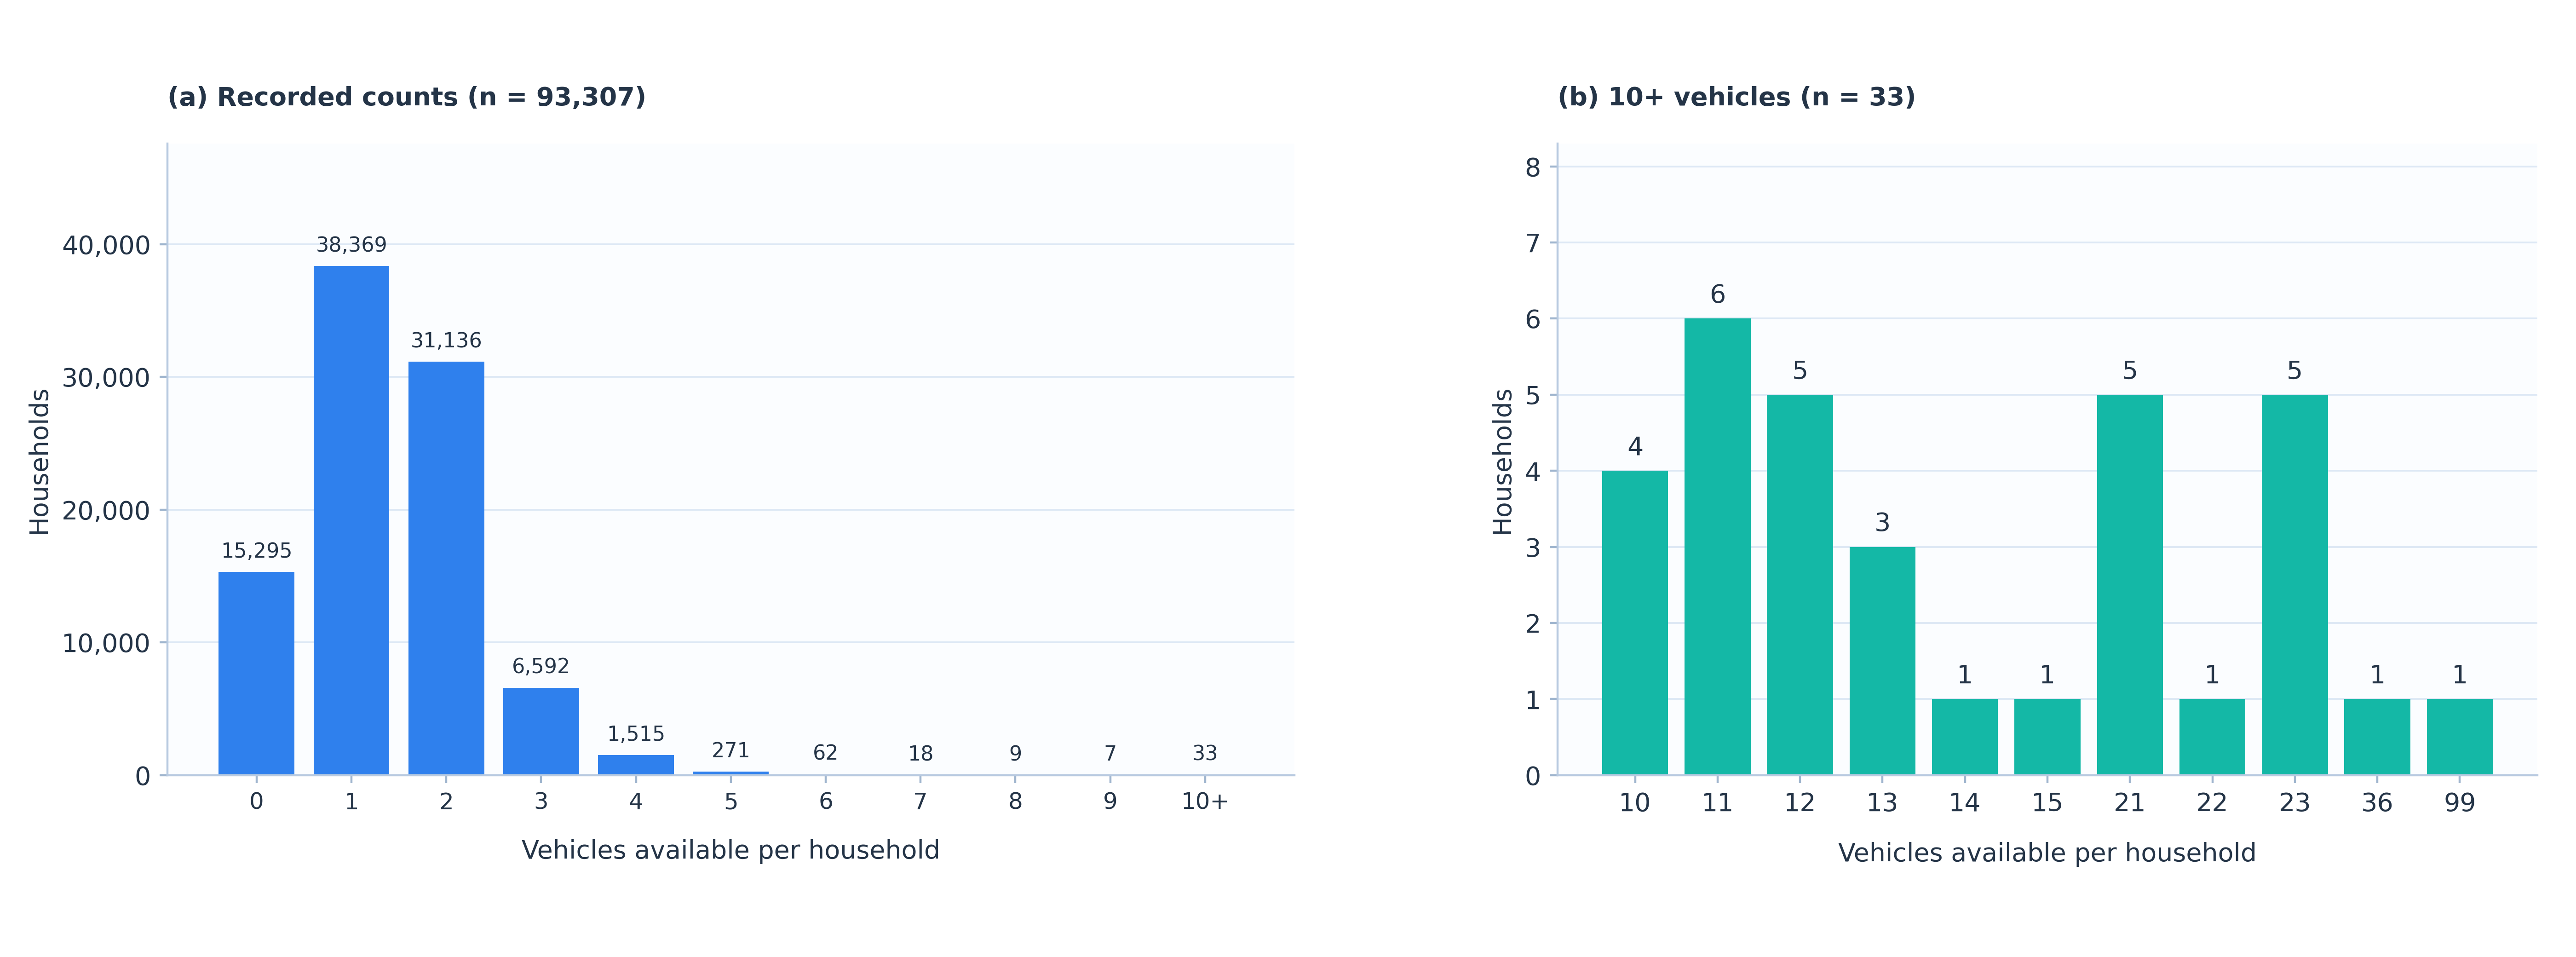

In [9]:
stats = {'vehicle_numeric_plot_records': int(known_vehicles.sum()),
         'vehicle_numeric_99_review': int(vehicle_values.eq(99).sum()),
         'source_records': len(raw), 'vehicle_other_unplotted_records': 0}
counts = vehicle_frequencies.set_index("raw_vehicle_count")["households"]
tail = counts[counts.index >= HIGH_VEHICLE]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
fig.subplots_adjust(left=.065, right=.985, bottom=.19, top=.85, wspace=.25)
main_values = [int(counts.get(k, 0)) for k in range(HIGH_VEHICLE)] + [int(tail.sum())]
bars = axes[0].bar(range(len(main_values)), main_values, color=BLUE)
axes[0].set_xticks(range(len(main_values)), [str(k) for k in range(HIGH_VEHICLE)] + ["10+"])
axes[0].tick_params(axis="x", labelsize=9)
axes[0].bar_label(bars, labels=[f"{v:,}" if v else "" for v in main_values], padding=4, fontsize=8, rotation=0)
axes[0].set_ylim(0, max(main_values, default=1) * 1.24 + 1)
axes[0].set_title(
    f"(a) Recorded counts (n = {int(stats['vehicle_numeric_plot_records']):,})",
    loc="left", fontsize=10, fontweight="bold", color=INK, pad=15,
)
axes[0].set_xlabel("Vehicles available per household", labelpad=10)
axes[0].set_ylabel("Households")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
if not tail.empty:
    positions = np.arange(len(tail))
    bars = axes[1].bar(positions, tail.values, color=AQUA)
    axes[1].set_xticks(positions, [str(v) for v in tail.index])
    axes[1].bar_label(bars, padding=4, fontsize=10)
    axes[1].set_ylim(0, float(tail.max()) * 1.3 + .5)
else:
    axes[1].text(.5, .5, "No numerical values of 10 or more", ha="center", transform=axes[1].transAxes)
    axes[1].set_xticks([])
axes[1].set_title(
    f"(b) 10+ vehicles (n = {int(tail.sum()):,})",
    loc="left", fontsize=10, fontweight="bold", color=INK, pad=15,
)
axes[1].set_xlabel("Vehicles available per household", labelpad=10)
axes[1].set_ylabel("Households")
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))
for ax in axes:
    style_axes(ax)

save_figure(fig, 'S1_vehicle_frequencies')

## 5. Data cleaning

In [10]:
def category(counts, top):
    """Create text categories while preserving missing values as missing."""
    result = counts.astype('Int64').astype('string')
    return result.mask(counts.ge(top).fillna(False), f'{top}+')

master = raw.copy()
# Source order is retained so each numeric series still refers to its raw row.
n = raw_numeric.reset_index(drop=True)
master['vehicle_99_review'] = n['nvehicle'].eq(99)
master['unknown_dwelling'] = n['dwelltype'].eq(9)
master['unknown_advance_letter'] = raw['rec-mail'].astype('string').eq('9').to_numpy()
master['nvehicle_clean'] = n['nvehicle'].astype('Int64')  # Retain 99; guide pp. 18, 51.
master['dwelltype_clean'] = n['dwelltype'].mask(master['unknown_dwelling']).astype('Int64')
master['rec_mail_clean'] = raw['rec-mail'].astype('string').mask(master['unknown_advance_letter'])
master['workers'] = (n['nempft'] + n['nemppt']).astype('Int64')
master['high_vehicle'] = master['nvehicle_clean'].ge(HIGH_VEHICLE).fillna(False)
master['zero_trip'] = n['nhhldtrip'].eq(0)
master['home_double_count_exceeds_size'] = master['workers'] + n['nemphome'] > n['nperson']
master['workers_students_exceed_size'] = master['workers'] + n['nstudent'] > n['nperson']
master['eligible_core'] = master['nvehicle_clean'].notna()
# Completeness flags describe possible future model samples, not EDA exclusions.
# No final regression eligibility rule has been selected.
master['eligible_comparison'] = master['eligible_core'] & ~master['unknown_dwelling']
master['eligible_high_vehicle_sensitivity'] = master['eligible_comparison'] & ~master['high_vehicle']
master['ineligible_core_reason'] = np.where(~master['eligible_core'], 'missing_vehicle_value', '')
master['ineligible_comparison_reason'] = [
    ';'.join(reason for flag, reason in [(v, 'missing_vehicle_value'), (d, 'unknown_dwelling')] if flag)
    for v, d in zip(~master['eligible_core'], master['unknown_dwelling'])]
master['size_cat_proposed'] = category(n['nperson'], SIZE_TOP)
master['veh_cat_proposed'] = category(master['nvehicle_clean'], VEHICLE_TOP)
master['veh_cat_alternative'] = category(master['nvehicle_clean'], ALTERNATIVE_VEHICLE_TOP)
master['dwelling'] = n['dwelltype'].map({1: 'House', 2: 'Apartment', 3: 'Townhouse', 9: 'Unknown'})
master['weekday'] = n['tripday'].map(dict(enumerate(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'], start=1)))
master['region'] = ''
for name, (low, high) in ZONES.items():
    master.loc[n['gta01hhld'].between(low, high), 'region'] = name

analysis = master.copy()
print(f'Full-dataset EDA: {len(analysis):,} households retained; no rows excluded.')
print(f'Unavailable values: {master["nvehicle_clean"].isna().sum():,} vehicle count; '
      f'{master["unknown_dwelling"].sum():,} dwelling codes retained as Unknown.')
assert len(analysis) == len(raw), 'EDA must retain every supplied household.'

Full-dataset EDA: 93,307 households retained; no rows excluded.
Unavailable values: 0 vehicle count; 9 dwelling codes retained as Unknown.


## 6. Full-dataset analysis and preserved historical files

All supplied households are used for EDA, with available-value denominators for each variable. The original workbook and historical split assignment, training, testing, and split-summary files are preserved without modification. They are not read or used to select the current analysis sample. Existing completeness flags are diagnostic only; final modeling exclusions remain undecided.

In [11]:
assert master[FIELDS].equals(raw.reset_index(drop=True)), 'Original fields changed during preparation.'
master.to_csv(PREPARED_FILE, index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.15g')
show(pd.DataFrame({'Sample': ['Full supplied dataset'], 'Households': [len(analysis)],
                   'Rows excluded from EDA': [0]}))

,Sample,Households,Rows excluded from EDA
0,Full supplied dataset,93307,0


### Derived variables and preparation flags

In [12]:
derived = {
    'nvehicle_clean': 'Numeric copy of nvehicle; all values 0-99 retained, including 99; guide pp. 18, 51',
    'dwelltype_clean': 'dwelltype with unknown 9 set to missing',
    'rec_mail_clean': 'Advance-letter text with unknown 9 set to missing',
    'workers': 'nempft + nemppt; home workers are not added again',
    'vehicle_99_review': 'Raw nvehicle equals 99; documented numeric value retained, flagged only for leverage/sensitivity review',
    'unknown_dwelling': 'Raw dwelltype equals 9',
    'unknown_advance_letter': 'Raw rec-mail equals code 9; no eligibility exclusion',
    'high_vehicle': 'Known vehicle count at least 10; flag, not automatic deletion',
    'zero_trip': 'Recorded trips equal zero; retain',
    'home_double_count_exceeds_size': 'workers + nemphome exceeds nperson; informational',
    'workers_students_exceed_size': 'workers + nstudent exceeds nperson; overlapping statuses',
    'eligible_core': 'Known vehicles; provisional completeness flag only',
    'eligible_comparison': 'Known vehicles and dwelling; provisional complete-case flag only',
    'eligible_high_vehicle_sensitivity': 'Known vehicles/dwelling and fewer than 10 vehicles; sensitivity flag only',
    'ineligible_core_reason': 'Reason vehicle completeness flag is false; not a final exclusion',
    'ineligible_comparison_reason': 'Completeness issues separated by semicolon; not final exclusions',
    'size_cat_proposed': '1,2,3,4,5+; proposal for EDA, not a final model boundary',
    'veh_cat_proposed': '0,1,2,3+; all recorded vehicle values included',
    'veh_cat_alternative': '0,1,2,3,4+; all recorded vehicle values included',
    'dwelling': 'Descriptive label, including Unknown; not numeric model coding',
    'weekday': 'Descriptive Monday-Friday label',
    'region': 'Region inferred from documented zone ranges',
}

derived_dictionary = pd.DataFrame([
    {'Field': field,
     'Type': 'Flag' if pd.api.types.is_bool_dtype(master[field]) else 'Derived',
     'Definition': definition, 'Role': 'Preparation or analysis'}
    for field, definition in derived.items()
])
dictionary = pd.concat([original_dictionary, derived_dictionary], ignore_index=True)
dictionary.to_csv(TABLES / 'DP01_data_dictionary.csv', index=False)
show(derived_dictionary[['Field', 'Definition']])

,Field,Definition
0,nvehicle_clean,Numeric copy of nvehicle; all values 0-99 reta...
1,dwelltype_clean,dwelltype with unknown 9 set to missing
2,rec_mail_clean,Advance-letter text with unknown 9 set to missing
3,workers,nempft + nemppt; home workers are not added again
4,vehicle_99_review,Raw nvehicle equals 99; documented numeric val...
5,unknown_dwelling,Raw dwelltype equals 9
6,unknown_advance_letter,Raw rec-mail equals code 9; no eligibility exc...
7,high_vehicle,"Known vehicle count at least 10; flag, not aut..."
8,zero_trip,Recorded trips equal zero; retain
9,home_double_count_exceeds_size,workers + nemphome exceeds nperson; informational


In [13]:
FLAG_DECISIONS = {
    'vehicle_99_review': 'Retained as numeric 99 under the source guide; high-count review only; no missing-value exclusion',
    'unknown_dwelling': 'Retained as Unknown in full EDA; model handling undecided',
    'unknown_advance_letter': 'Retained; survey-process field is not a substantive predictor',
    'high_vehicle': 'Retained in main samples; flagged for a possible later sensitivity check',
    'zero_trip': 'Retained; no exclusion based on zero trips',
    'home_double_count_exceeds_size': 'Retained; do not add home workers to full- and part-time totals',
    'workers_students_exceed_size': 'Retained; employment and student statuses may overlap',
}

flags = ['vehicle_99_review', 'unknown_dwelling', 'unknown_advance_letter',
         'high_vehicle', 'zero_trip', 'home_double_count_exceeds_size', 'workers_students_exceed_size']
flag_table = pd.DataFrame([{'Flag': f, 'Households': int(master[f].sum()),
                            'Definition': derived[f], 'Decision': FLAG_DECISIONS[f]} for f in flags])
extra_checks = pd.DataFrame([{'Check': r.Flag, 'Flagged records or cells': r.Households,
                              'Status': 'handling recorded',
                              'Note': r.Definition, 'Decision': r.Decision} for r in flag_table.itertuples()])
raw_checks = raw_checks.assign(Decision='Stop before writing if this check is nonzero')
checks = pd.concat([raw_checks, extra_checks], ignore_index=True)

show(flag_table[['Flag', 'Households', 'Decision']])
checks.to_csv(INTERMEDIARIES / 'DP02_quality_checks.csv', index=False)
flag_table.to_csv(INTERMEDIARIES / 'DP05_preparation_flags.csv', index=False)

,Flag,Households,Decision
0,vehicle_99_review,1,Retained as numeric 99 under the source guide;...
1,unknown_dwelling,9,Retained as Unknown in full EDA; model handlin...
2,unknown_advance_letter,576,Retained; survey-process field is not a substa...
3,high_vehicle,33,Retained in main samples; flagged for a possib...
4,zero_trip,10480,Retained; no exclusion based on zero trips
5,home_double_count_exceeds_size,3702,Retained; do not add home workers to full- and...
6,workers_students_exceed_size,6533,Retained; employment and student statuses may ...


## 7. Sample flow

In [14]:
masks = {
    'Full dataset (main EDA)': pd.Series(True, index=master.index),
    'Known vehicle count (diagnostic only)': master['eligible_core'],
    'Known vehicle and dwelling (diagnostic only)': master['eligible_comparison'],
    'Known vehicle/dwelling, fewer than 10 vehicles (sensitivity only)': master['eligible_high_vehicle_sensitivity'],
}
sample_summary = pd.DataFrame([
    {'Cohort': name, 'Households': int(mask.sum()),
     'Zones represented': master.loc[mask, 'gta01hhld'].nunique(),
     'Use': 'Main EDA; no exclusions' if name.startswith('Full') else 'Provisional diagnostic; not a final model sample'}
    for name, mask in masks.items()
])
flow = pd.DataFrame([
    ('Supplied households', len(raw), 'Original workbook preserved'),
    ('Prepared master and main EDA', len(master), 'All supplied rows retained; unknowns recoded or labeled'),
    ('Unavailable vehicle count', int(master['nvehicle_clean'].isna().sum()), 'No vehicle missingness is inferred from code 99'),
    ('Unknown dwelling code', int(master['unknown_dwelling'].sum()), 'Shown as Unknown; no row exclusion'),
    ('High vehicle count', int(master['high_vehicle'].sum()), 'Retained; sensitivity analysis only'),
], columns=['View or issue', 'Households', 'Handling'])
zones = master.groupby('gta01hhld', sort=True).agg(
    households=('hnum', 'size'), known_vehicle_households=('nvehicle_clean', 'count'),
    known_dwelling_households=('dwelltype_clean', 'count'))
zones['both_known_households'] = master.loc[master['eligible_comparison']].groupby('gta01hhld').size().reindex(zones.index, fill_value=0)
show(flow)
show(sample_summary)
flow.to_csv(TABLES / 'DP03_sample_flow.csv', index=False)
sample_summary.to_csv(TABLES / 'DP04_sample_summary.csv', index=False)
zones.reset_index().to_csv(INTERMEDIARIES / 'DP06_zone_coverage.csv', index=False)

,View or issue,Households,Handling
0,Supplied households,93307,Original workbook preserved
1,Prepared master and main EDA,93307,All supplied rows retained; unknowns recoded o...
2,Unavailable vehicle count,0,No vehicle missingness is inferred from code 99
3,Unknown dwelling code,9,Shown as Unknown; no row exclusion
4,High vehicle count,33,Retained; sensitivity analysis only


,Cohort,Households,Zones represented,Use
0,Full dataset (main EDA),93307,1179,Main EDA; no exclusions
1,Known vehicle count (diagnostic only),93307,1179,Provisional diagnostic; not a final model sample
2,Known vehicle and dwelling (diagnostic only),93298,1179,Provisional diagnostic; not a final model sample
3,"Known vehicle/dwelling, fewer than 10 vehicles...",93265,1179,Provisional diagnostic; not a final model sample


### EDA sample and denominators

The main sample contains every supplied household. Numeric summaries use nonmissing values for that variable. Dwelling Unknown is displayed explicitly. Joint analyses involving vehicles require a known vehicle count and state that denominator separately. No final modeling sample is selected here.

In [15]:
tables = {'ED01_sample_reconciliation': sample_summary}
print(f'Characteristics and trip EDA: {len(analysis):,} households, with no training/test partition.')
assert set(analysis['hnum']) == set(raw['hnum']), 'The full household sample must be retained.'

Characteristics and trip EDA: 93,307 households, with no training/test partition.


## 8. Expected relationships

In [16]:
EXPECTATIONS = {
    'nperson': ('Generally positive; increments need not be constant', 'Literature supported'),
    'nvehicle_clean': ('Generally positive; increments need not be constant', 'Literature supported'),
    'nlicence': ('Generally positive through mobility access', 'Reasoned'),
    'nempft': ('Generally positive for total trips, with possible offsets', 'Partly reasoned'),
    'nemppt': ('Generally positive for total trips, with possible offsets', 'Partly reasoned'),
    'nemphome': ('No direction conditional on full-time and part-time counts', 'No signed expectation'),
    'nstudent': ('Generally positive through education and escort needs', 'Reasoned'),
    'dwelling': ('No predetermined ranking', 'No signed expectation'),
    'weekday': ('No predetermined ranking', 'No signed expectation'),
}
show(pd.DataFrame.from_dict(EXPECTATIONS, orient='index', columns=['Expectation', 'Basis']))

,Expectation,Basis
nperson,Generally positive; increments need not be con...,Literature supported
nvehicle_clean,Generally positive; increments need not be con...,Literature supported
nlicence,Generally positive through mobility access,Reasoned
nempft,"Generally positive for total trips, with possi...",Partly reasoned
nemppt,"Generally positive for total trips, with possi...",Partly reasoned
nemphome,No direction conditional on full-time and part...,No signed expectation
nstudent,Generally positive through education and escor...,Reasoned
dwelling,No predetermined ranking,No signed expectation
weekday,No predetermined ranking,No signed expectation


## 9. Descriptive statistics

In [17]:
def capped(series, cap):
    return series.clip(upper=cap).astype('Int64')


def ticks(values, cap):
    return [f'{v}+' if v == cap else str(v) for v in values]

In [18]:
numeric_rows, profiles = [], []
cohorts = {'Full dataset (available values)': analysis}
for sample, frame in cohorts.items():
    for field in COUNTS + ['expf']:
        numeric_rows.append({'sample': sample, 'variable': field, 'characteristic': LABELS[field],
                        **descriptive(frame[field])})
    for field in COUNTS + list(ORDERS):
        counts = frame[field].value_counts().sort_index()
        if field in ORDERS:
            counts = counts.reindex(ORDERS[field], fill_value=0)
        profiles.extend({'sample': sample, 'variable': field, 'characteristic': LABELS[field],
                         'level': str(level), 'n': int(n), 'percent': 100 * n / len(frame),
                         'source_n': len(frame), 'available_n': int(frame[field].notna().sum()),
                         'missing_n': int(frame[field].isna().sum())}
                        for level, n in counts.items())

tables['ED02_numeric_descriptives'] = pd.DataFrame(numeric_rows)
tables['ED02_numeric_descriptives'].to_csv(TABLES / 'ED02_numeric_descriptives.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
tables['ED03_characteristic_profiles'] = pd.DataFrame(profiles)
tables['ED03_characteristic_profiles'].to_csv(TABLES / 'ED03_characteristic_profiles.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
show(tables['ED02_numeric_descriptives'])
show(tables['ED03_characteristic_profiles'].head(15))

,sample,variable,characteristic,n,mean,sd,minimum,p25,median,p75,maximum,zero_n,zero_pct
0,Full dataset (available values),nperson,Household size,93307,2.741177,1.418985,1.00,2.00,2.00,4.00,16.00,0,0.000000
1,Full dataset (available values),nvehicle_clean,Vehicles available,93307,1.383347,1.025687,0.00,1.00,1.00,2.00,99.00,15295,16.392125
2,Full dataset (available values),nlicence,Licensed drivers,93307,1.730095,0.982728,0.00,1.00,2.00,2.00,9.00,8964,9.606996
3,Full dataset (available values),nempft,Full-time workers,93307,1.113025,0.926627,0.00,0.00,1.00,2.00,7.00,27902,29.903437
4,Full dataset (available values),nemppt,Part-time workers,93307,0.238235,0.511955,0.00,0.00,0.00,0.00,5.00,74410,79.747500
5,Full dataset (available values),nemphome,Home workers,93307,0.108041,0.354863,0.00,0.00,0.00,0.00,7.00,84512,90.574126
6,Full dataset (available values),nstudent,Students,93307,0.635151,0.953827,0.00,0.00,0.00,1.00,9.00,57826,61.973914
7,Full dataset (available values),workers,Total workers,93307,1.351260,1.049564,0.00,1.00,1.00,2.00,10.00,22980,24.628377
8,Full dataset (available values),expf,Expansion factor,93307,19.383845,2.508741,10.83,17.67,19.35,20.98,28.06,0,0.000000


,sample,variable,characteristic,level,n,percent,source_n,available_n,missing_n
0,Full dataset (available values),nperson,Household size,1,19200,20.577234,93307,93307,0
1,Full dataset (available values),nperson,Household size,2,28820,30.887286,93307,93307,0
2,Full dataset (available values),nperson,Household size,3,17476,18.729570,93307,93307,0
3,Full dataset (available values),nperson,Household size,4,17472,18.725283,93307,93307,0
4,Full dataset (available values),nperson,Household size,5,7002,7.504260,93307,93307,0
5,Full dataset (available values),nperson,Household size,6,2326,2.492846,93307,93307,0
6,Full dataset (available values),nperson,Household size,7,662,0.709486,93307,93307,0
7,Full dataset (available values),nperson,Household size,8,221,0.236853,93307,93307,0
8,Full dataset (available values),nperson,Household size,9,70,0.075021,93307,93307,0
9,Full dataset (available values),nperson,Household size,10,36,0.038582,93307,93307,0


In [19]:
caps = [{'variable': f, 'last_category': f'{CAPS[f]} or more',
         'full_dataset_n_in_last_category': int(analysis[f].ge(CAPS[f]).sum()),
         'purpose': 'Display only; exact counts retained; no model boundary fixed'} for f in COUNTS]
caps.append({'variable': 'nhhldtrip', 'last_category': f'{TRIP_CAP} or more',
             'full_dataset_n_in_last_category': int(analysis['nhhldtrip'].ge(TRIP_CAP).sum()),
             'purpose': 'Distribution display only; summaries use original trip counts'})
tables['ED13_display_boundaries'] = pd.DataFrame(caps)
tables['ED13_display_boundaries'].to_csv(INTERMEDIARIES / 'ED13_display_boundaries.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')

### Household characteristics

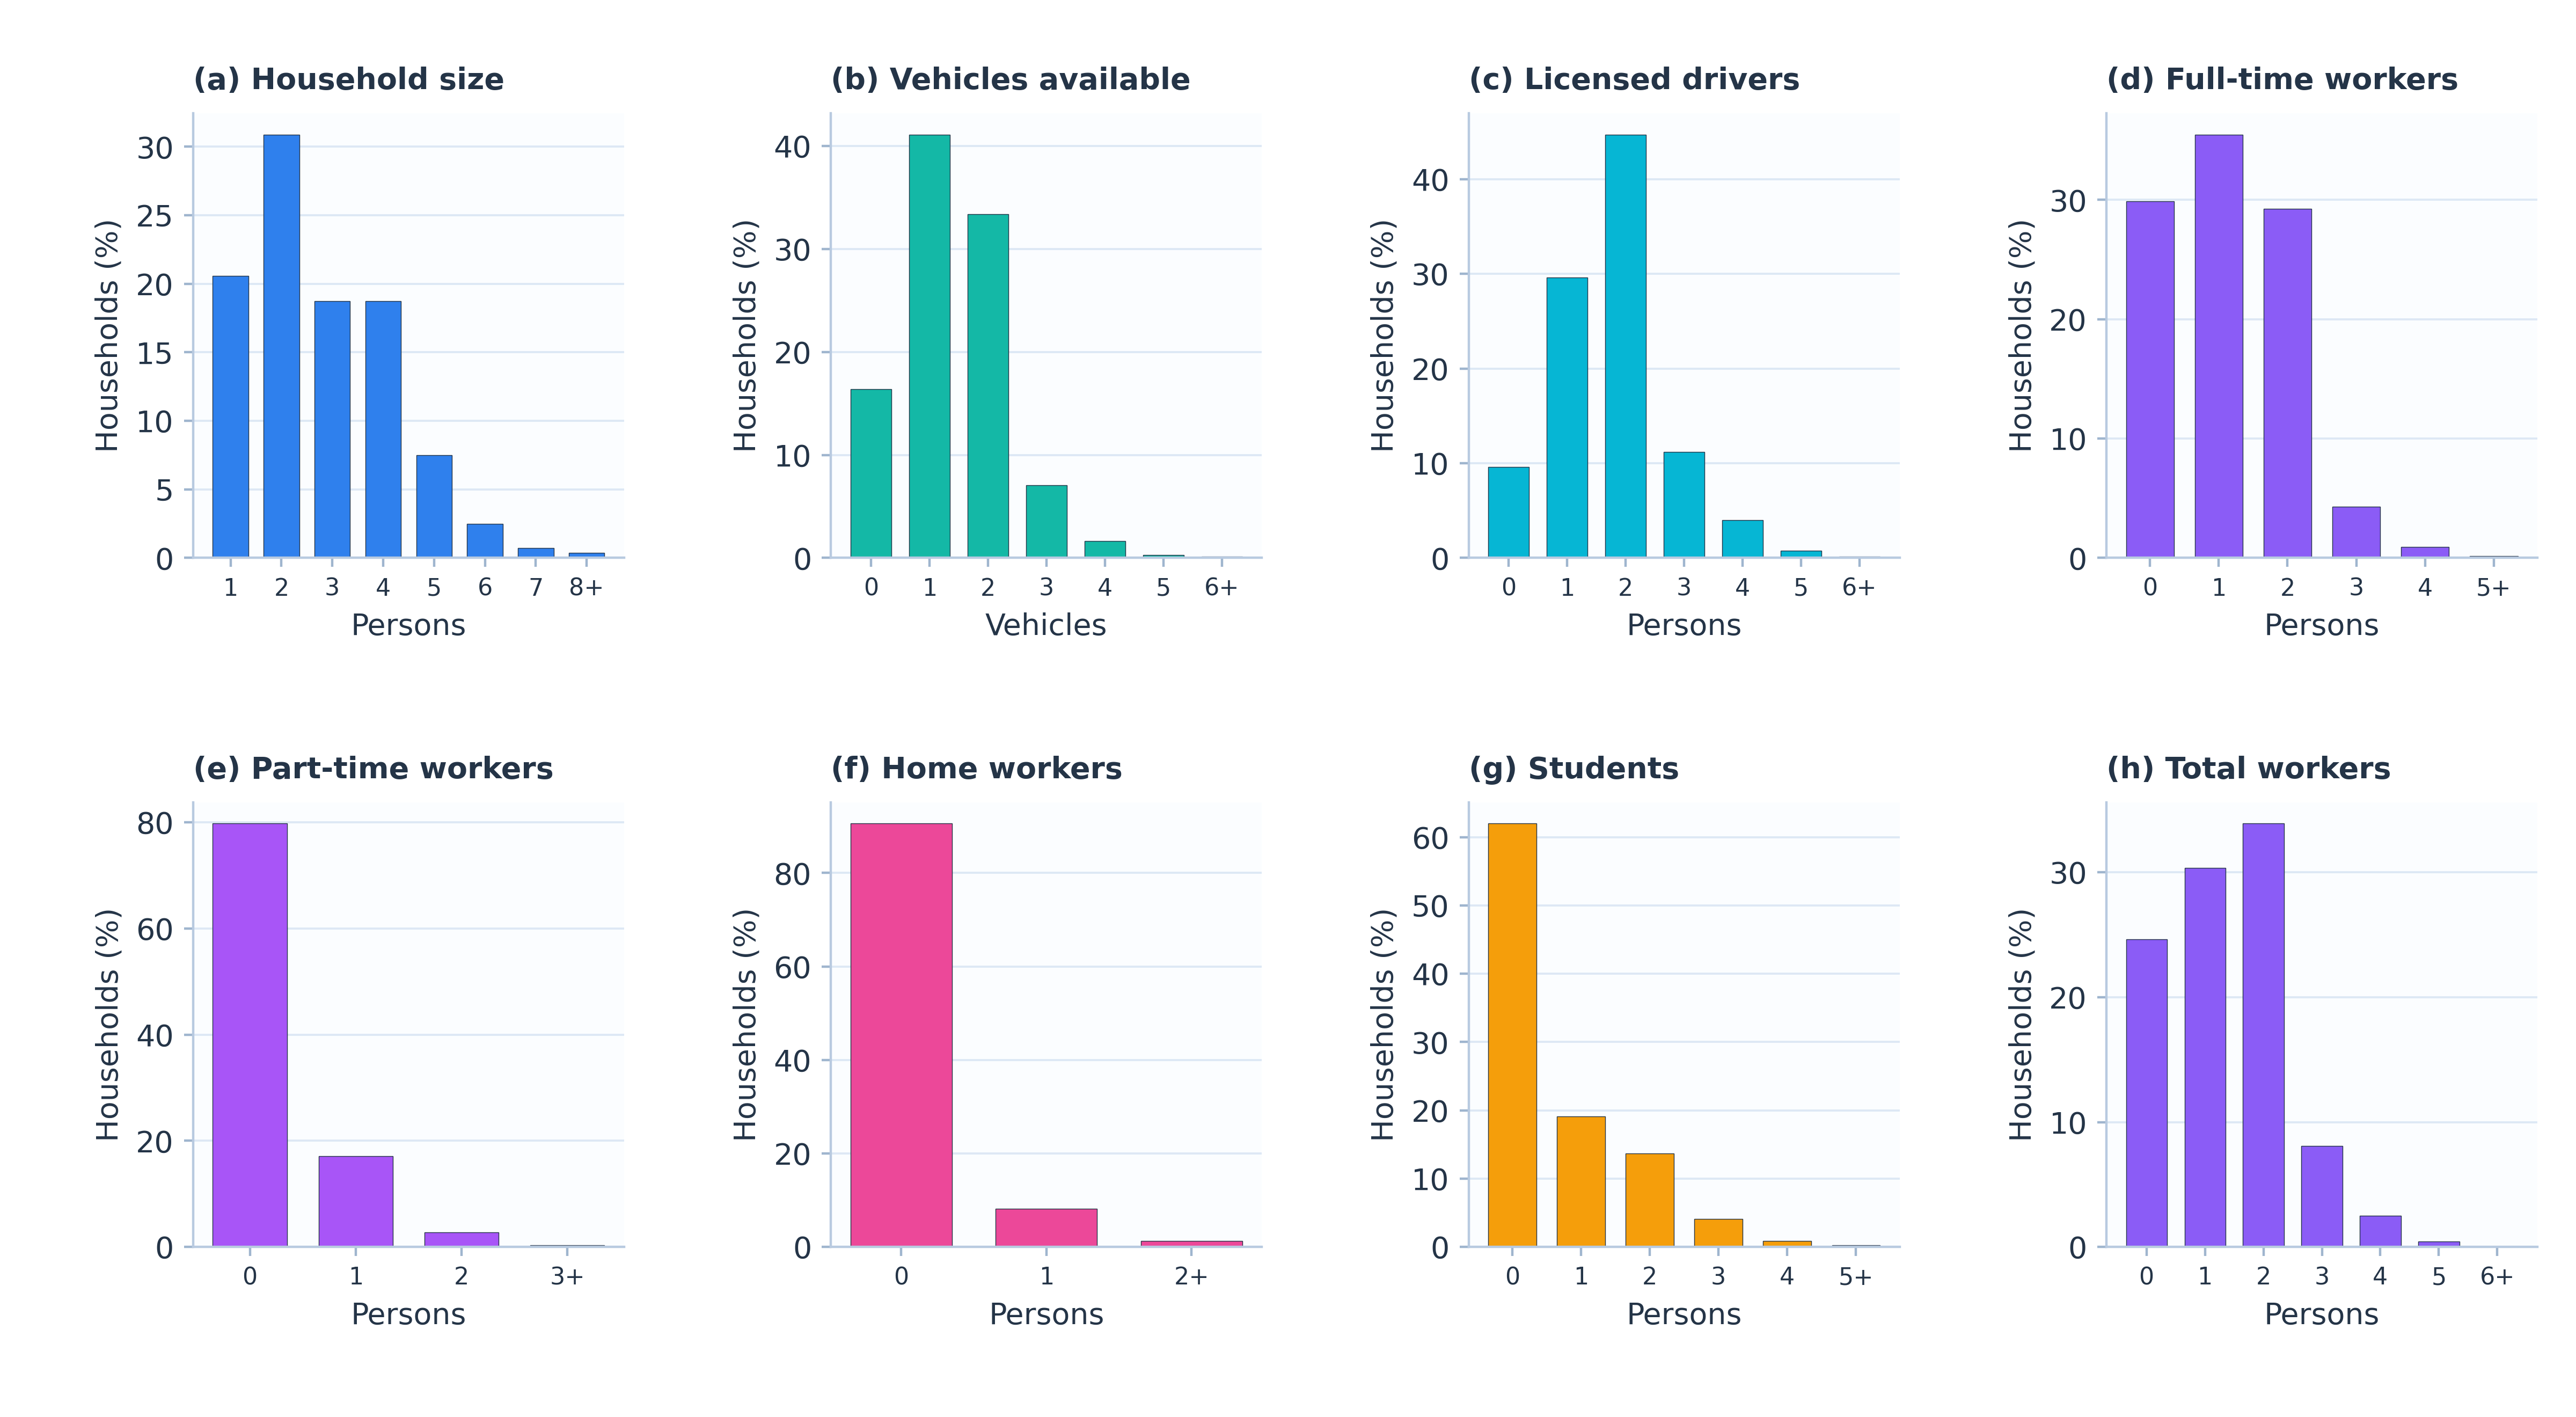

In [20]:
# ED02: predictor-only full-dataset profiles; eight panels in two rows.
fig, axes = plt.subplots(2, 4, figsize=(12, 6.6))
fig.subplots_adjust(left=.075, right=.985, bottom=.12, top=.92, wspace=.48, hspace=.55)
for i, field in enumerate(COUNTS):
    ax = axes.flat[i]
    freq = capped(analysis[field], CAPS[field]).value_counts().sort_index()
    ax.bar(range(len(freq)), 100 * freq / len(analysis), color=COLOURS[field], width=.7,
           edgecolor=INK, linewidth=.25)
    ax.set_xticks(range(len(freq)), ticks(freq.index, CAPS[field]), fontsize=8)
    ax.set_xlabel('Persons' if field != 'nvehicle_clean' else 'Vehicles')
    ax.set_ylabel('Households (%)')
    panel(ax, f'({chr(97+i)}) {LABELS[field]}')
    style_axes(ax)
save_figure(fig, 'Figure_ED02')

### Full-dataset trip distribution

In [21]:
numeric_rows.append({'sample': 'Full dataset (available values)', 'variable': 'nhhldtrip',
                'characteristic': LABELS['nhhldtrip'], **descriptive(analysis['nhhldtrip'])})
tables['ED02_numeric_descriptives'] = pd.DataFrame(numeric_rows)
tables['ED02_numeric_descriptives'].to_csv(TABLES / 'ED02_numeric_descriptives.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
trips = analysis['nhhldtrip'].value_counts().reindex(range(int(analysis['nhhldtrip'].max()) + 1),
                                                  fill_value=0).sort_index()
tables['ED04_trip_distribution'] = pd.DataFrame(
    {'trips': trips.index, 'n': trips.values, 'percent': 100 * trips.values / len(analysis)})
tables['ED04_trip_distribution'].to_csv(TABLES / 'ED04_trip_distribution.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')


show(tables['ED02_numeric_descriptives'].query('variable == "nhhldtrip"'))
show(tables['ED04_trip_distribution'])

,sample,variable,characteristic,n,mean,sd,minimum,p25,median,p75,maximum,zero_n,zero_pct
9,Full dataset (available values),nhhldtrip,Weekday household trips,93307,5.643253,4.562479,0.0,2.0,4.0,8.0,55.0,10480,11.23174


,trips,n,percent
0,0,10480,11.231740
1,1,400,0.428692
2,2,16214,17.377046
3,3,4039,4.328721
4,4,16286,17.454210
5,5,4555,4.881734
6,6,11190,11.992669
7,7,3755,4.024350
8,8,7500,8.037982
9,9,2959,3.171252


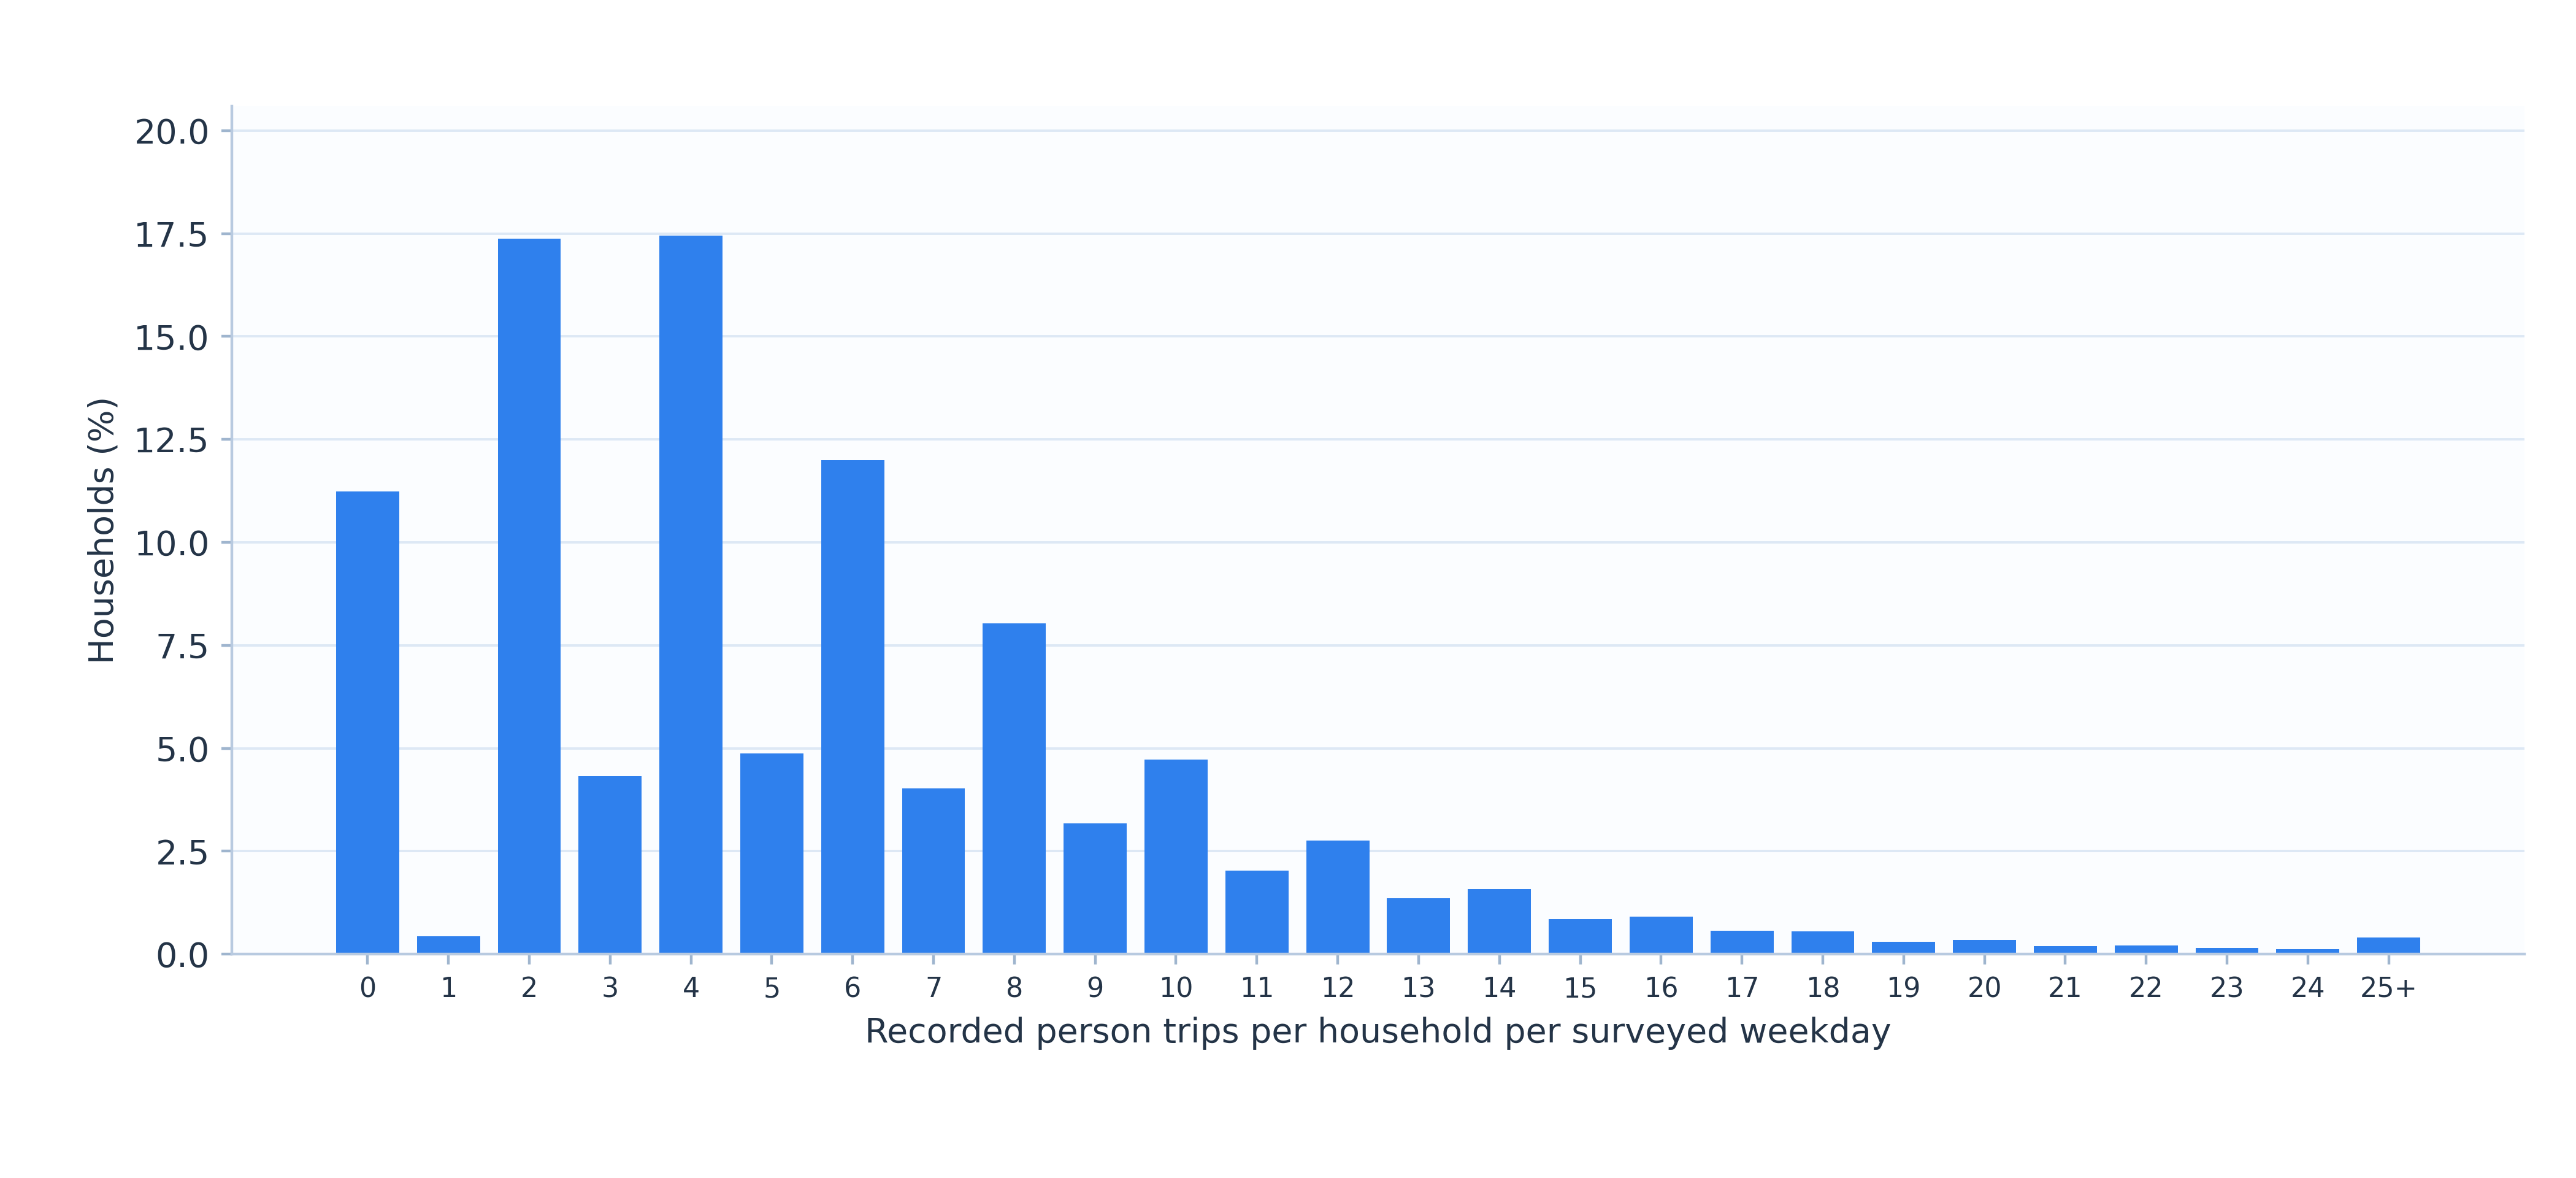

In [22]:
# ED01: discrete distribution; tail aggregation does not alter any statistic.
fig, ax = plt.subplots(figsize=(10.5, 4.8))
fig.subplots_adjust(left=.09, right=.98, bottom=.19, top=.91)
dist = capped(analysis['nhhldtrip'], TRIP_CAP).value_counts().reindex(range(TRIP_CAP + 1), fill_value=0)
pct = 100 * dist / len(analysis)
ax.bar(dist.index, pct, color=BLUE, width=.78)
ax.set_xticks(range(TRIP_CAP + 1), ticks(range(TRIP_CAP + 1), TRIP_CAP), fontsize=8)
ax.set_xlabel('Recorded person trips per household per surveyed weekday')
ax.set_ylabel('Households (%)')
ax.set_ylim(0, pct.max() * 1.18)
style_axes(ax)
save_figure(fig, 'Figure_ED01')

## 10. Trips by household characteristics

In [23]:
def group_statistics(frame, fields):
    """One row per observed group: raw n, mean, SD, zero share and weighted mean."""
    data = frame.assign(_weighted_trips=frame['nhhldtrip'] * frame['expf'],
                        _weighted_zero=frame['zero_trip'].astype(float) * frame['expf'])
    result = data.groupby(fields, observed=True, sort=True).agg(
        n=('hnum', 'size'), mean_trips=('nhhldtrip', 'mean'), sd_trips=('nhhldtrip', 'std'),
        median_trips=('nhhldtrip', 'median'), zero_n=('zero_trip', 'sum'),
        weight_sum=('expf', 'sum'), weighted_trip_sum=('_weighted_trips', 'sum'),
        weighted_zero_sum=('_weighted_zero', 'sum'),
    ).reset_index()
    result['zero_pct'] = 100 * result['zero_n'] / result['n']
    result['weighted_mean_trips'] = result['weighted_trip_sum'] / result['weight_sum']
    result['weighted_zero_pct'] = 100 * result['weighted_zero_sum'] / result['weight_sum']
    result['source_n'] = len(frame)
    result['groupable_n'] = int(frame[fields].notna().all(axis=1).sum())
    result['excluded_missing_group_n'] = result['source_n'] - result['groupable_n']
    return result.drop(columns=['weighted_trip_sum', 'weighted_zero_sum'])

def ordered_rates(analysis, field, display=False):
    if display:
        data = analysis.assign(level=capped(analysis[field], CAPS[field]))
    else:
        data = analysis.assign(level=analysis[field])
    result = group_statistics(data, ['level'])
    if field in ORDERS:
        result['level'] = pd.Categorical(result['level'], categories=ORDERS[field], ordered=True)
        result = result.sort_values('level')
    result.insert(0, 'variable', field)
    result.insert(1, 'characteristic', LABELS[field])
    result['display_label'] = [f'{x} or more' if display and x == CAPS[field] else str(x)
                               for x in result['level']]
    return result

exact = pd.concat([ordered_rates(analysis, f) for f in COUNTS + list(ORDERS)],
                  ignore_index=True)
display_rates = pd.concat([ordered_rates(analysis, f, True) for f in COUNTS], ignore_index=True)
tables['ED05_exact_group_trip_rates'] = exact
tables['ED05_exact_group_trip_rates'].to_csv(TABLES / 'ED05_exact_group_trip_rates.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
tables['ED06_display_group_trip_rates'] = display_rates
tables['ED06_display_group_trip_rates'].to_csv(TABLES / 'ED06_display_group_trip_rates.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')

show(tables['ED05_exact_group_trip_rates'].head(12))
show(exact.loc[exact['variable'].isin(list(ORDERS))])

,variable,characteristic,level,n,mean_trips,sd_trips,median_trips,zero_n,weight_sum,zero_pct,weighted_mean_trips,weighted_zero_pct,source_n,groupable_n,excluded_missing_group_n,display_label
0,nperson,Household size,1,19200,2.028437,1.830440,2.0,5960,372524.41,31.041667,2.029957,30.843335,93307,93307,0,1
1,nperson,Household size,2,28820,4.356003,3.019682,4.0,3678,556786.5,12.761971,4.353723,12.661403,93307,93307,0,2
2,nperson,Household size,3,17476,6.399519,3.660003,6.0,486,338685.87,2.780957,6.387489,2.782561,93307,93307,0,3
3,nperson,Household size,4,17472,8.306777,4.713263,8.0,250,339229.88,1.430861,8.291281,1.445645,93307,93307,0,4
4,nperson,Household size,5,7002,9.794916,5.581172,9.0,78,136353.03,1.113967,9.782848,1.147257,93307,93307,0,5
5,nperson,Household size,6,2326,10.475064,5.823351,10.0,21,45373.08,0.902837,10.447438,0.899498,93307,93307,0,6
6,nperson,Household size,7,662,11.261329,6.378599,10.0,3,12861.99,0.453172,11.271774,0.418209,93307,93307,0,7
7,nperson,Household size,8,221,12.339367,6.854178,11.0,3,4325.23,1.357466,12.326706,1.24294,93307,93307,0,8
8,nperson,Household size,9,70,14.114286,6.645349,14.0,1,1395.19,1.428571,14.090145,1.444964,93307,93307,0,9
9,nperson,Household size,10,36,16.25,10.182267,14.0,0,700.18,0.000000,16.309078,0.0,93307,93307,0,10


,variable,characteristic,level,n,mean_trips,sd_trips,median_trips,zero_n,weight_sum,zero_pct,weighted_mean_trips,weighted_zero_pct,source_n,groupable_n,excluded_missing_group_n,display_label
86,dwelling,Dwelling type,House,58360,6.564873,4.858576,6.0,4636,1118340.69,7.943797,6.583077,7.850841,93307,93307,0,House
87,dwelling,Dwelling type,Apartment,27977,3.621654,3.162584,3.0,5446,552708.23,19.465990,3.631908,19.218545,93307,93307,0,Apartment
88,dwelling,Dwelling type,Townhouse,6961,6.043097,4.145921,6.0,394,137420.01,5.660106,6.044656,5.616118,93307,93307,0,Townhouse
89,dwelling,Dwelling type,Unknown,9,4.444444,4.850544,4.0,4,179.51,44.444444,4.342321,47.345552,93307,93307,0,Unknown
90,weekday,Survey weekday,Monday,16652,5.434963,4.441686,4.0,2060,322860.03,12.370886,5.42733,12.255348,93307,93307,0,Monday
91,weekday,Survey weekday,Tuesday,18273,5.561484,4.491340,4.0,2144,354131.27,11.733158,5.550633,11.67423,93307,93307,0,Tuesday
92,weekday,Survey weekday,Wednesday,17728,5.681634,4.556083,4.0,1970,343367.07,11.112365,5.686271,11.024566,93307,93307,0,Wednesday
93,weekday,Survey weekday,Thursday,19414,5.62321,4.482840,4.0,2055,376263.83,10.585145,5.619172,10.526786,93307,93307,0,Thursday
94,weekday,Survey weekday,Friday,21240,5.863183,4.779573,5.0,2251,412026.24,10.597928,5.864322,10.545773,93307,93307,0,Friday
95,region,Region,Toronto,51612,4.918527,4.188406,4.0,7322,979313.82,14.186623,4.887346,14.209985,93307,93307,0,Toronto


### Household size, vehicles, licensed drivers, and total workers

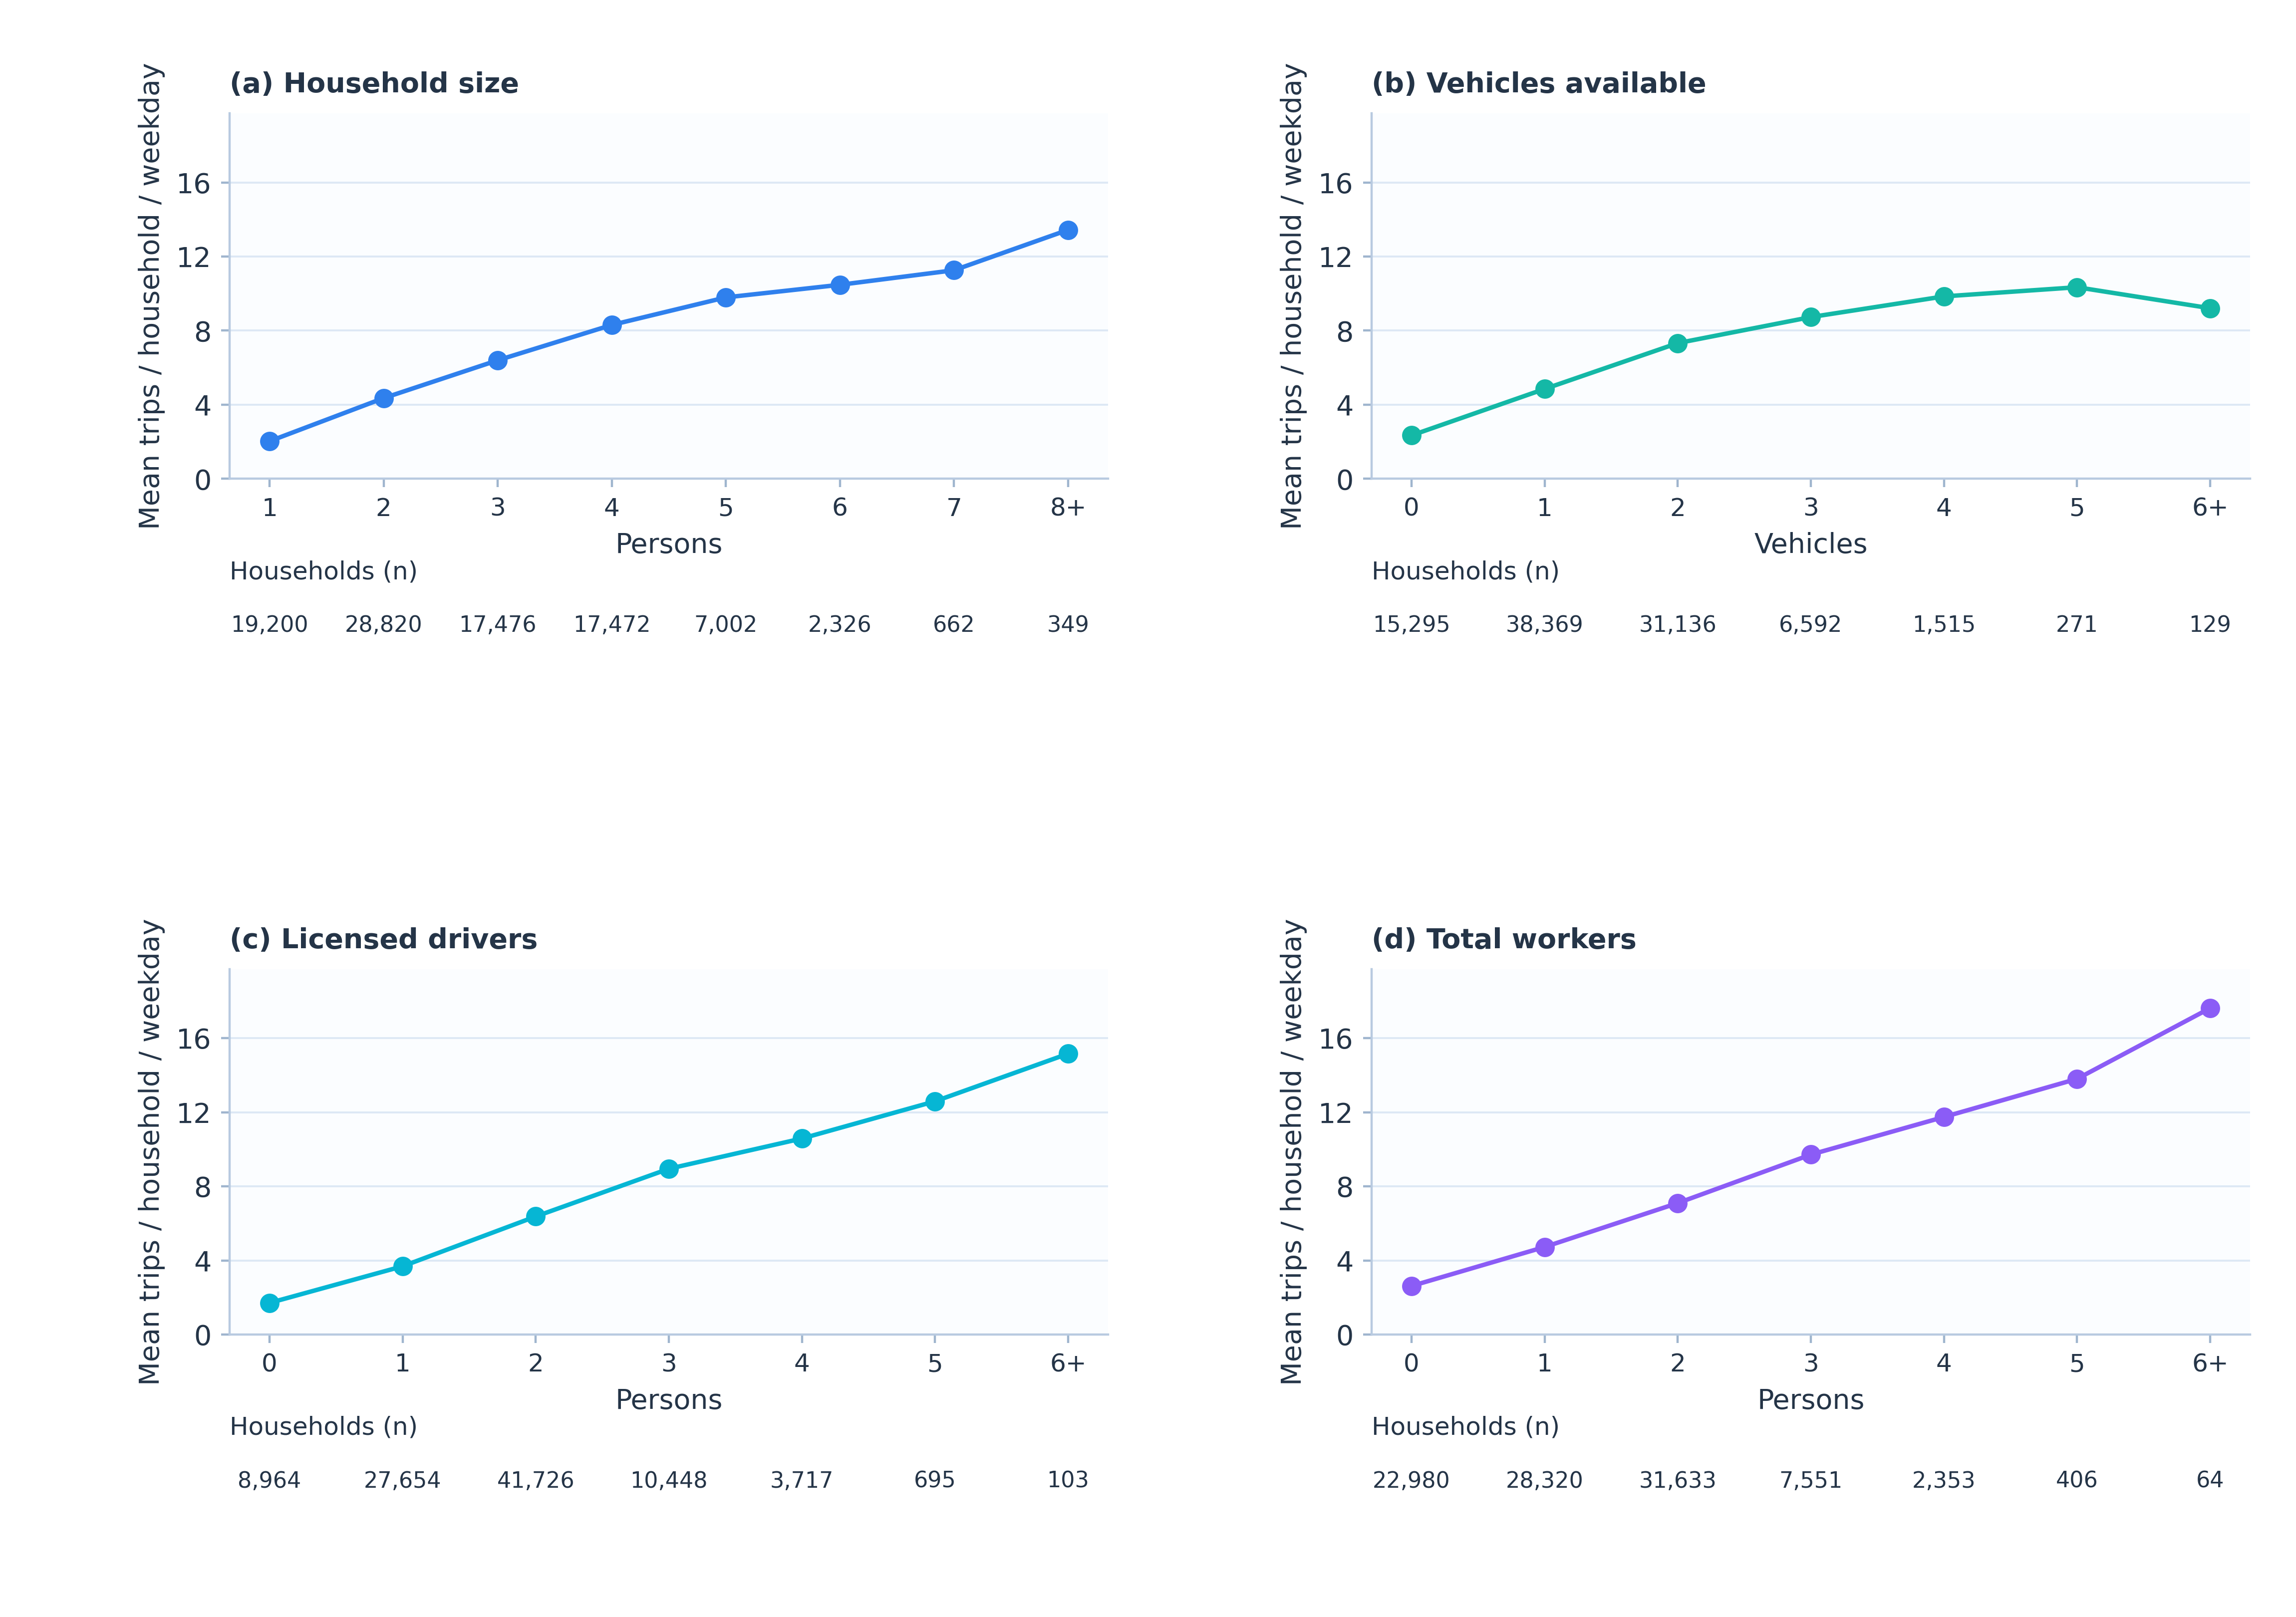

In [24]:
def plot_group_rates(fields, filename):
    """Plot up to four unadjusted trip-rate profiles with household support."""
    fig = plt.figure(figsize=(11.5, 8.1))
    outer = fig.add_gridspec(2, 2, left=.10, right=.98, bottom=.07,
                            top=.93, wspace=.30, hspace=.60)
    y_max = tables['ED06_display_group_trip_rates']['mean_trips'].max() * 1.12
    for i, field in enumerate(fields):
        inner = outer[i // 2, i % 2].subgridspec(2, 1, height_ratios=[4, .7], hspace=.49)
        ax, strip = fig.add_subplot(inner[0]), fig.add_subplot(inner[1])
        categorical = field in ORDERS
        data = tables['ED05_exact_group_trip_rates' if categorical else 'ED06_display_group_trip_rates']
        data = data.loc[data['variable'].eq(field)]
        x = np.arange(len(data))
        ax.plot(x, data['mean_trips'], 'o' if categorical else 'o-',
                color=COLOURS[field], markersize=6, linewidth=1.6)
        labels = data['level'].astype(str).tolist() if categorical else ticks(data['level'], CAPS[field])
        if field == 'weekday':
            labels = [label[:3] for label in labels]
        ax.set_xticks(x, labels, fontsize=9)
        ax.set_xlabel(LABELS[field] if categorical else 'Vehicles' if field == 'nvehicle_clean' else 'Persons')
        ax.set_ylabel('Mean trips / household / weekday')
        ax.set_ylim(0, y_max)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))
        panel(ax, f'({chr(97+i)}) {LABELS[field]}')
        style_axes(ax)
        strip.set_xlim(ax.get_xlim())
        strip.set_ylim(0, 1)
        strip.axis('off')
        strip.text(0, 1.0, 'Households (n)', transform=strip.transAxes, fontsize=9, va='bottom')
        for position, count in zip(x, data['n']):
            strip.text(position, .35, f'{count:,}', ha='center', va='center', fontsize=8)
    save_figure(fig, filename)

plot_group_rates(['nperson', 'nvehicle_clean', 'nlicence', 'workers'], 'Figure_ED03')

### Employment and students

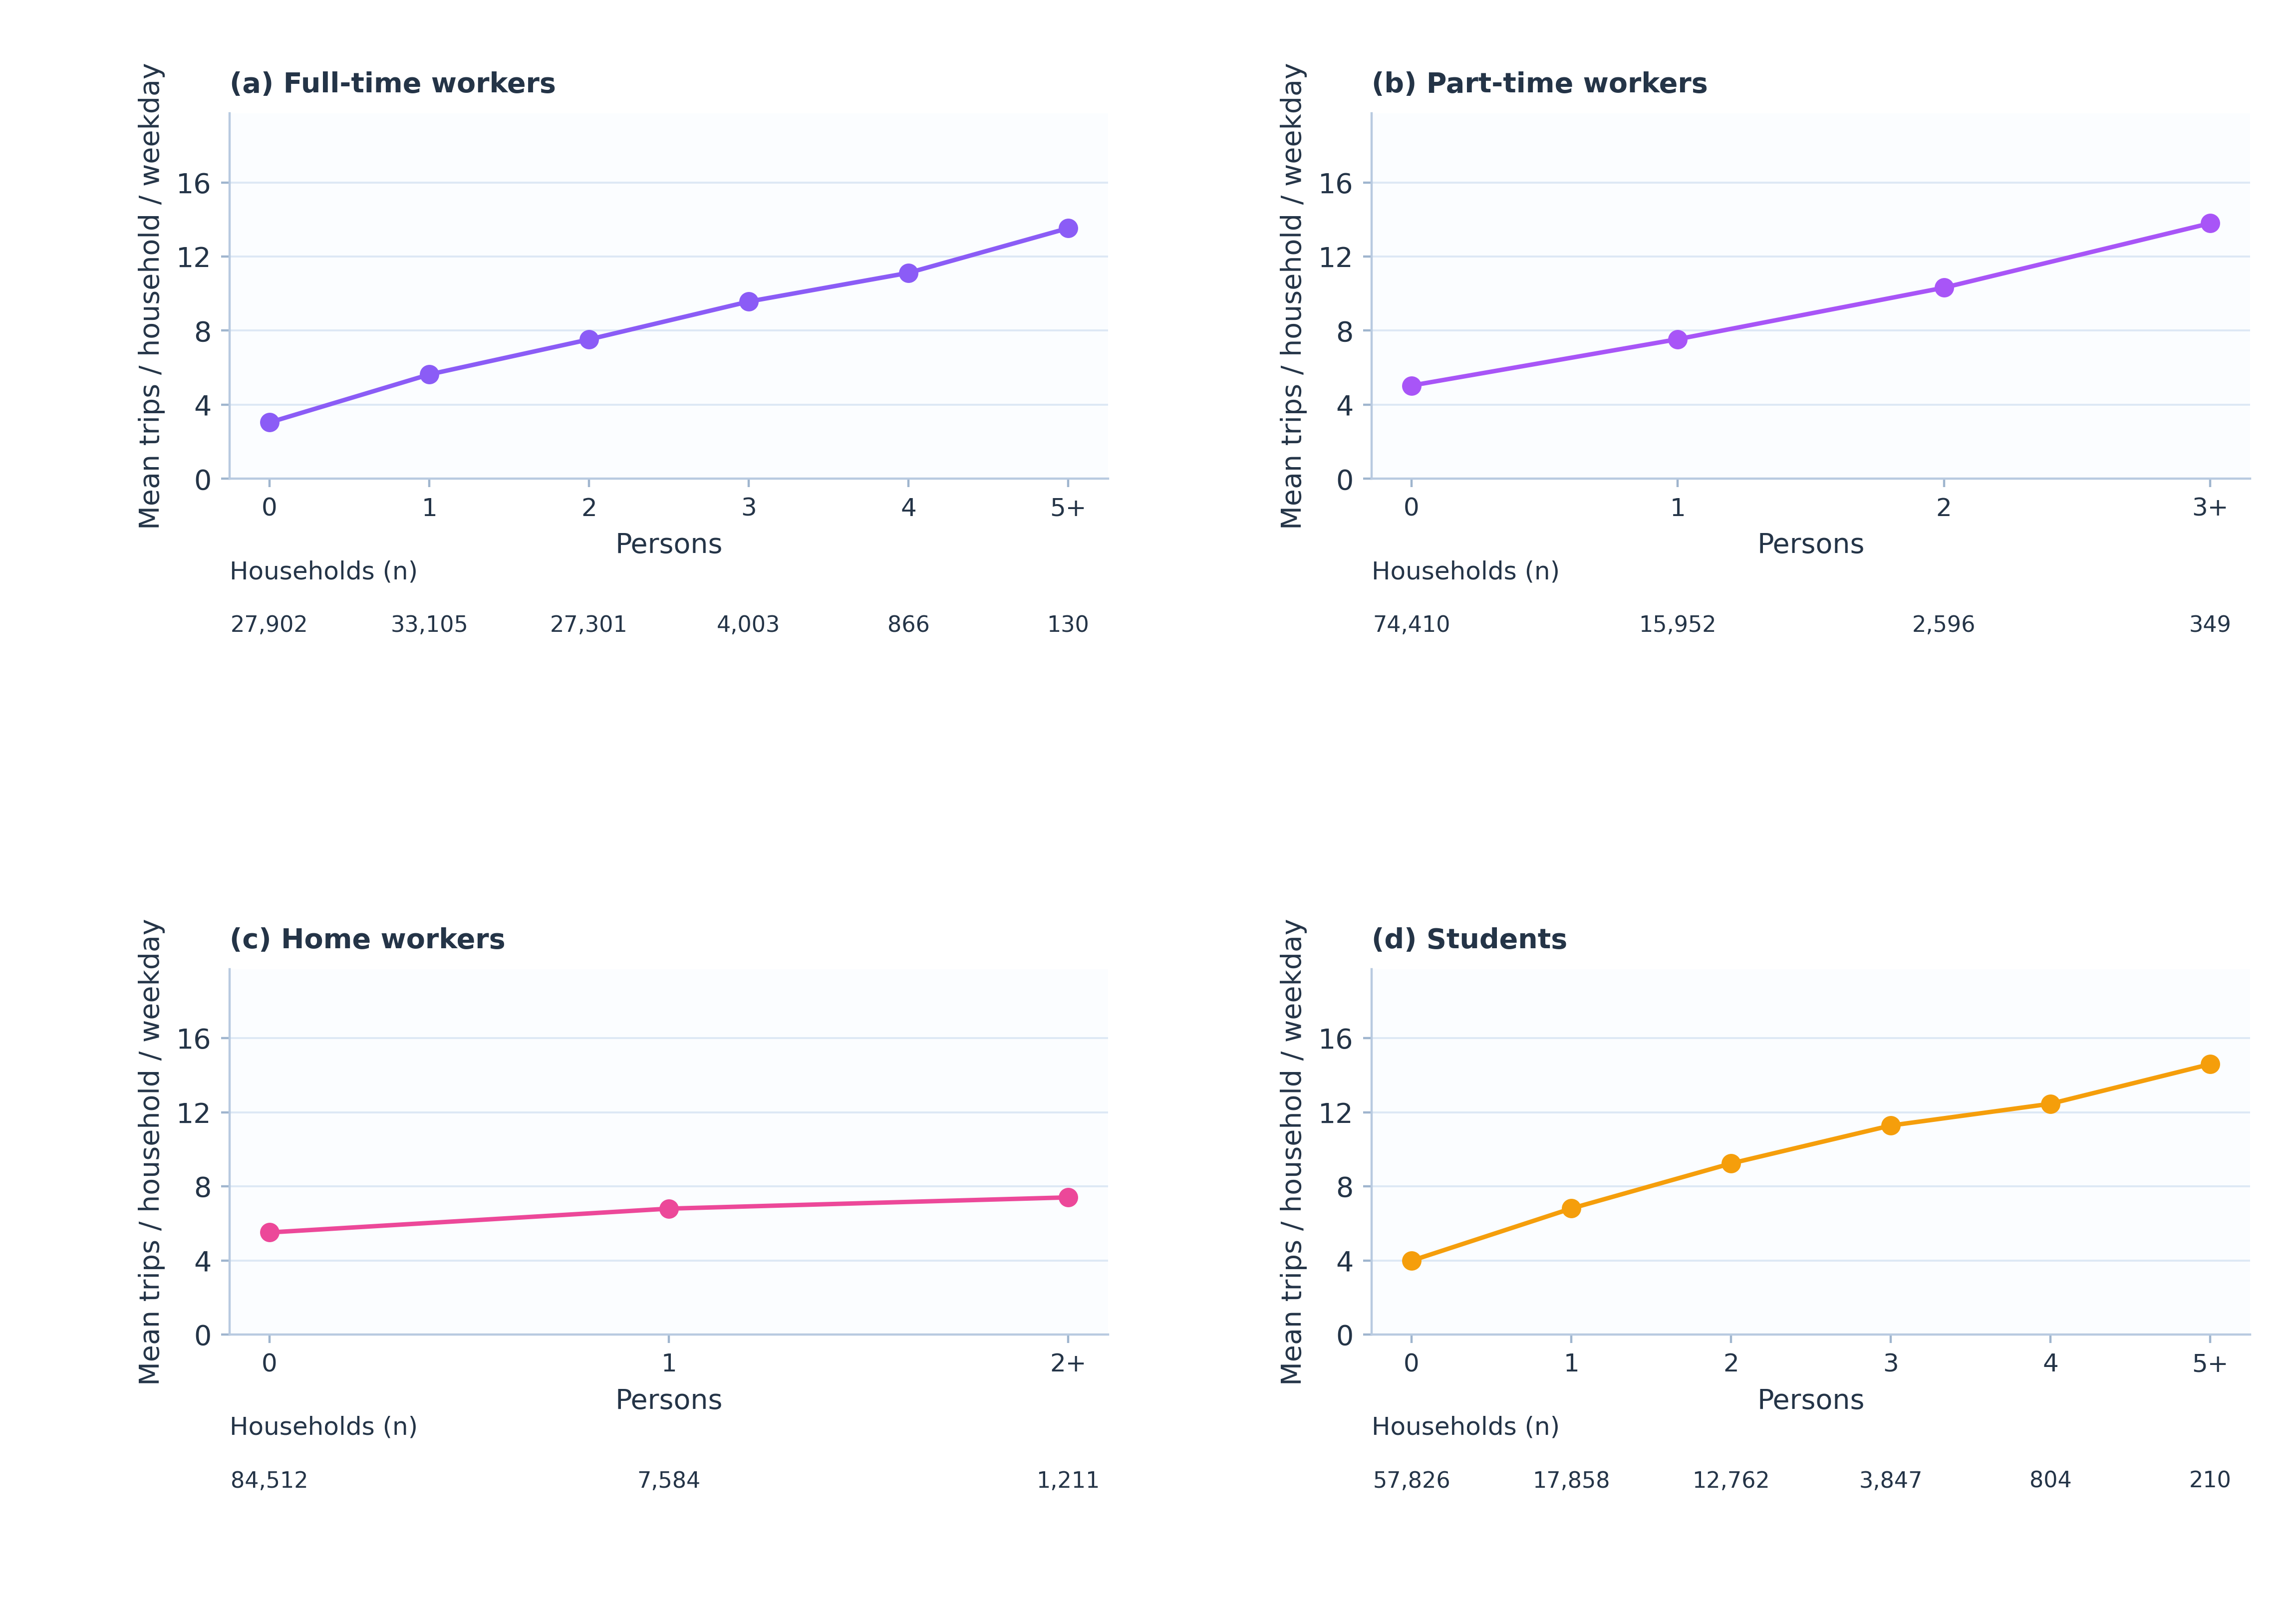

In [25]:
plot_group_rates(COMPOSITION, 'Figure_ED05')

### Dwelling type, survey weekday, and region

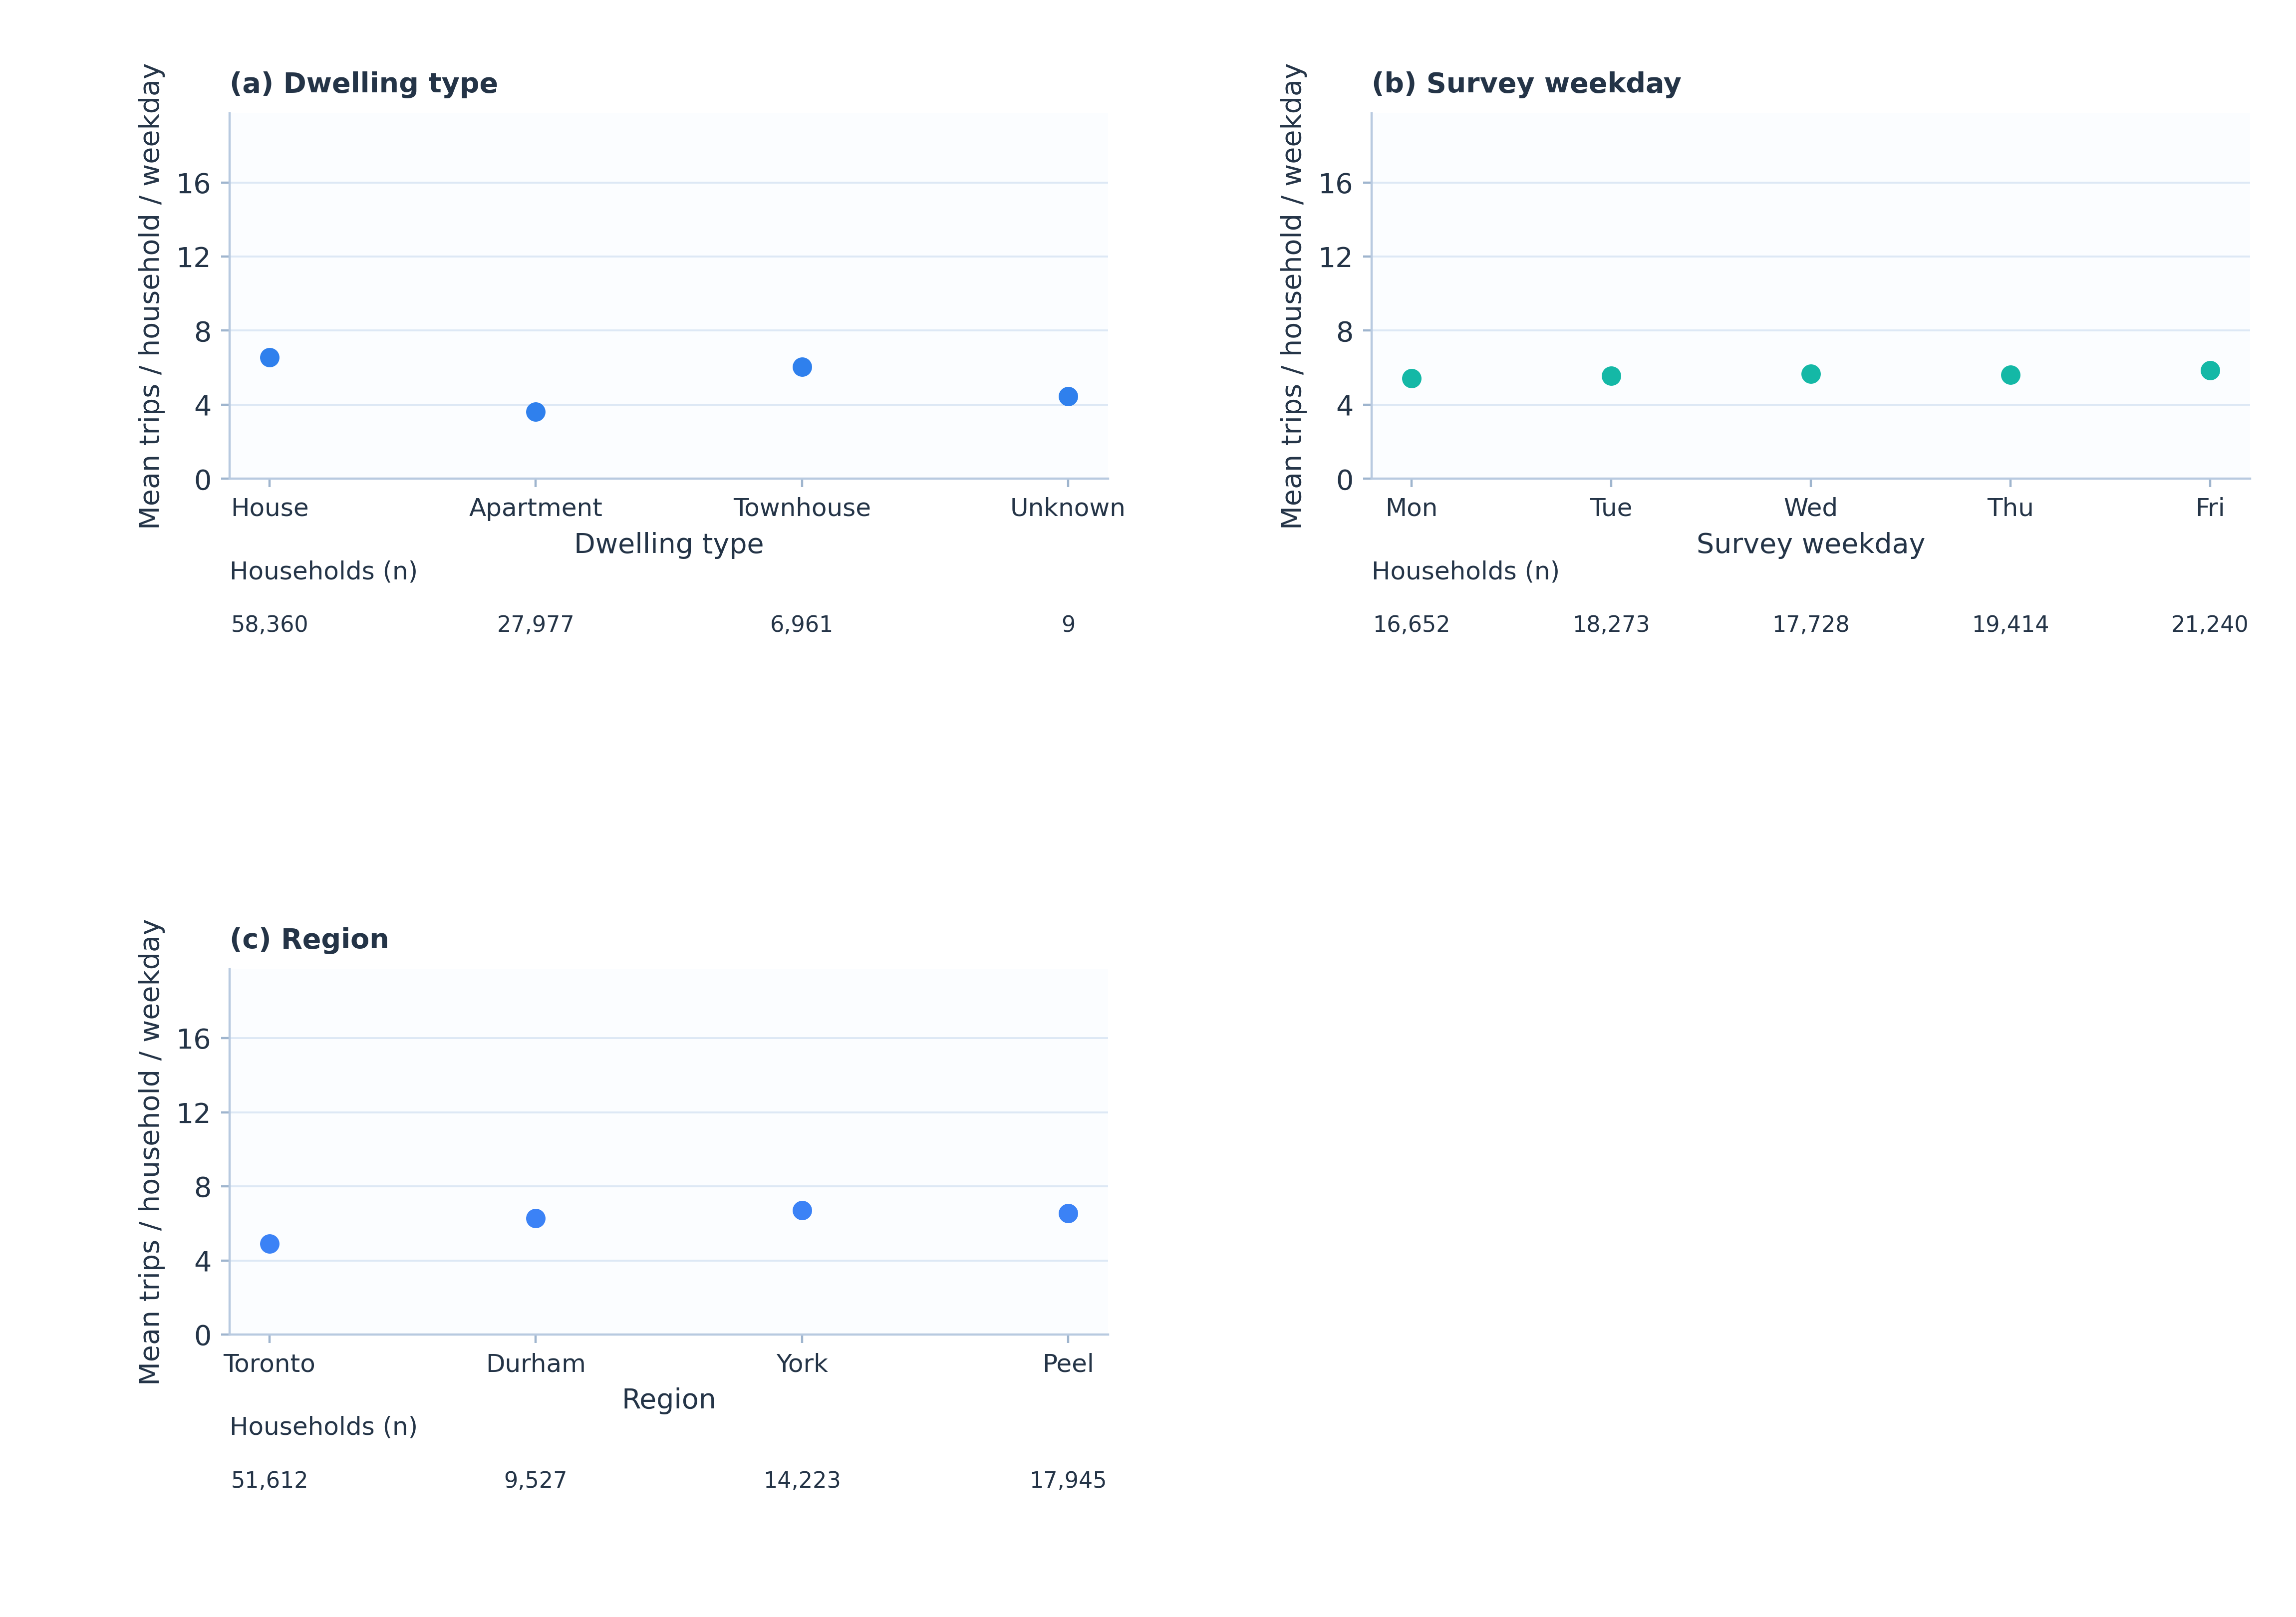

In [26]:
plot_group_rates(['dwelling', 'weekday', 'region'], 'Figure_ED09')

## 11. Joint patterns and sample support

In [27]:
def cell_statistics(analysis, size_cap, vehicle_cap):
    data = analysis.dropna(subset=['nvehicle_clean']).assign(size=capped(analysis['nperson'], size_cap),
                           vehicles=capped(analysis['nvehicle_clean'], vehicle_cap))
    observed = group_statistics(data, ['size', 'vehicles']).set_index(['size', 'vehicles'])
    grid = pd.MultiIndex.from_product([range(1, size_cap + 1), range(vehicle_cap + 1)],
                                     names=['size', 'vehicles'])
    cells = observed.reindex(grid).reset_index()
    for name in ['n', 'zero_n']:
        cells[name] = cells[name].fillna(0).astype(int)
    cells['weight_sum'] = cells['weight_sum'].fillna(0)
    cells['scheme'] = f'{size_cap}+ persons by {vehicle_cap}+ vehicles'
    cells['size_label'] = cells['size'].map(lambda x: f'{x}+' if x == size_cap else str(x))
    cells['vehicle_label'] = cells['vehicles'].map(lambda x: f'{x}+' if x == vehicle_cap else str(x))
    cells['support_below_30'] = cells['n'].lt(SUPPORT_REVIEW_N)
    return cells

cells = pd.concat([cell_statistics(analysis, 5, 3), cell_statistics(analysis, 5, 4)], ignore_index=True)
tables['ED07_classification_cells'] = cells
tables['ED07_classification_cells'].to_csv(TABLES / 'ED07_classification_cells.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
adjacent = []
for scheme, block in cells.groupby('scheme', sort=False):
    for field, fixed in [('size', 'vehicles'), ('vehicles', 'size')]:
        for fixed_value, line in block.groupby(fixed):
            line = line.sort_values(field)
            for (_, left), (_, right) in zip(line.iloc[:-1].iterrows(), line.iloc[1:].iterrows()):
                adjacent.append({'scheme': scheme, 'changing_dimension': field,
                                 'fixed_dimension': fixed, 'fixed_value': fixed_value,
                                 'from_level': int(left[field]), 'to_level': int(right[field]),
                                 'n_from': int(left['n']), 'n_to': int(right['n']),
                                 'mean_difference': right['mean_trips'] - left['mean_trips'],
                                 'weighted_mean_difference': right['weighted_mean_trips'] - left['weighted_mean_trips']})
tables['ED08_adjacent_cell_differences'] = pd.DataFrame(adjacent)
tables['ED08_adjacent_cell_differences'].to_csv(TABLES / 'ED08_adjacent_cell_differences.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')

show(tables['ED07_classification_cells'])
show(tables['ED08_adjacent_cell_differences'].head(12))

,size,vehicles,n,mean_trips,sd_trips,median_trips,zero_n,weight_sum,zero_pct,weighted_mean_trips,weighted_zero_pct,source_n,groupable_n,excluded_missing_group_n,scheme,size_label,vehicle_label,support_below_30
0,1,0,8433,1.324558,1.439345,2.0,3955,164242.56,46.899087,1.332406,46.532312,93307,93307,0,5+ persons by 3+ vehicles,1,0,False
1,1,1,9954,2.556359,1.898851,2.0,1883,192573.57,18.917018,2.556572,18.739436,93307,93307,0,5+ persons by 3+ vehicles,1,1,False
2,1,2,671,2.80775,2.029705,2.0,102,12998.29,15.201192,2.816504,15.272009,93307,93307,0,5+ persons by 3+ vehicles,1,2,False
3,1,3,142,3.140845,2.188272,3.0,20,2709.99,14.084507,3.111834,14.789353,93307,93307,0,5+ persons by 3+ vehicles,1,3+,False
4,2,0,4109,2.780239,2.275272,2.0,1111,80561.77,27.038209,2.797267,26.637597,93307,93307,0,5+ persons by 3+ vehicles,2,0,False
5,2,1,13607,4.257074,3.003633,4.0,1901,263364.63,13.970750,4.265059,13.791506,93307,93307,0,5+ persons by 3+ vehicles,2,1,False
6,2,2,10040,5.011554,3.018894,4.0,622,192714.48,6.195219,5.003573,6.172717,93307,93307,0,5+ persons by 3+ vehicles,2,2,False
7,2,3,1064,5.520677,3.243279,5.0,44,20145.62,4.135338,5.520551,4.068329,93307,93307,0,5+ persons by 3+ vehicles,2,3+,False
8,3,0,1500,4.141333,2.455207,4.0,125,29408.88,8.333333,4.137603,8.304124,93307,93307,0,5+ persons by 3+ vehicles,3,0,False
9,3,1,6493,6.006623,3.537292,6.0,215,126052.73,3.311258,5.995599,3.32564,93307,93307,0,5+ persons by 3+ vehicles,3,1,False


,scheme,changing_dimension,fixed_dimension,fixed_value,from_level,to_level,n_from,n_to,mean_difference,weighted_mean_difference
0,5+ persons by 3+ vehicles,size,vehicles,0,1,2,8433,4109,1.455680,1.464862
1,5+ persons by 3+ vehicles,size,vehicles,0,2,3,4109,1500,1.361095,1.340335
2,5+ persons by 3+ vehicles,size,vehicles,0,3,4,1500,854,1.071781,1.071622
3,5+ persons by 3+ vehicles,size,vehicles,0,4,5,854,399,1.285632,1.292963
4,5+ persons by 3+ vehicles,size,vehicles,1,1,2,9954,13607,1.700714,1.708487
5,5+ persons by 3+ vehicles,size,vehicles,1,2,3,13607,6493,1.749549,1.730541
6,5+ persons by 3+ vehicles,size,vehicles,1,3,4,6493,5422,1.171541,1.168706
7,5+ persons by 3+ vehicles,size,vehicles,1,4,5,5422,2893,1.406697,1.404720
8,5+ persons by 3+ vehicles,size,vehicles,2,1,2,671,10040,2.203804,2.187069
9,5+ persons by 3+ vehicles,size,vehicles,2,2,3,10040,7093,1.863534,1.860043


### Household size × licensed drivers

In [28]:
driver_blocks = []
for driver_cap in [DRIVER_TOP, DRIVER_ALTERNATIVE_TOP]:
    driver_data = analysis.assign(
        size=capped(analysis[CROSS_CLASS_FIELDS[0]], DRIVER_SIZE_TOP),
        drivers=capped(analysis[CROSS_CLASS_FIELDS[1]], driver_cap))
    observed = group_statistics(driver_data, ['size', 'drivers']).set_index(['size', 'drivers'])
    grid = pd.MultiIndex.from_product(
        [range(1, DRIVER_SIZE_TOP + 1), range(driver_cap + 1)], names=['size', 'drivers'])
    block = observed.reindex(grid).reset_index()
    for column in ['n', 'zero_n']:
        block[column] = block[column].fillna(0).astype(int)
    block['weight_sum'] = block['weight_sum'].fillna(0)
    block['scheme'] = f'{DRIVER_SIZE_TOP}+ persons by {driver_cap}+ licensed drivers'
    block['size_label'] = ticks(block['size'], DRIVER_SIZE_TOP)
    block['driver_label'] = ticks(block['drivers'], driver_cap)
    block['structurally_possible'] = block['size'].eq(DRIVER_SIZE_TOP) | block['drivers'].le(block['size'])
    block['support_below_30'] = block['n'].lt(SUPPORT_REVIEW_N)
    block['cell_status'] = np.select(
        [~block['structurally_possible'], block['n'].eq(0)],
        ['Drivers exceed household size', 'No observations'], default='Observed')
    driver_blocks.append(block)
tables['ED18_driver_classification_cells'] = pd.concat(driver_blocks, ignore_index=True)
tables['ED18_driver_classification_cells'].to_csv(TABLES / 'ED18_driver_classification_cells.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')

driver_adjacent = []
for scheme, block in tables['ED18_driver_classification_cells'].groupby('scheme', sort=False):
    for field, fixed in [('size', 'drivers'), ('drivers', 'size')]:
        for fixed_value, line in block.groupby(fixed):
            line = line.sort_values(field)
            for (_, left), (_, right) in zip(line.iloc[:-1].iterrows(), line.iloc[1:].iterrows()):
                driver_adjacent.append({
                    'scheme': scheme, 'changing_dimension': field, 'fixed_dimension': fixed,
                    'fixed_value': fixed_value, 'from_level': int(left[field]), 'to_level': int(right[field]),
                    'n_from': int(left['n']), 'n_to': int(right['n']),
                    'mean_difference': right['mean_trips'] - left['mean_trips'],
                    'weighted_mean_difference': right['weighted_mean_trips'] - left['weighted_mean_trips'],
                    'both_observed': left['n'] > 0 and right['n'] > 0,
                })
tables['ED19_driver_adjacent_differences'] = pd.DataFrame(driver_adjacent)
tables['ED19_driver_adjacent_differences'].to_csv(TABLES / 'ED19_driver_adjacent_differences.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
show(tables['ED18_driver_classification_cells'])

,size,drivers,n,mean_trips,sd_trips,median_trips,zero_n,weight_sum,zero_pct,weighted_mean_trips,weighted_zero_pct,source_n,groupable_n,excluded_missing_group_n,scheme,size_label,driver_label,structurally_possible,support_below_30,cell_status
0,1,0,5873,1.080368,1.346612,0.0,3251,113666.13,55.355014,1.088819,55.00409,93307.0,93307.0,0.0,5+ persons by 4+ licensed drivers,1,0,True,False,Observed
1,1,1,13327,2.446237,1.859407,2.0,2709,258858.28,20.327155,2.443216,20.234211,93307.0,93307.0,0.0,5+ persons by 4+ licensed drivers,1,1,True,False,Observed
2,1,2,0,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,5+ persons by 4+ licensed drivers,1,2,False,True,Drivers exceed household size
3,1,3,0,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,5+ persons by 4+ licensed drivers,1,3,False,True,Drivers exceed household size
4,1,4,0,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,5+ persons by 4+ licensed drivers,1,4+,False,True,Drivers exceed household size
5,2,0,2062,2.101358,2.120098,2.0,826,40146.86,40.058196,2.126901,39.465303,93307.0,93307.0,0.0,5+ persons by 4+ licensed drivers,2,0,True,False,Observed
6,2,1,7859,3.796793,2.891798,4.0,1362,152580.71,17.330449,3.803297,17.179478,93307.0,93307.0,0.0,5+ persons by 4+ licensed drivers,2,1,True,False,Observed
7,2,2,18899,4.834542,3.004051,4.0,1490,364058.93,7.884015,4.829977,7.812013,93307.0,93307.0,0.0,5+ persons by 4+ licensed drivers,2,2,True,False,Observed
8,2,3,0,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,5+ persons by 4+ licensed drivers,2,3,False,True,Drivers exceed household size
9,2,4,0,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,5+ persons by 4+ licensed drivers,2,4+,False,True,Drivers exceed household size


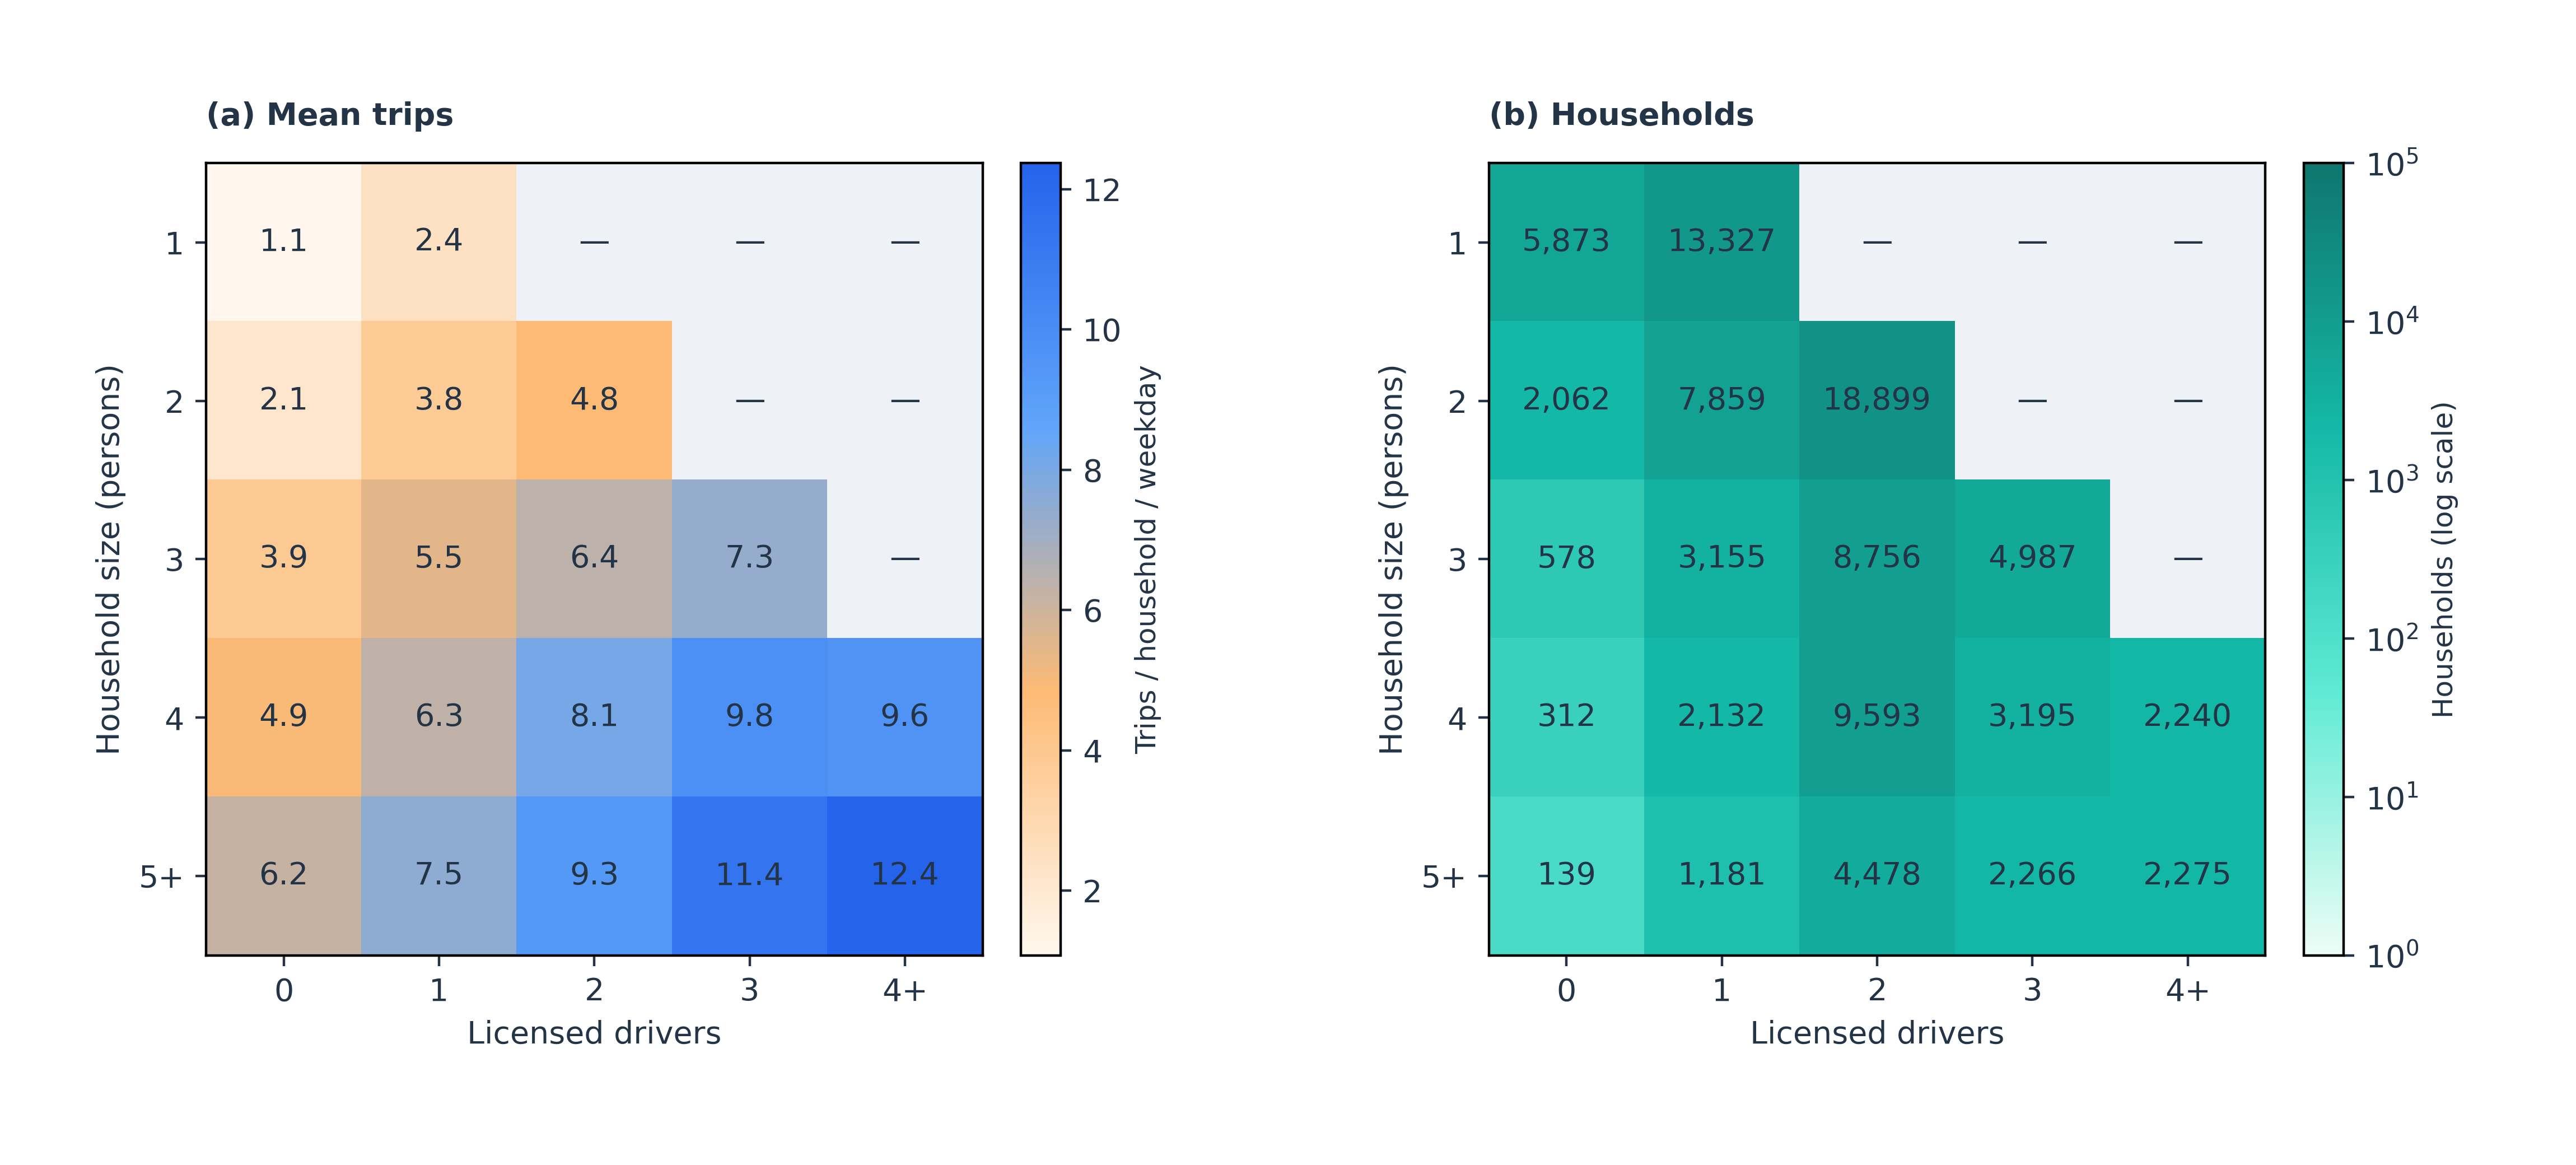

In [29]:
driver_cells = tables['ED18_driver_classification_cells'].loc[
    tables['ED18_driver_classification_cells']['scheme'].eq(
        f'{DRIVER_SIZE_TOP}+ persons by {DRIVER_TOP}+ licensed drivers')]
mean_cmap = MEAN_CMAP.copy(); mean_cmap.set_bad('#EEF2F7')
count_cmap = COUNT_CMAP.copy(); count_cmap.set_bad('#EEF2F7')
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.2))
fig.subplots_adjust(left=.08, right=.91, bottom=.18, top=.86, wspace=.50)
possible = driver_cells.pivot(index='size', columns='drivers', values='structurally_possible').to_numpy()
for i, (metric, cmap) in enumerate([('mean_trips', mean_cmap), ('n', count_cmap)]):
    ax = axes[i]
    matrix = driver_cells.pivot(index='size', columns='drivers', values=metric).to_numpy(dtype=float)
    norm = LogNorm(vmin=1, vmax=10 ** np.ceil(np.log10(matrix.max()))) if i else None
    mask = ~possible | (matrix <= 0) if i else ~possible | ~np.isfinite(matrix)
    image = ax.imshow(np.ma.masked_where(mask, matrix), cmap=cmap, norm=norm, aspect='auto')
    ax.set_xticks(range(DRIVER_TOP + 1), ticks(range(DRIVER_TOP + 1), DRIVER_TOP))
    ax.set_yticks(range(DRIVER_SIZE_TOP), ticks(range(1, DRIVER_SIZE_TOP + 1), DRIVER_SIZE_TOP))
    ax.set_xlabel('Licensed drivers')
    ax.set_ylabel('Household size (persons)')
    panel(ax, '(a) Mean trips' if i == 0 else '(b) Households')
    for row in range(DRIVER_SIZE_TOP):
        for col in range(DRIVER_TOP + 1):
            value = matrix[row, col]
            label = '—' if not possible[row, col] or not np.isfinite(value) else f'{value:,.0f}' if i else f'{value:.1f}'
            ax.text(col, row, label, ha='center', va='center', color=INK, fontsize=10)
    cbar = fig.colorbar(image, ax=ax, fraction=.047, pad=.045)
    cbar.set_label('Households (log scale)' if i else 'Trips / household / weekday', fontsize=9)
    if i:
        cbar.minorticks_off()
save_figure(fig, 'Figure_ED10')

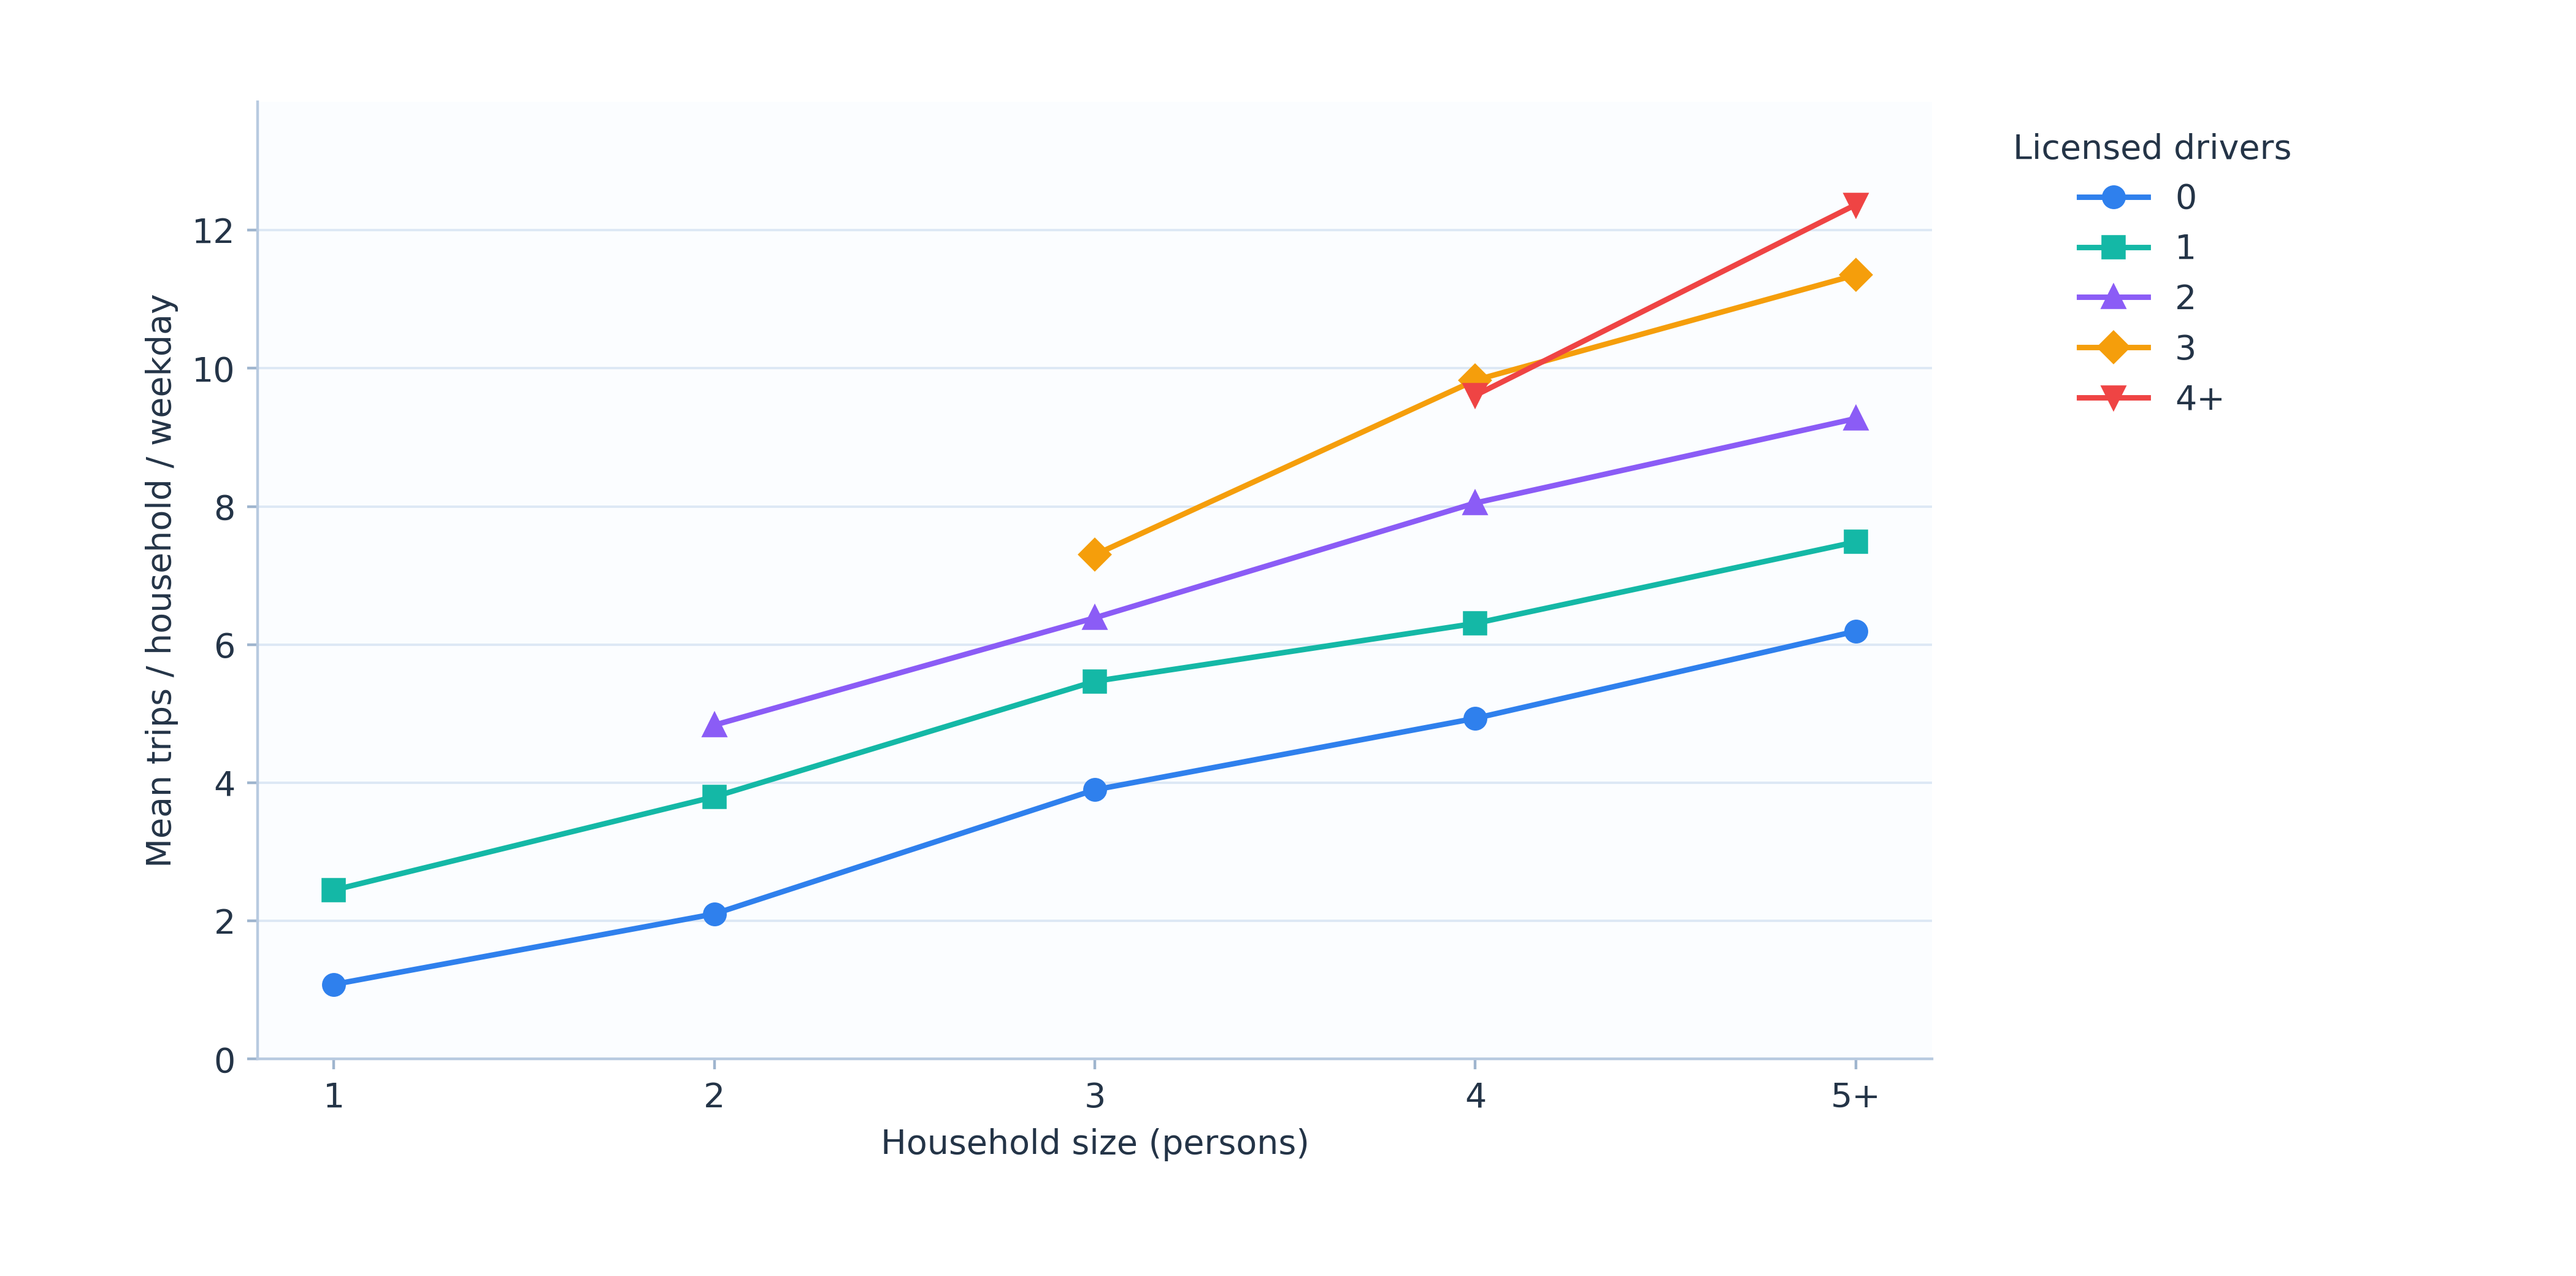

In [30]:
fig, ax = plt.subplots(figsize=(10.5, 5.2))
fig.subplots_adjust(left=.10, right=.75, bottom=.17, top=.92)
driver_colours = [BLUE, AQUA, VIOLET, ORANGE, '#EF4444']
driver_markers = ['o', 's', '^', 'D', 'v']
for driver_count in range(DRIVER_TOP + 1):
    block = driver_cells.loc[driver_cells['drivers'].eq(driver_count)].sort_values('size')
    rates = block['mean_trips'].where(block['n'].gt(0))
    label = f'{driver_count}+' if driver_count == DRIVER_TOP else str(driver_count)
    ax.plot(block['size'], rates, marker=driver_markers[driver_count], markersize=6,
            linewidth=1.6, color=driver_colours[driver_count], label=label)
ax.set_xticks(range(1, DRIVER_SIZE_TOP + 1), ticks(range(1, DRIVER_SIZE_TOP + 1), DRIVER_SIZE_TOP))
ax.set_xlabel('Household size (persons)')
ax.set_ylabel('Mean trips / household / weekday')
ax.set_ylim(0, driver_cells['mean_trips'].max() * 1.12)
style_axes(ax)
ax.legend(title='Licensed drivers', frameon=False, bbox_to_anchor=(1.03, 1), loc='upper left')
save_figure(fig, 'Figure_ED11')

### Household size × vehicles

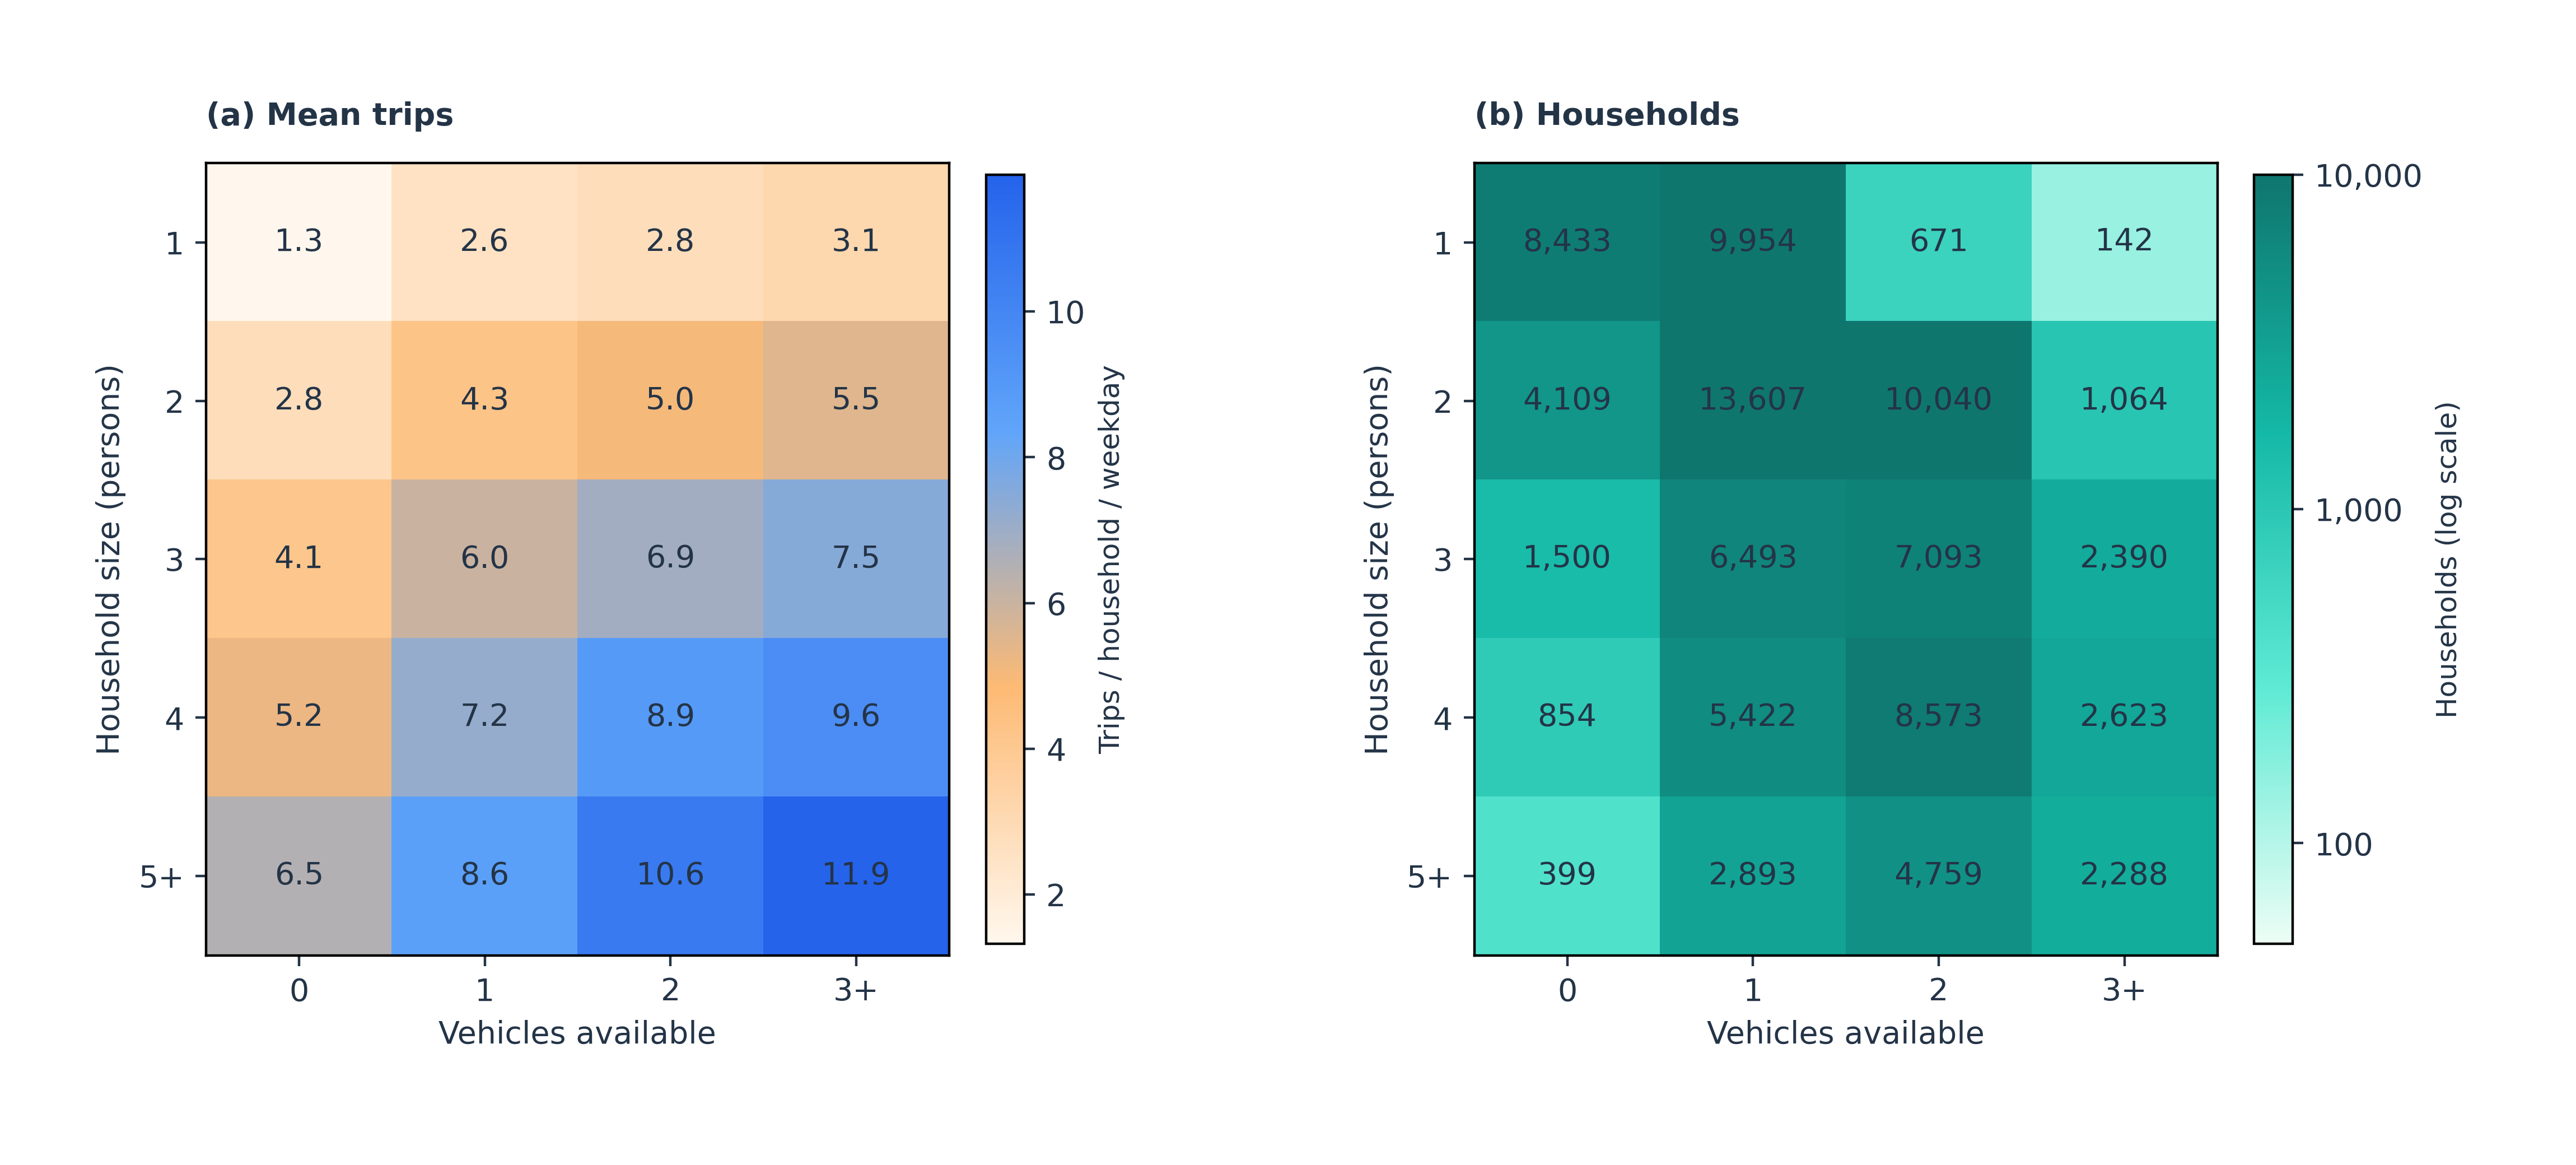

In [31]:
# Vehicle-based comparison.
cells = tables['ED07_classification_cells'].query('scheme == "5+ persons by 3+ vehicles"')
mean_cmap = MEAN_CMAP.copy(); mean_cmap.set_bad('#EEF2F7')
count_cmap = COUNT_CMAP.copy(); count_cmap.set_bad('#EEF2F7')
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.2))
fig.subplots_adjust(left=.08, right=.89, bottom=.18, top=.86, wspace=.55)
for i, (metric, cmap) in enumerate([('mean_trips', mean_cmap), ('n', count_cmap)]):
    ax = axes[i]
    matrix = cells.pivot(index='size', columns='vehicles', values=metric).to_numpy(dtype=float)
    norm = LogNorm(vmin=50, vmax=10000) if i else None
    values = np.ma.masked_where(matrix <= 0, matrix) if i else np.ma.masked_invalid(matrix)
    image = ax.imshow(values, cmap=cmap, norm=norm, aspect='auto', origin='upper')
    ax.set_xticks(range(4), ['0', '1', '2', '3+'])
    ax.set_yticks(range(5), ['1', '2', '3', '4', '5+'])
    ax.set_xlabel('Vehicles available')
    ax.set_ylabel('Household size (persons)')
    panel(ax, '(a) Mean trips' if i == 0 else '(b) Households')
    for row in range(5):
        for col in range(4):
            value = matrix[row, col]
            label = ('—' if not np.isfinite(value) else f'{value:,.0f}' if i else f'{value:.1f}')
            ax.text(col, row, label, ha='center', va='center', color=INK, fontsize=10)
    cbar = fig.colorbar(image, ax=ax, fraction=.047, pad=.045)
    cbar.set_label('Households (log scale)' if i else 'Trips / household / weekday', fontsize=9)
    if i:
        cbar.set_ticks([100, 1000, 10000])
        cbar.set_ticklabels(['100', '1,000', '10,000'])
        cbar.minorticks_off()
save_figure(fig, 'Figure_ED04')

In [32]:
blocks = []
for field in COUNTS[:2]:
    for view in ['exact', 'display']:
        available = analysis.dropna(subset=[field])
        levels = available[field].astype(int)
        trips = available['nhhldtrip'].astype(int)
        if view == 'display':
            levels, trips = capped(levels, CAPS[field]), capped(trips, TRIP_CAP)
        grid = pd.MultiIndex.from_product(
            [range(int(levels.min()), int(levels.max()) + 1), range(int(trips.max()) + 1)],
            names=['level', 'trips'])
        counts = pd.DataFrame({'level': levels, 'trips': trips}).groupby(['level', 'trips']).size()
        block = counts.reindex(grid, fill_value=0).rename('n').reset_index()
        block.insert(0, 'variable', field)
        block.insert(1, 'view', view)
        block['level_label'] = ticks(block['level'], CAPS[field]) if view == 'display' else block['level'].astype(str)
        block['trip_label'] = ticks(block['trips'], TRIP_CAP) if view == 'display' else block['trips'].astype(str)
        block['group_n'] = block.groupby('level')['n'].transform('sum')
        block['panel_n'] = len(available)
        block['source_n'] = len(analysis)
        block['missing_predictor_n'] = len(analysis) - len(available)
        blocks.append(block)
tables['ED16_trip_frequencies'] = pd.concat(blocks, ignore_index=True)
tables['ED16_trip_frequencies'].to_csv(TABLES / 'ED16_trip_frequencies.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
show(tables['ED16_trip_frequencies'].groupby(['variable', 'view'])['n'].sum())

variable        view   
nperson         display    93307
                exact      93307
nvehicle_clean  display    93307
                exact      93307
Name: n, dtype: int64

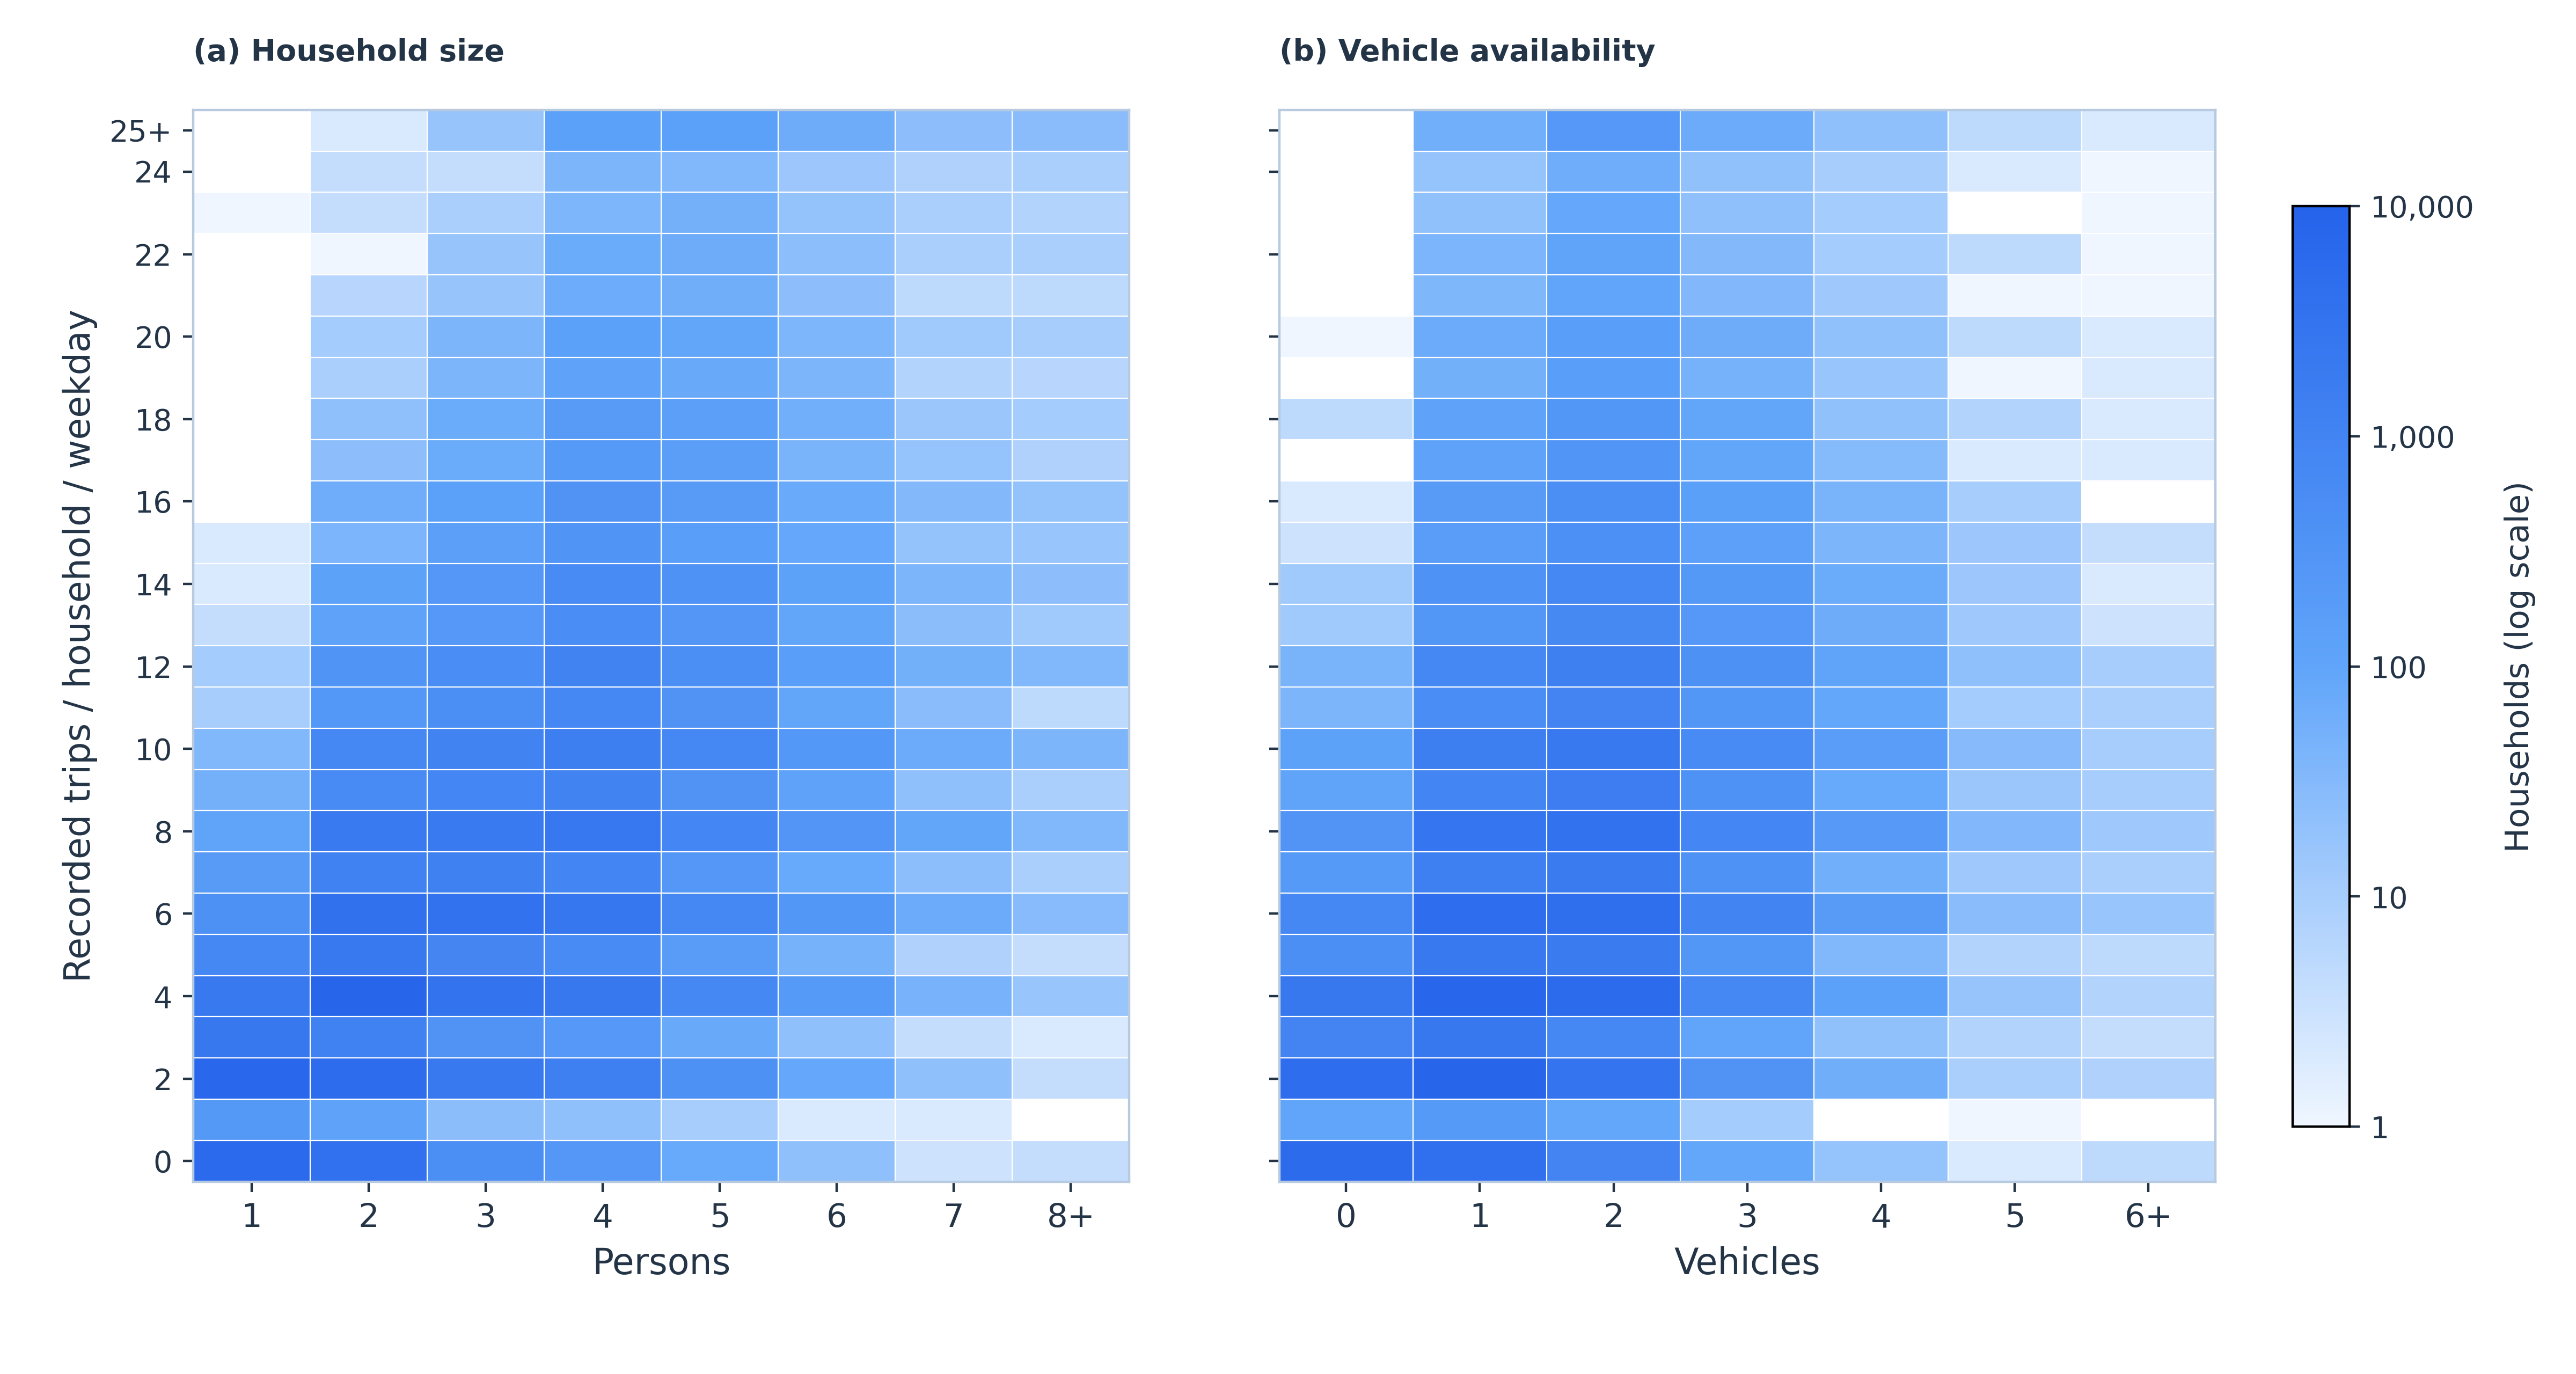

In [33]:
# ED07: discrete joint frequencies, not smoothed densities or fitted values.
frequency = tables['ED16_trip_frequencies'].query('view == "display"')
colour_max = 10 ** int(np.ceil(np.log10(frequency['n'].max())))
norm = LogNorm(vmin=1, vmax=colour_max)
cmap = LinearSegmentedColormap.from_list('household_frequency', ['#EFF6FF', '#60A5FA', '#2563EB'])
cmap.set_bad('white')
fig, axes = plt.subplots(1, 2, figsize=(12, 6.4), sharey=True)
fig.subplots_adjust(left=.075, right=.86, bottom=.14, top=.92, wspace=.16)
for i, field in enumerate(COUNTS[:2]):
    ax = axes[i]
    data = frequency.loc[frequency['variable'].eq(field)]
    grid = data.pivot(index='trips', columns='level', values='n').sort_index().sort_index(axis=1)
    values = grid.to_numpy(dtype=float)
    image = ax.imshow(np.ma.masked_equal(values, 0), origin='lower', aspect='auto',
                      interpolation='nearest', cmap=cmap, norm=norm)
    ax.set_xticks(range(len(grid.columns)), ticks(grid.columns, CAPS[field]), fontsize=11)
    shown_trips = list(range(0, TRIP_CAP, 2)) + [TRIP_CAP]
    ax.set_yticks(shown_trips, ticks(shown_trips, TRIP_CAP), fontsize=10)
    ax.set_xlabel('Persons' if i == 0 else 'Vehicles', fontsize=12)
    panel(ax, '(a) Household size' if i == 0 else '(b) Vehicle availability')
    ax.set_xticks(np.arange(-.5, len(grid.columns), 1), minor=True)
    ax.set_yticks(np.arange(-.5, len(grid.index), 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=.4)
    ax.tick_params(which='minor', bottom=False, left=False)
    for spine in ax.spines.values():
        spine.set_color('#B8CAE0')
axes[0].set_ylabel('Recorded trips / household / weekday', fontsize=12)
colour_axis = fig.add_axes([.89, .18, .022, .67])
colourbar = fig.colorbar(image, cax=colour_axis)
colour_ticks = [10 ** k for k in range(int(np.log10(colour_max)) + 1)]
colourbar.set_ticks(colour_ticks, labels=[f'{n:,}' for n in colour_ticks])
colourbar.minorticks_off()
colourbar.set_label('Households (log scale)', fontsize=11, labelpad=10)
save_figure(fig, 'Figure_ED07')

## 12. Correlation analysis

In [34]:
def pairwise_correlations(data):
    """Rank after pairwise missing-value removal, so tied Spearman ranks use the same rows."""
    rows = []
    for x in data.columns:
        for y in data.columns:
            pair = pd.concat([data[x], data[y]], axis=1).dropna().astype(float)
            a, b = pair.iloc[:, 0], pair.iloc[:, 1]
            rows.append({'variable_1': x, 'variable_2': y, 'n': len(pair),
                         'pearson': a.corr(b),
                         'spearman': a.rank(method='average').corr(b.rank(method='average'))})
    return pd.DataFrame(rows)

tables['ED09_predictor_correlations'] = pairwise_correlations(analysis[COUNTS])
tables['ED09_predictor_correlations'].to_csv(TABLES / 'ED09_predictor_correlations.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
show(tables['ED09_predictor_correlations'])

,variable_1,variable_2,n,pearson,spearman
0,nperson,nperson,93307,1.000000,1.000000
1,nperson,nvehicle_clean,93307,0.403686,0.482201
2,nperson,nlicence,93307,0.598793,0.631591
3,nperson,nempft,93307,0.515168,0.533852
4,nperson,nemppt,93307,0.261946,0.257000
...,...,...,...,...,...
59,workers,nempft,93307,0.873023,0.882311
60,workers,nemppt,93307,0.469958,0.423284
61,workers,nemphome,93307,0.201397,0.203205
62,workers,nstudent,93307,0.327388,0.369030


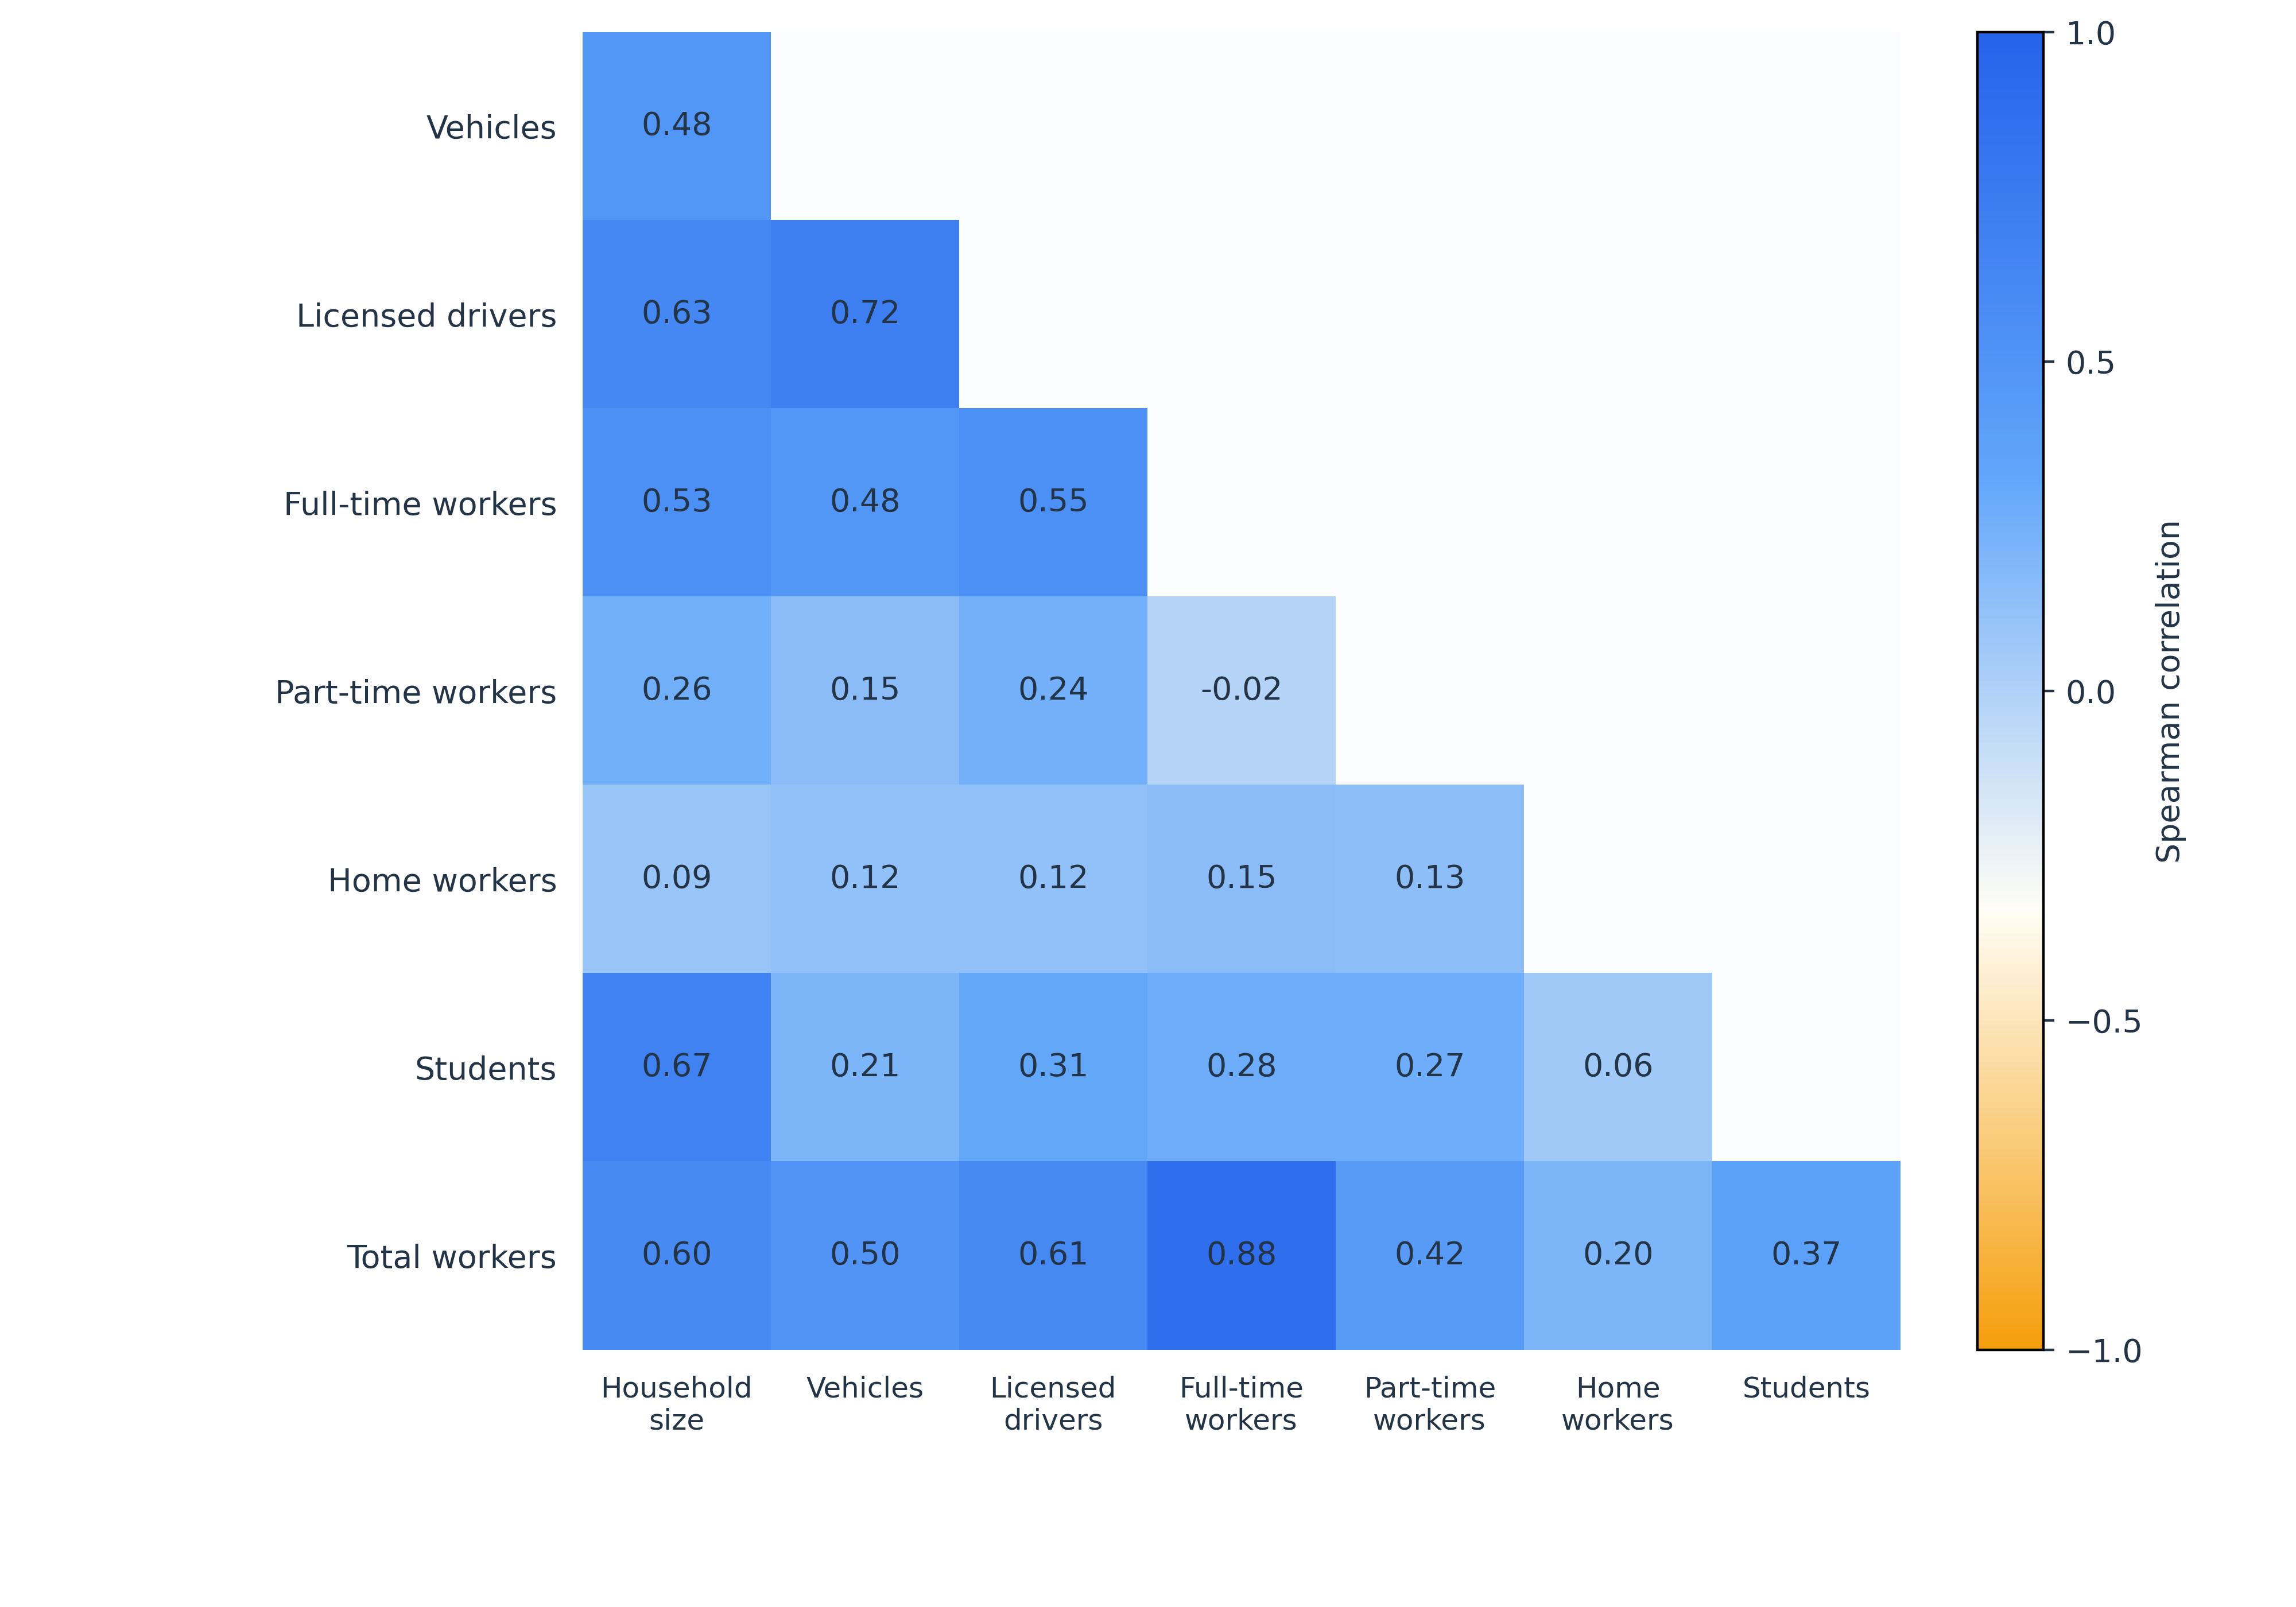

In [35]:
# ED06: rank correlation, lower triangle; Pearson retained in the backing table.
fig, ax = plt.subplots(figsize=(10, 7))
fig.subplots_adjust(left=.22, right=.89, bottom=.16, top=.98)
data = tables['ED09_predictor_correlations'].pivot(index='variable_1', columns='variable_2', values='spearman')
matrix = data.reindex(index=COUNTS, columns=COUNTS).to_numpy()
masked = np.ma.masked_where(np.triu(np.ones_like(matrix), k=0).astype(bool), matrix)
image = ax.imshow(masked[1:, :-1], cmap=CORR_CMAP, vmin=-1, vmax=1)
short = ['Household\nsize', 'Vehicles', 'Licensed\ndrivers', 'Full-time\nworkers',
         'Part-time\nworkers', 'Home\nworkers', 'Students', 'Total\nworkers']
ax.set_xticks(range(len(COUNTS) - 1), short[:-1], fontsize=9)
ax.set_yticks(range(len(COUNTS) - 1), [x.replace('\n', ' ') for x in short[1:]], fontsize=10)
ax.tick_params(length=0, pad=8)
for spine in ax.spines.values():
    spine.set_visible(False)
for row in range(len(COUNTS)):
    for col in range(row):
        ax.text(col, row - 1, f'{matrix[row, col]:.2f}', ha='center', va='center', color=INK)
cbar = fig.colorbar(image, ax=ax, fraction=.043, pad=.05, ticks=[-1, -.5, 0, .5, 1])
cbar.set_label('Spearman correlation')
save_figure(fig, 'Figure_ED06')

### Household characteristics and trip outcomes

In [36]:
outcome_pairs = pairwise_correlations(analysis[COUNTS + ['nhhldtrip']])
outcome_correlations = outcome_pairs.loc[
    outcome_pairs['variable_2'].eq('nhhldtrip') & outcome_pairs['variable_1'].isin(COUNTS)
].rename(columns={'variable_1': 'variable'}).drop(columns='variable_2')
outcome_correlations['characteristic'] = outcome_correlations['variable'].map(LABELS)
outcome_correlations = outcome_correlations.set_index('variable').reindex(COUNTS).reset_index()
tables['ED17_outcome_correlations'] = outcome_correlations
outcome_correlations.to_csv(TABLES / 'ED17_outcome_correlations.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
show(outcome_correlations)

,variable,n,pearson,spearman,characteristic
0,nperson,93307,0.571317,0.613723,Household size
1,nvehicle_clean,93307,0.392380,0.481978,Vehicles available
2,nlicence,93307,0.512864,0.558541,Licensed drivers
3,nempft,93307,0.440895,0.506859,Full-time workers
4,nemppt,93307,0.291454,0.264192,Part-time workers
5,nemphome,93307,0.087738,0.082649,Home workers
6,nstudent,93307,0.516850,0.504856,Students
7,workers,93307,0.531417,0.580852,Total workers


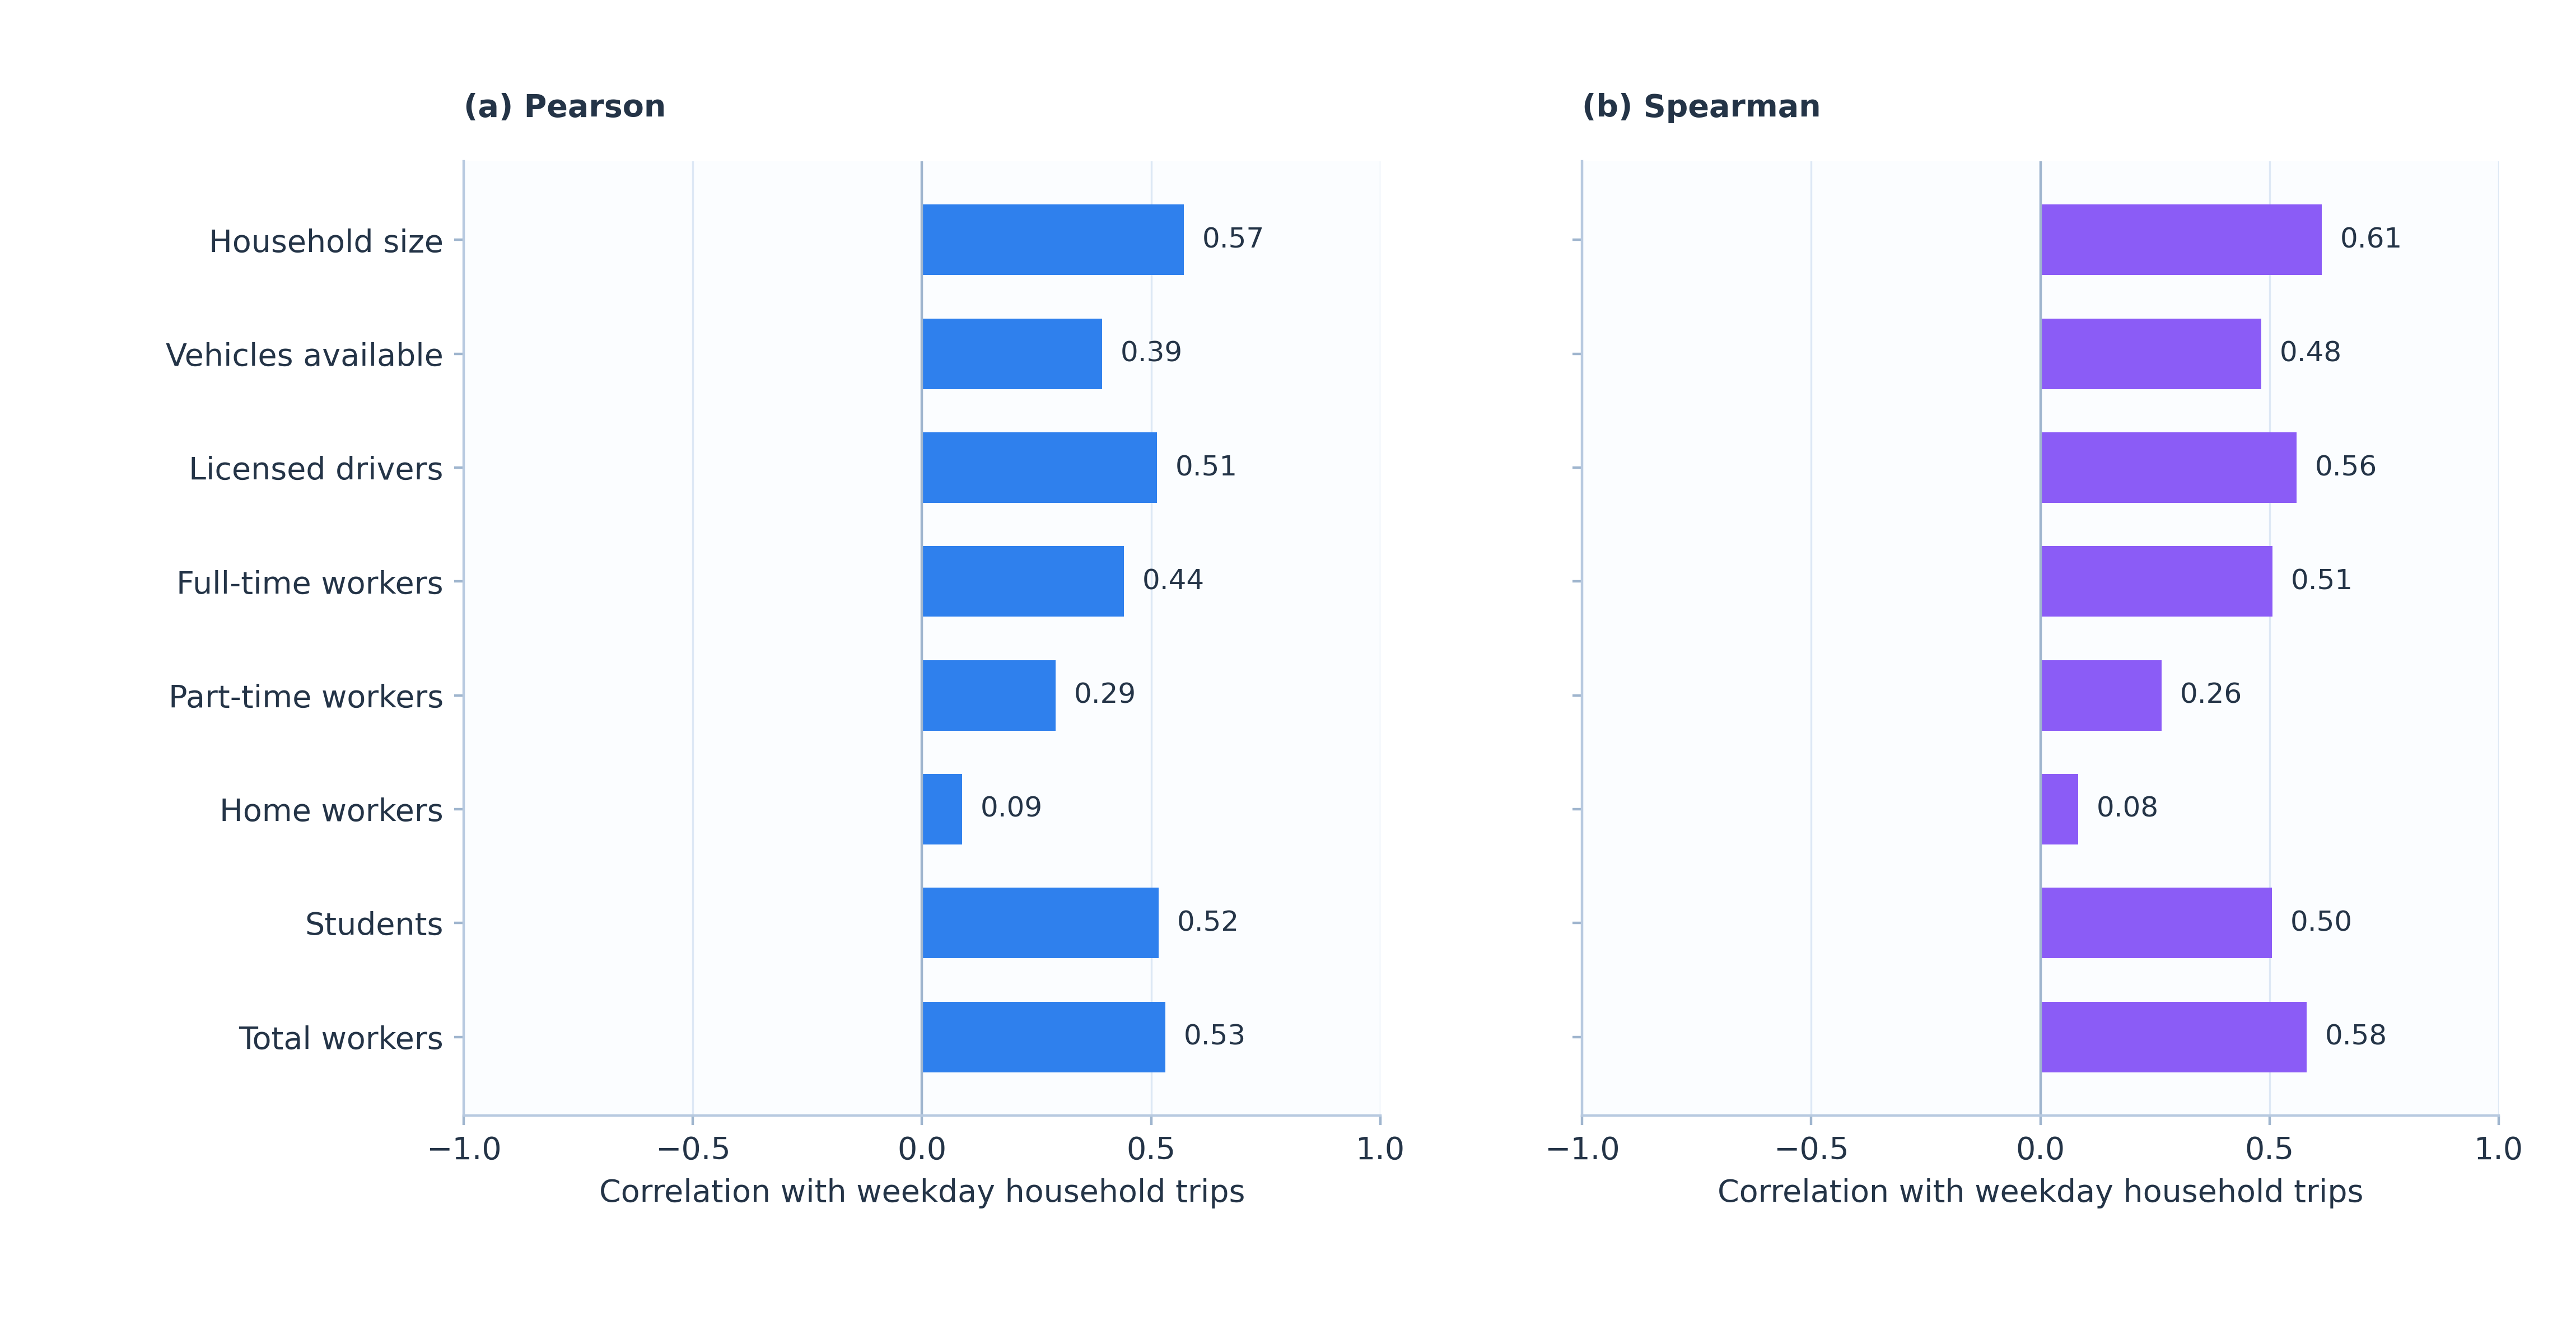

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 6.0), sharey=True)
fig.subplots_adjust(left=.18, right=.97, bottom=.17, top=.88, wspace=.22)
y = np.arange(len(COUNTS))
for ax, metric, colour, label in zip(
        axes, ['pearson', 'spearman'], [BLUE, VIOLET], ['(a) Pearson', '(b) Spearman']):
    values = outcome_correlations[metric].to_numpy()
    ax.barh(y, values, height=.62, color=colour)
    ax.set_yticks(y, outcome_correlations['characteristic'])
    ax.set_xlim(-1, 1)
    ax.set_xticks([-1, -.5, 0, .5, 1])
    ax.set_xlabel('Correlation with weekday household trips')
    style_axes(ax)
    ax.grid(False, axis='y')
    ax.grid(axis='x', color='#DDE8F5', linewidth=.6)
    ax.axvline(0, color='#9FB5CE', linewidth=.8)
    panel(ax, label)
    for position, value in zip(y, values):
        offset = .04 if value >= 0 else -.04
        ax.text(value + offset, position, f'{value:.2f}', va='center',
                ha='left' if value >= 0 else 'right', color=INK, fontsize=9)
axes[0].invert_yaxis()
save_figure(fig, 'Figure_ED08')

## 13. Regional variation and zone support

In [38]:
regional = []
for region in ORDERS['region']:
    subset = analysis.loc[analysis['region'].eq(region)]
    block = cell_statistics(subset, 5, 3)
    block.insert(0, 'region', region)
    block['share_of_region_pct'] = 100 * block['n'] / len(subset)
    block['weighted_share_of_region_pct'] = 100 * block['weight_sum'] / subset['expf'].sum()
    regional.append(block)
tables['ED11_regional_cells'] = pd.concat(regional, ignore_index=True)
tables['ED11_regional_cells'].to_csv(TABLES / 'ED11_regional_cells.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
zone = zones.copy()
tables['ED12_zone_support'] = zone.reset_index().rename(columns={'gta01hhld': 'zone'})
tables['ED12_zone_support'].to_csv(TABLES / 'ED12_zone_support.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')

show(tables['ED11_regional_cells'])
show(tables['ED12_zone_support'])

,region,size,vehicles,n,mean_trips,sd_trips,median_trips,zero_n,weight_sum,zero_pct,...,weighted_zero_pct,source_n,groupable_n,excluded_missing_group_n,scheme,size_label,vehicle_label,support_below_30,share_of_region_pct,weighted_share_of_region_pct
0,Toronto,1,0,7031,1.400085,1.461091,2.0,3119,135921.93,44.360688,...,43.929563,51612,51612,0,5+ persons by 3+ vehicles,1,0,False,13.622801,13.879303
1,Toronto,1,1,6256,2.543159,1.911317,2.0,1215,118660.63,19.421355,...,19.266298,51612,51612,0,5+ persons by 3+ vehicles,1,1,False,12.121212,12.116711
2,Toronto,1,2,318,2.86478,2.079785,2.0,50,5954.87,15.723270,...,15.486316,51612,51612,0,5+ persons by 3+ vehicles,1,2,False,0.616136,0.608066
3,Toronto,1,3,68,3.073529,2.039287,3.0,10,1288.41,14.705882,...,15.369331,51612,51612,0,5+ persons by 3+ vehicles,1,3+,False,0.131752,0.131563
4,Toronto,2,0,3561,2.875597,2.278249,3.0,903,69249.4,25.358045,...,24.8415,51612,51612,0,5+ persons by 3+ vehicles,2,0,False,6.899558,7.071216
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,Peel,4,3,766,9.550914,4.405510,9.0,6,14965.71,0.783290,...,0.8603,17945,17945,0,5+ persons by 3+ vehicles,4,3+,False,4.268598,4.168365
76,Peel,5,0,41,5.853659,3.475349,6.0,3,862.15,7.317073,...,6.8074,17945,17945,0,5+ persons by 3+ vehicles,5+,0,False,0.228476,0.240133
77,Peel,5,1,701,8.603424,5.104585,8.0,11,14246.84,1.569187,...,1.661983,17945,17945,0,5+ persons by 3+ vehicles,5+,1,False,3.906381,3.968139
78,Peel,5,2,1429,10.342197,6.129877,9.0,7,28420.6,0.489853,...,0.468252,17945,17945,0,5+ persons by 3+ vehicles,5+,2,False,7.963221,7.915924


,zone,households,known_vehicle_households,known_dwelling_households,both_known_households
0,1,88,88,88,88
1,2,110,110,110,110
2,5,2,2,2,2
3,6,142,142,142,142
4,7,111,111,111,111
...,...,...,...,...,...
1174,1749,69,69,69,69
1175,1750,1,1,1,1
1176,1751,54,54,54,54
1177,1752,35,35,35,35


## 14. Sensitivity analysis

In [39]:
sensitivity = []
for name, frame in [('Full dataset', analysis),
                    ('Recorded vehicles below 10 (sensitivity only)', analysis.loc[~analysis['high_vehicle']])]:
    row = group_statistics(frame.assign(group=name), ['group']).iloc[0].to_dict()
    row['weighted_minus_unweighted'] = row['weighted_mean_trips'] - row['mean_trips']
    sensitivity.append(row)
tables['ED10_overall_sensitivity'] = pd.DataFrame(sensitivity)
tables['ED10_overall_sensitivity'].to_csv(TABLES / 'ED10_overall_sensitivity.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')

sensitive = analysis.loc[~analysis['high_vehicle']]
all_cells = cell_statistics(analysis, 5, 3)
low_cells = cell_statistics(sensitive, 5, 3)
comparison = all_cells.merge(low_cells, on=['size', 'vehicles'], suffixes=('_all', '_under10'))
comparison['mean_change_under10_minus_all'] = comparison['mean_trips_under10'] - comparison['mean_trips_all']
tables['ED14_cell_vehicle_sensitivity'] = comparison[
    ['size', 'vehicles', 'n_all', 'n_under10', 'mean_trips_all', 'mean_trips_under10',
     'mean_change_under10_minus_all']]
tables['ED14_cell_vehicle_sensitivity'].to_csv(TABLES / 'ED14_cell_vehicle_sensitivity.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')


show(tables['ED10_overall_sensitivity'])
show(tables['ED14_cell_vehicle_sensitivity'])

,group,n,mean_trips,sd_trips,median_trips,zero_n,weight_sum,zero_pct,weighted_mean_trips,weighted_zero_pct,source_n,groupable_n,excluded_missing_group_n,weighted_minus_unweighted
0,Full dataset,93307,5.643253,4.562479,4.0,10480,1808648.44,11.23174,5.640092,11.158846,93307,93307,0,-0.003160
1,Recorded vehicles below 10 (sensitivity only),93274,5.642816,4.562260,4.0,10478,1807991.14,11.23357,5.639728,11.160730,93274,93274,0,-0.003088


,size,vehicles,n_all,n_under10,mean_trips_all,mean_trips_under10,mean_change_under10_minus_all
0,1,0,8433,8433,1.324558,1.324558,0.0
1,1,1,9954,9954,2.556359,2.556359,0.0
2,1,2,671,671,2.80775,2.80775,0.0
3,1,3,142,140,3.140845,3.114286,-0.026559
4,2,0,4109,4109,2.780239,2.780239,0.0
5,2,1,13607,13607,4.257074,4.257074,0.0
6,2,2,10040,10040,5.011554,5.011554,0.0
7,2,3,1064,1057,5.520677,5.513718,-0.006959
8,3,0,1500,1500,4.141333,4.141333,0.0
9,3,1,6493,6493,6.006623,6.006623,0.0


## 15. Expected and observed patterns

In [40]:
exact = tables['ED05_exact_group_trip_rates']
rows = []
for field, (expectation, basis) in EXPECTATIONS.items():
    group = exact.loc[exact['variable'].eq(field)].copy()
    is_numeric = field not in ['dwelling', 'weekday']
    positive = negative = flat = 0
    differences = []
    if is_numeric:
        group = group.assign(_level=group['level'].astype(int)).sort_values('_level')
        for (_, a), (_, b) in zip(group.iloc[:-1].iterrows(), group.iloc[1:].iterrows()):
            if b['_level'] == a['_level'] + 1 and min(a['n'], b['n']) >= 30:
                d = b['mean_trips'] - a['mean_trips']
                positive += int(d > 0)
                negative += int(d < 0)
                flat += int(d == 0)
                differences.append(f'{int(a["_level"])} to {int(b["_level"])}: {d:+.2f}')
    observation = '; '.join(
        f'{r["level"]}: {r["mean_trips"]:.2f} trips (n={int(r["n"]):,})'
        for _, r in group.iterrows())
    sparse = group.loc[group['n'].lt(30)]
    sparse_description = '; '.join(f'{r["level"]} (n={int(r["n"])})' for _, r in sparse.iterrows())
    if not is_numeric:
        assessment = 'Descriptive differences; no signed expectation'
    elif field == 'nemphome':
        assessment = 'Unadjusted pattern is mixed; the conditional expectation is not assessed by EDA'
    else:
        assessment = (f'{positive} positive, {negative} negative and {flat} unchanged adjacent '
                      'contrasts with at least 30 households at both exact levels; '
                      'descriptive consistency, not hypothesis confirmation')
    rows.append({
        'characteristic': group.iloc[0]['characteristic'], 'expectation': expectation,
        'basis': basis, 'observation': observation, 'assessment': assessment,
        'interpretation': 'Unadjusted; no hypothesis confirmation or causal effect',
        'positive_supported_steps': positive, 'negative_supported_steps': negative,
        'unchanged_supported_steps': flat,
        'supported_adjacent_differences': '; '.join(differences) or 'Not applicable',
        'exact_levels_individually_below_30': sparse_description or 'None',
        'households_in_those_exact_levels': int(sparse['n'].sum()),
        'support_rule': '30 per exact level is a project review convention, not guaranteed precision',
    })
tables['ED15_expected_versus_observed'] = pd.DataFrame(rows)
tables['ED15_expected_versus_observed'].to_csv(TABLES / 'ED15_expected_versus_observed.csv', index=False, encoding='utf-8-sig', lineterminator='\n', float_format='%.10g')
show(tables['ED15_expected_versus_observed'][['characteristic', 'expectation', 'assessment']])

,characteristic,expectation,assessment
0,Household size,Generally positive; increments need not be con...,"9 positive, 0 negative and 0 unchanged adjacen..."
1,Vehicles available,Generally positive; increments need not be con...,"6 positive, 0 negative and 0 unchanged adjacen..."
2,Licensed drivers,Generally positive through mobility access,"6 positive, 0 negative and 0 unchanged adjacen..."
3,Full-time workers,"Generally positive for total trips, with possi...","5 positive, 0 negative and 0 unchanged adjacen..."
4,Part-time workers,"Generally positive for total trips, with possi...","4 positive, 0 negative and 0 unchanged adjacen..."
5,Home workers,No direction conditional on full-time and part...,Unadjusted pattern is mixed; the conditional e...
6,Students,Generally positive through education and escor...,"6 positive, 0 negative and 0 unchanged adjacen..."
7,Dwelling type,No predetermined ranking,Descriptive differences; no signed expectation
8,Survey weekday,No predetermined ranking,Descriptive differences; no signed expectation


## 16. Check analysis totals

In [41]:
assert len(analysis) == len(raw) == len(master), 'Full-dataset EDA lost households.'
assert tables['ED04_trip_distribution']['n'].sum() == len(analysis), 'Trip-frequency total differs from the full dataset.'
for (field, view), block in tables['ED16_trip_frequencies'].groupby(['variable', 'view']):
    assert block['n'].sum() == analysis[field].notna().sum(), f'Joint-frequency total differs: {field}, {view}'
assert tables['ED07_classification_cells'].groupby('scheme')['n'].sum().eq(analysis['nvehicle_clean'].notna().sum()).all(), 'Vehicle-classification totals differ.'
assert tables['ED18_driver_classification_cells'].groupby('scheme')['n'].sum().eq(len(analysis)).all(), 'Driver-classification totals differ.'
assert tables['ED12_zone_support']['households'].sum() == len(analysis), 'Zone total differs.'
show(sample_summary)
print('Full-dataset sample and denominator checks passed.')

,Cohort,Households,Zones represented,Use
0,Full dataset (main EDA),93307,1179,Main EDA; no exclusions
1,Known vehicle count (diagnostic only),93307,1179,Provisional diagnostic; not a final model sample
2,Known vehicle and dwelling (diagnostic only),93298,1179,Provisional diagnostic; not a final model sample
3,"Known vehicle/dwelling, fewer than 10 vehicles...",93265,1179,Provisional diagnostic; not a final model sample


Full-dataset sample and denominator checks passed.


## 17. Preparation checks before multiple linear regression

Audit available values, category support, unusual records, variable roles, and candidate predictor matrices using the full dataset. No trip-outcome model is fitted and no rows are removed. Candidate designs diagnose encoding and collinearity only; their complete-case counts are not final exclusion decisions. The report and check tables are regenerated by this section.

In [42]:
# This code is embedded in the EDA notebook by append_pre_model_checks.py.
# It inspects candidate designs without fitting a trip-outcome regression.

def save_review_table(name, frame):
    tables[name] = frame
    frame.to_csv(TABLES / f'{name}.csv', index=False, encoding='utf-8-sig',
                 lineterminator='\n', float_format='%.10g')
    return frame


numeric_audit = []
for field in COUNTS + ['nhhldtrip', 'expf']:
    x = analysis[field].dropna().astype(float)
    q1, q3 = x.quantile([.25, .75])
    iqr = q3 - q1
    numeric_audit.append({
        'variable': field, 'source_n': len(analysis), 'available_n': len(x),
        'missing_n': len(analysis) - len(x), 'unique_values': x.nunique(),
        'mean': x.mean(), 'sd': x.std(), 'min': x.min(), 'p25': q1,
        'median': x.median(), 'p75': q3, 'p95': x.quantile(.95),
        'p99': x.quantile(.99), 'max': x.max(), 'zero_n': int(x.eq(0).sum()),
        'zero_pct_available': 100 * x.eq(0).mean(), 'skewness': x.skew(),
        'outside_1_5_IQR_n': int((x.lt(q1 - 1.5 * iqr) | x.gt(q3 + 1.5 * iqr)).sum()),
        'IQR_interpretation': 'Descriptive only; not an exclusion rule; can flag common nonzero counts when IQR is zero',
    })
numeric_audit = save_review_table('MLR01_numeric_readiness', pd.DataFrame(numeric_audit))
show(numeric_audit)

,variable,source_n,available_n,missing_n,unique_values,mean,sd,min,p25,median,p75,p95,p99,max,zero_n,zero_pct_available,skewness,outside_1_5_IQR_n,IQR_interpretation
0,nperson,93307,93307,0,14,2.741177,1.418985,1.00,2.00,2.00,4.00,5.0,7.00,16.00,0,0.000000,0.803153,349,Descriptive only; not an exclusion rule; can f...
1,nvehicle_clean,93307,93307,0,21,1.383347,1.025687,0.00,1.00,1.00,2.00,3.0,4.00,99.00,15295,16.392125,11.315548,1915,Descriptive only; not an exclusion rule; can f...
2,nlicence,93307,93307,0,10,1.730095,0.982728,0.00,1.00,2.00,2.00,3.0,4.00,9.00,8964,9.606996,0.477215,4515,Descriptive only; not an exclusion rule; can f...
3,nempft,93307,93307,0,8,1.113025,0.926627,0.00,0.00,1.00,2.00,3.0,4.00,7.00,27902,29.903437,0.503906,17,Descriptive only; not an exclusion rule; can f...
4,nemppt,93307,93307,0,6,0.238235,0.511955,0.00,0.00,0.00,0.00,1.0,2.00,5.00,74410,79.747500,2.308762,18897,Descriptive only; not an exclusion rule; can f...
5,nemphome,93307,93307,0,6,0.108041,0.354863,0.00,0.00,0.00,0.00,1.0,2.00,7.00,84512,90.574126,3.634713,8795,Descriptive only; not an exclusion rule; can f...
6,nstudent,93307,93307,0,10,0.635151,0.953827,0.00,0.00,0.00,1.00,3.0,4.00,9.00,57826,61.973914,1.529894,4861,Descriptive only; not an exclusion rule; can f...
7,workers,93307,93307,0,11,1.351260,1.049564,0.00,1.00,1.00,2.00,3.0,4.00,10.00,22980,24.628377,0.520567,2823,Descriptive only; not an exclusion rule; can f...
8,nhhldtrip,93307,93307,0,48,5.643253,4.562479,0.00,2.00,4.00,8.00,14.0,21.00,55.00,10480,11.231740,1.506328,2129,Descriptive only; not an exclusion rule; can f...
9,expf,93307,93307,0,418,19.383845,2.508741,10.83,17.67,19.35,20.98,23.5,26.13,28.06,0,0.000000,0.078291,2079,Descriptive only; not an exclusion rule; can f...


In [43]:
category_audit = []
for field in ['dwelling', 'weekday', 'region', 'rec-mail']:
    for level, block in analysis.groupby(field, dropna=False, sort=False):
        category_audit.append({
            'variable': field, 'level': str(level), 'n': len(block),
            'percent_full_dataset': 100 * len(block) / len(analysis),
            'mean_trips_unadjusted': block['nhhldtrip'].mean(),
            'zero_trip_pct': 100 * block['zero_trip'].mean(),
            'review_below_30': len(block) < SUPPORT_REVIEW_N,
        })
category_audit = save_review_table('MLR02_category_readiness', pd.DataFrame(category_audit))
show(category_audit)

,variable,level,n,percent_full_dataset,mean_trips_unadjusted,zero_trip_pct,review_below_30
0,dwelling,House,58360,62.546218,6.564873,7.943797,False
1,dwelling,Apartment,27977,29.983817,3.621654,19.465990,False
2,dwelling,Townhouse,6961,7.460319,6.043097,5.660106,False
3,dwelling,Unknown,9,0.009646,4.444444,44.444444,True
4,weekday,Thursday,19414,20.806585,5.623210,10.585145,False
5,weekday,Wednesday,17728,18.999646,5.681634,11.112365,False
6,weekday,Friday,21240,22.763565,5.863183,10.597928,False
7,weekday,Tuesday,18273,19.583740,5.561484,11.733158,False
8,weekday,Monday,16652,17.846464,5.434963,12.370886,False
9,region,Toronto,51612,55.314178,4.918527,14.186623,False


In [44]:
# These markers request inspection; every marked household remains in the EDA.
review_masks = {
    'vehicle_numeric_99_review': analysis['vehicle_99_review'],
    'unknown_dwelling_9': analysis['unknown_dwelling'],
    'known_vehicles_at_least_10': analysis['high_vehicle'],
    'household_size_at_least_10': analysis['nperson'].ge(10),
    'recorded_trips_at_least_30': analysis['nhhldtrip'].ge(30),
}
review_flags = pd.DataFrame(review_masks).fillna(False)
review_rows = analysis.loc[review_flags.any(axis=1), FIELDS + ['nvehicle_clean', 'workers']].copy()
review_rows['review_reasons'] = review_flags.loc[review_rows.index].apply(
    lambda row: '; '.join(row.index[row]), axis=1)
review_rows['action'] = 'Retained; inspect before any model exclusion decision'
save_review_table('MLR03_rows_for_review', review_rows)
review_summary = save_review_table('MLR04_review_flag_counts', pd.DataFrame([
    {'flag': name, 'households': int(mask.sum()), 'decision': 'Review only; no deletion'}
    for name, mask in review_masks.items()
]))
show(review_summary)

,flag,households,decision
0,vehicle_numeric_99_review,1,Review only; no deletion
1,unknown_dwelling_9,9,Review only; no deletion
2,known_vehicles_at_least_10,33,Review only; no deletion
3,household_size_at_least_10,58,Review only; no deletion
4,recorded_trips_at_least_30,112,Review only; no deletion


In [45]:
role_rows = [
    ('hnum', 'Exclude from predictors', 'Household ID for traceability', 'No encoding'),
    ('gta01hhld', 'Aggregation / clustering', 'Zone identifier; numerical spacing has no quantitative meaning; consider zone-clustered uncertainty later', 'Do not enter as a numeric slope or blindly create 1,178 dummies'),
    ('nperson', 'Core candidate', 'Retain exact counts initially; inspect diminishing increments; includes children under 11', 'Numeric count; do not automatically one-hot encode'),
    ('nvehicle_clean', 'Core candidate / alternative access measure', 'All recorded counts 0-99 retained per guide; extreme values are numeric influence/sensitivity candidates; compare with licensed drivers', 'Numeric count; consider justified nonlinear specification later'),
    ('nlicence', 'Core candidate / alternative access measure', 'Shares household-size and mobility-access information; use design VIF rather than marginal correlations alone', 'Numeric count'),
    ('nempft', 'Composition candidate', 'Use with nemppt OR replace both by workers; not all three', 'Numeric count'),
    ('nemppt', 'Composition candidate', 'Separate coefficient can represent a different association from full-time employment', 'Numeric count'),
    ('workers', 'Alternative to nempft + nemppt', 'Exact arithmetic sum; including all three creates perfect collinearity', 'Numeric count'),
    ('nemphome', 'Optional composition refinement', 'Already included in employment totals; adding as a separate regressor is a conditional contrast, not adding people; do not add again to workers', 'Numeric count; assess adjusted contribution later'),
    ('nstudent', 'Composition candidate', 'Can overlap employment; includes ages 6-10 while trips are recorded for ages 11+; interpret association carefully', 'Numeric count'),
    ('dwelltype_clean / dwelling', 'Candidate categorical control', 'House, Apartment, Townhouse; nine source-documented unknowns need a missing-data decision; never treat code 9 as a dwelling magnitude', 'Known categories: 2 indicators plus intercept, House reference; Unknown fourth level only as explicit sensitivity'),
    ('tripday / weekday', 'Candidate categorical control', 'Monday-Friday are categories; coding 1-5 numerically would impose an equal linear daily increment', '4 indicators plus intercept, Monday reference'),
    ('region', 'Optional geographic control', 'Derived from documented zone ranges; broad geographic differences can confound household associations', '3 indicators plus intercept, Toronto reference'),
    ('rec-mail', 'Exclude from substantive predictor set', 'Advance-letter receipt describes survey administration; code 9 is unknown; optional nonresponse/survey sensitivity only', 'If explicitly studied later: Y/N indicator and separate unknown handling'),
    ('n-call', 'Exclude from substantive predictor set', 'Interview completion / edits describe survey process rather than a household travel-generating characteristic', 'No main-model encoding'),
    ('expf', 'Weight / expansion', 'Not a trip-generating predictor; state an explicit weighting convention and use it consistently for observed and predicted totals', 'Not an explanatory variable'),
    ('nhhldtrip', 'Outcome', 'Recorded weekday person trips; retain zeros; count-valued/skewed outcome does not by itself forbid assigned linear regression', 'Numeric outcome; do not one-hot encode'),
    ('split / flags / display categories', 'Exclude from substantive predictor set', 'Historical partition labels, diagnostic flags, and display caps are not substantive regressors; do not include both raw and derived copies', 'No automatic encoding'),
]
variable_roles = save_review_table('MLR05_variable_roles', pd.DataFrame(
    role_rows, columns=['variable', 'provisional_role', 'reason', 'encoding']))
show(variable_roles)

,variable,provisional_role,reason,encoding
0,hnum,Exclude from predictors,Household ID for traceability,No encoding
1,gta01hhld,Aggregation / clustering,Zone identifier; numerical spacing has no quan...,Do not enter as a numeric slope or blindly cre...
2,nperson,Core candidate,Retain exact counts initially; inspect diminis...,Numeric count; do not automatically one-hot en...
3,nvehicle_clean,Core candidate / alternative access measure,All recorded counts 0-99 retained per guide; e...,Numeric count; consider justified nonlinear sp...
4,nlicence,Core candidate / alternative access measure,Shares household-size and mobility-access info...,Numeric count
5,nempft,Composition candidate,Use with nemppt OR replace both by workers; no...,Numeric count
6,nemppt,Composition candidate,Separate coefficient can represent a different...,Numeric count
7,workers,Alternative to nempft + nemppt,Exact arithmetic sum; including all three crea...,Numeric count
8,nemphome,Optional composition refinement,Already included in employment totals; adding ...,Numeric count; assess adjusted contribution later
9,nstudent,Composition candidate,Can overlap employment; includes ages 6-10 whi...,Numeric count


In [46]:
# Design diagnostics regress predictors on other predictors; y is not used.
REF_LEVELS = {
    'dwelling': ['House', 'Apartment', 'Townhouse'],
    'weekday': ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'],
    'region': ['Toronto', 'Durham', 'York', 'Peel'],
}
scenarios = {
    'Size and licensed drivers': (['nperson', 'nlicence'], []),
    'Size and vehicles': (['nperson', 'nvehicle_clean'], []),
    'Size, drivers and vehicles': (['nperson', 'nlicence', 'nvehicle_clean'], []),
    'Separate employment counts + controls': (
        ['nperson', 'nvehicle_clean', 'nlicence', 'nempft', 'nemppt', 'nstudent', 'nemphome'],
        ['dwelling', 'weekday', 'region']),
    'Total workers alternative + controls': (
        ['nperson', 'nvehicle_clean', 'nlicence', 'workers', 'nstudent', 'nemphome'],
        ['dwelling', 'weekday', 'region']),
    'Invalid: workers and both employment components': (
        ['nperson', 'nvehicle_clean', 'nlicence', 'nempft', 'nemppt', 'workers', 'nstudent'], []),
}
design_rows, vif_rows, eligibility_rows = [], [], []
for name, (numeric_fields, categorical_fields) in scenarios.items():
    needed = numeric_fields + categorical_fields
    valid = analysis[needed].notna().all(axis=1)
    # Unknown is an EDA label, not a valid known dwelling type in these diagnostic designs.
    if 'dwelling' in categorical_fields:
        valid &= analysis['dwelling'].isin(REF_LEVELS['dwelling'])
    frame = analysis.loc[valid]
    design = frame[numeric_fields].astype(float).copy()
    for field in categorical_fields:
        values = pd.Categorical(frame[field], categories=REF_LEVELS[field], ordered=True)
        dummies = pd.get_dummies(values, prefix=field, drop_first=True, dtype=float)
        dummies.index = frame.index
        design = pd.concat([design, dummies], axis=1)
    zero_variance = design.columns[design.std(ddof=0).eq(0)].tolist()
    assert not zero_variance, f'Constant diagnostic columns: {zero_variance}'
    standardized = (design - design.mean()) / design.std(ddof=0)
    z = standardized.to_numpy(dtype=float)
    corr = z.T @ z / len(z)
    # Diagnose rank on the design itself: a Gram/correlation matrix squares
    # the condition number and can obscure exact dependencies through rounding.
    singular_values = np.linalg.svd(z, compute_uv=False)
    tolerance = singular_values.max() * max(z.shape) * np.finfo(float).eps
    rank = int((singular_values > tolerance).sum()) + 1  # centered columns + intercept
    columns_with_intercept = design.shape[1] + 1
    full_rank = rank == columns_with_intercept
    # An intercept has norm sqrt(n); standardized predictor columns do too.
    spectrum = np.append(singular_values, np.sqrt(len(z)))
    condition = float(spectrum.max() / spectrum.min()) if full_rank else np.inf
    vifs = np.diag(np.linalg.inv(corr)) if full_rank else None
    design_rows.append({
        'scenario': name, 'available_n': len(frame), 'unavailable_n': len(analysis) - len(frame),
        'columns_including_intercept': columns_with_intercept, 'rank': rank,
        'full_rank': full_rank, 'standardized_condition_number': condition,
        'max_column_VIF': float(vifs.max()) if full_rank else np.nan,
        'status': 'Candidate design only; no outcome model fitted' if full_rank else 'Do not fit: exact linear dependence',
    })
    for i, col in enumerate(design.columns):
        vif_rows.append({'scenario': name, 'predictor': col, 'available_n': len(frame),
                         'VIF': float(vifs[i]) if full_rank else np.nan,
                         'interpretation': 'Column-specific VIF; no mechanical cutoff or variable deletion' if full_rank
                         else 'Undefined for this rank-deficient design; remove algebraic duplication'})
    for field in numeric_fields:
        eligibility_rows.append({'scenario': name, 'issue': f'Missing {field}',
                                 'households': int(analysis[field].isna().sum()),
                                 'note': 'Reason counts may overlap; diagnostic availability only'})
    if 'dwelling' in categorical_fields:
        eligibility_rows.append({'scenario': name, 'issue': 'Unknown dwelling',
                                 'households': int(analysis['unknown_dwelling'].sum()),
                                 'note': 'Reason counts may overlap; diagnostic availability only'})
design_audit = save_review_table('MLR06_candidate_designs', pd.DataFrame(design_rows))
vif_audit = save_review_table('MLR07_design_VIF', pd.DataFrame(vif_rows))
save_review_table('MLR08_design_availability', pd.DataFrame(eligibility_rows))
assert analysis['workers'].eq(analysis['nempft'] + analysis['nemppt']).all()
assert not bool(design_audit.loc[design_audit['scenario'].str.startswith('Invalid'), 'full_rank'].iloc[0])
show(design_audit)
show(vif_audit.loc[vif_audit['VIF'].notna()].sort_values('VIF', ascending=False).head(20))

,scenario,available_n,unavailable_n,columns_including_intercept,rank,full_rank,standardized_condition_number,max_column_VIF,status
0,Size and licensed drivers,93307,0,3,3,True,1.996236,1.558976,Candidate design only; no outcome model fitted
1,Size and vehicles,93307,0,3,3,True,1.534254,1.194689,Candidate design only; no outcome model fitted
2,"Size, drivers and vehicles",93307,0,4,4,True,2.663215,2.239612,Candidate design only; no outcome model fitted
3,Separate employment counts + controls,93298,9,17,17,True,3.987082,3.159312,Candidate design only; no outcome model fitted
4,Total workers alternative + controls,93298,9,16,16,True,3.921234,3.101782,Candidate design only; no outcome model fitted
5,Invalid: workers and both employment components,93307,0,8,7,False,inf,NaN,Do not fit: exact linear dependence


,scenario,predictor,available_n,VIF,interpretation
7,Separate employment counts + controls,nperson,93298,3.159312,Column-specific VIF; no mechanical cutoff or v...
23,Total workers alternative + controls,nperson,93298,3.101782,Column-specific VIF; no mechanical cutoff or v...
9,Separate employment counts + controls,nlicence,93298,2.611638,Column-specific VIF; no mechanical cutoff or v...
25,Total workers alternative + controls,nlicence,93298,2.608039,Column-specific VIF; no mechanical cutoff or v...
5,"Size, drivers and vehicles",nlicence,93307,2.239612,Column-specific VIF; no mechanical cutoff or v...
12,Separate employment counts + controls,nstudent,93298,2.090122,Column-specific VIF; no mechanical cutoff or v...
27,Total workers alternative + controls,nstudent,93298,2.000702,Column-specific VIF; no mechanical cutoff or v...
26,Total workers alternative + controls,workers,93298,1.951638,Column-specific VIF; no mechanical cutoff or v...
8,Separate employment counts + controls,nvehicle_clean,93298,1.909355,Column-specific VIF; no mechanical cutoff or v...
24,Total workers alternative + controls,nvehicle_clean,93298,1.901261,Column-specific VIF; no mechanical cutoff or v...


In [47]:
w = analysis['expf'].astype(float)
weight_audit = save_review_table('MLR09_weight_and_zone_readiness', pd.DataFrame([
    {'measure': 'Households retained', 'value': len(analysis)},
    {'measure': 'Zones', 'value': analysis['gta01hhld'].nunique()},
    {'measure': 'Zones with one household', 'value': int(zones['households'].eq(1).sum())},
    {'measure': 'Zones with fewer than 5 households', 'value': int(zones['households'].lt(5).sum())},
    {'measure': 'Minimum expansion factor', 'value': w.min()},
    {'measure': 'Maximum expansion factor', 'value': w.max()},
    {'measure': 'Weight coefficient of variation', 'value': w.std(ddof=0) / w.mean()},
    {'measure': 'Kish weight-only effective n (not design-adjusted)', 'value': w.sum() ** 2 / (w @ w)},
    {'measure': 'Unweighted mean trips', 'value': analysis['nhhldtrip'].mean()},
    {'measure': 'Expansion-weighted mean trips', 'value': np.average(analysis['nhhldtrip'], weights=w)},
]))
show(weight_audit)

,measure,value
0,Households retained,93307.000000
1,Zones,1179.000000
2,Zones with one household,80.000000
3,Zones with fewer than 5 households,149.000000
4,Minimum expansion factor,10.830000
5,Maximum expansion factor,28.060000
6,Weight coefficient of variation,0.129424
7,Kish weight-only effective n (not design-adjus...,91769.811794
8,Unweighted mean trips,5.643253
9,Expansion-weighted mean trips,5.640092


In [48]:
def markdown_table(frame):
    # Keep the review self-contained without adding a tabulate dependency.
    data = frame.astype(object).where(frame.notna(), '')
    rows = ['| ' + ' | '.join(map(str, data.columns)) + ' |',
            '| ' + ' | '.join(['---'] * len(data.columns)) + ' |']
    for row in data.itertuples(index=False, name=None):
        cells = [str(v).replace('|', '/').replace('\n', ' ') for v in row]
        rows.append('| ' + ' | '.join(cells) + ' |')
    return '\n'.join(rows)

outcome = numeric_audit.set_index('variable').loc['nhhldtrip']
vehicle_missing_n = int(analysis['nvehicle_clean'].isna().sum())
unknown_dwelling = int(analysis['unknown_dwelling'].sum())
report = f"""# Full-dataset EDA and regression preparation review

All {len(analysis):,} households remain in the EDA, without a training/test partition. Original source files and historical split artifacts are preserved. These are descriptive and predictor-design checks; no trip-outcome regression is fitted and no final row-exclusion rule is selected.

## Source-dictionary correction

The supplied [2006 TTS Version 1.0 Data Guide](../inputs/dataguide2006_v1.pdf), printed page 18 (PDF page 23), defines n_vehicle as a 0-99 count. Printed page 51 (PDF page 56) explicitly tabulates 99 with description 99 and one 2006 record. The earlier provisional assumption that 99 meant missing has been withdrawn. It is retained numerically in nvehicle_clean. There are {vehicle_missing_n} unavailable vehicle measurements in this file, {int(analysis['vehicle_99_review'].sum())} numeric value of 99, and {int(analysis['high_vehicle'].sum())} records with at least 10 vehicles.

The guide also publishes extreme counts such as 21, 23, and 36. This supports treating them as source-recorded values rather than errors inferred from rarity; it does not prove each response is accurate or that a linear vehicle effect is appropriate. The main analysis retains them, with explicit influence/functional-form sensitivity checks. The numeric 99 record is not a missing-data exclusion candidate.

Dwelling code 9 is explicitly Unknown (printed p. 17 / PDF p. 22); {unknown_dwelling} such records remain labeled Unknown in EDA. Complete-case models requiring a known dwelling have {int(analysis['eligible_comparison'].sum()):,} households. Models without dwelling need not exclude them. Advance-letter code 9 is also Unknown but does not require row exclusion when that survey-process field is not a predictor.

The guide confirms home workers are already included in full-/part-time employment counts (p. 18), separate employment/student statuses can overlap and ages 6-10 are assumed full-time students (p. 2), and 2006 recorded trips cover ages 11+ (pp. 1, 51). Numeric 9 in licence, employment, or student counts is not automatically an unknown code. Region mapping correctly uses the 2001 zone system for gta01hhld (p. 14), even though the survey is from 2006.

## Full-data findings and variable roles

Trips average {outcome['mean']:.3f}, with median {outcome['median']:.0f}, maximum {outcome['max']:.0f}, and {int(outcome['zero_n']):,} zero-trip households ({outcome['zero_pct_available']:.2f}%). Keep zeros, overlapping statuses, and high outcomes unless independent evidence justifies a narrower study population. All existing raw numeric/code and within-household consistency checks pass.

{markdown_table(variable_roles)}

Use k-1 indicator columns with an intercept for included categorical controls: two for known dwelling types, four for weekdays, and three for region. Counts may start numeric, with justified nonlinear alternatives. The nine Unknown dwellings may be handled through a documented complete-case rule or a sparse Unknown-category sensitivity; do not silently map Unknown to House. No imputation is performed.

## Predictor matrix checks

{markdown_table(design_audit.round(4))}

VIF measures predictor overlap in the specified design, not individual outliers. Check matrix rank as well. workers is exactly nempft + nemppt, so do not include all three. Separate home-worker counts can enter as conditional composition predictors but must not be added again to workers. Do not select variables from marginal correlations or VIF cutoffs alone. Full designs, leverage, and vehicle-form sensitivities appear in the later review sections. Residual patterns, influence on estimated coefficients, functional form, and appropriate uncertainty require fitted candidate models.

## Review flags and weighting

{markdown_table(review_summary)}

Flags overlap and never automatically delete rows. expf is an expansion factor, not a substantive predictor. Printed page 4 explains expansion using census dwelling-unit controls and common factors within expansion zones. Expansion zones need not equal the traffic zones used for model aggregation. The survey used later-phase sampling adjustments for multi-unit dwellings (p. 2), so similar weighted/unweighted overall means alone do not establish that weights can be ignored. State the estimation/expansion convention, apply weights consistently to observed and predicted totals, and consider zone-clustered uncertainty subject to available survey-design information.

Using the full dataset follows the revised project direction. Any fit/error measured on those same records is in-sample, not held-out predictive accuracy. No regression notebook exists yet.

## Reproducing and supporting sources

Run Household_EDA_updated.ipynb top to bottom using the selected geo_env kernel. The notebook regenerates these tables and reports; it does not read or overwrite the historical split assignment, traiining.csv, testing.csv, or DP04_split_summary.csv. DP04_sample_summary.csv contains current full-data counts. Section 20 records the dictionary reconciliation, including published versus project vehicle frequencies. The older split artifacts retain the prior workflow and should not be interpreted as current coding policy.

- [Source data guide](../inputs/dataguide2006_v1.pdf): printed pp. 1-4, 14, 16-18, 50-53.
- [Statsmodels treatment coding](https://www.statsmodels.org/v0.12.2/examples/notebooks/generated/contrasts.html).
- [Statsmodels VIF](https://www.statsmodels.org/dev/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html).
"""
(FINAL_OUTPUTS / 'MLR_preparation_review.md').write_text(report, encoding='utf-8')
print('Regenerated source-informed regression preparation review; numeric 99 is retained.')
assert len(master) == len(raw) == len(analysis)

Regenerated source-informed regression preparation review; numeric 99 is retained.


## 18. Vehicle-tail, unknown-value, and household review

Inspect recorded vehicle counts against size, licensed drivers, trips, and dwelling type. The supplied guide defines vehicles on 0-99 and explicitly publishes a numeric 99 record (printed pp. 18, 51). This section retains 99 and all other recorded numeric values. Dwelling code 9 is a documented Unknown. Excel rows include the worksheet header. Sensitivity thresholds and descriptive peers are not automatic exclusion rules.

In [49]:
# Retain source-row provenance without changing the master or analysis frame.
vehicle_review_source = raw[FIELDS].reset_index(drop=True).copy()
vehicle_review_source.insert(0, 'source_excel_row', np.arange(len(raw)) + 2)
assert vehicle_review_source['hnum'].is_unique
vehicle_review = analysis.merge(
    vehicle_review_source[['hnum', 'source_excel_row']], on='hnum',
    how='left', validate='one_to_one', sort=False)
assert len(vehicle_review) == len(raw)
assert vehicle_review['source_excel_row'].notna().all()
known_vehicle = vehicle_review['nvehicle_clean'].notna()
tail10 = vehicle_review['nvehicle_clean'].ge(10).fillna(False)
vehicle_review['vehicles_per_resident'] = vehicle_review['nvehicle_clean'] / vehicle_review['nperson']
# A ratio with zero licensed drivers is undefined, not infinite.
vehicle_review['vehicles_per_licensed_driver'] = (
    vehicle_review['nvehicle_clean'] / vehicle_review['nlicence'].where(vehicle_review['nlicence'].gt(0)))
vehicle_review['trips_per_resident'] = vehicle_review['nhhldtrip'] / vehicle_review['nperson']
vehicle_review['vehicles_exceed_residents'] = vehicle_review['nvehicle_clean'].gt(vehicle_review['nperson']).fillna(False)
vehicle_review['vehicles_exceed_licensed_drivers'] = vehicle_review['nvehicle_clean'].gt(vehicle_review['nlicence']).fillna(False)
vehicle_review['vehicle_band'] = np.select(
    [~known_vehicle, vehicle_review['nvehicle_clean'].le(4).fillna(False),
     vehicle_review['nvehicle_clean'].le(6).fillna(False),
     vehicle_review['nvehicle_clean'].le(9).fillna(False),
     vehicle_review['nvehicle_clean'].le(15).fillna(False)],
    ['Missing vehicle measurement', '0-4', '5-6', '7-9', '10-15'], default='16 or more')
vehicle_band_profiles = vehicle_review.groupby('vehicle_band', sort=False).agg(
    households=('hnum', 'size'), min_vehicles=('nvehicle_clean', 'min'),
    max_vehicles=('nvehicle_clean', 'max'), mean_residents=('nperson', 'mean'),
    median_residents=('nperson', 'median'), mean_licensed_drivers=('nlicence', 'mean'),
    median_licensed_drivers=('nlicence', 'median'), mean_trips=('nhhldtrip', 'mean'),
    median_trips=('nhhldtrip', 'median'), min_trips=('nhhldtrip', 'min'),
    max_trips=('nhhldtrip', 'max'), zero_trip_households=('zero_trip', 'sum'),
    vehicles_exceed_residents_n=('vehicles_exceed_residents', 'sum'),
    vehicles_exceed_drivers_n=('vehicles_exceed_licensed_drivers', 'sum')).reset_index()
vehicle_band_profiles['percent_full_dataset'] = 100 * vehicle_band_profiles['households'] / len(analysis)
vehicle_band_profiles = vehicle_band_profiles.set_index('vehicle_band').reindex(
    ['0-4', '5-6', '7-9', '10-15', '16 or more', 'Missing vehicle measurement']).reset_index()
vehicle_band_profiles['households'] = vehicle_band_profiles['households'].fillna(0).astype(int)
save_review_table('RV01_vehicle_band_profiles', vehicle_band_profiles)
vehicle_dwelling_profiles = vehicle_review.groupby(['vehicle_band', 'dwelling'], observed=True).size().reset_index(name='households')
vehicle_dwelling_profiles['percent_within_vehicle_band'] = (
    100 * vehicle_dwelling_profiles['households'] / vehicle_dwelling_profiles.groupby('vehicle_band')['households'].transform('sum'))
save_review_table('RV02_vehicle_dwelling_profiles', vehicle_dwelling_profiles)
show(vehicle_band_profiles.round(3))
print('Vehicles exceeding residents:', int(vehicle_review['vehicles_exceed_residents'].sum()))
print('Vehicles exceeding licensed drivers:', int(vehicle_review['vehicles_exceed_licensed_drivers'].sum()))
print('Those inequalities are not logical impossibilities: residents may own multiple vehicles.')

,vehicle_band,households,min_vehicles,max_vehicles,mean_residents,median_residents,mean_licensed_drivers,median_licensed_drivers,mean_trips,median_trips,min_trips,max_trips,zero_trip_households,vehicles_exceed_residents_n,vehicles_exceed_drivers_n,percent_full_dataset
0,0-4,92907,0,4,2.73495,2.0,1.722368,2.0,5.624592,4.0,0,55,10473.0,2018,4449,99.571
1,5-6,333,5,6,4.342342,4.0,3.708709,4.0,10.351351,10.0,0,44,3.0,189,238,0.357
2,7-9,34,7,9,3.588235,3.5,3.0,3.0,9.323529,8.5,0,22,2.0,32,34,0.036
3,10-15,20,10,15,3.2,3.0,2.2,2.0,6.3,6.0,0,17,1.0,20,20,0.021
4,16 or more,13,21,99,3.307692,3.0,2.230769,2.0,7.769231,7.0,0,23,1.0,13,13,0.014
5,Missing vehicle measurement,0,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN


Vehicles exceeding residents: 2272
Vehicles exceeding licensed drivers: 4754
Those inequalities are not logical impossibilities: residents may own multiple vehicles.


### High-vehicle households and matched descriptive peers

For each household with at least 10 known vehicles, compare trips with households having the **same exact household size, number of licensed drivers, and dwelling type**, and fewer than 10 known vehicles. The 5th–95th percentile range is descriptive, not a confidence interval or an outlier test. Peers are selected below the vehicle review threshold, so their vehicle distribution is truncated by design. Ordinary trip counts do not establish whether unusually high vehicle counts are correct.

In [50]:
high_vehicle_rows = vehicle_review.loc[tail10].copy()
peer_rows = []
for row in high_vehicle_rows.itertuples():
    peers = vehicle_review.loc[
        vehicle_review['nperson'].eq(row.nperson)
        & vehicle_review['nlicence'].eq(row.nlicence)
        & vehicle_review['dwelling'].eq(row.dwelling)
        & vehicle_review['nvehicle_clean'].lt(10).fillna(False)]
    if len(peers):
        low, high = peers['nhhldtrip'].quantile([.05, .95])
        percentile = 100 * (peers['nhhldtrip'].lt(row.nhhldtrip).sum()
                            + .5 * peers['nhhldtrip'].eq(row.nhhldtrip).sum()) / len(peers)
        peer_rows.append({'hnum': row.hnum, 'peer_n': len(peers),
                          'peer_vehicle_median_below_10': peers['nvehicle_clean'].median(),
                          'peer_trip_mean': peers['nhhldtrip'].mean(),
                          'peer_trip_median': peers['nhhldtrip'].median(),
                          'peer_trip_p05': low, 'peer_trip_p95': high,
                          'trip_midrank_percentile_within_peers': percentile,
                          'trip_outside_peer_p05_p95': bool(row.nhhldtrip < low or row.nhhldtrip > high),
                          'peer_support_below_30': len(peers) < SUPPORT_REVIEW_N})
    else:
        peer_rows.append({'hnum': row.hnum, 'peer_n': 0, 'peer_support_below_30': True})
peer_columns = ['hnum', 'peer_n', 'peer_vehicle_median_below_10', 'peer_trip_mean',
                'peer_trip_median', 'peer_trip_p05', 'peer_trip_p95',
                'trip_midrank_percentile_within_peers', 'trip_outside_peer_p05_p95',
                'peer_support_below_30']
high_vehicle_detail = high_vehicle_rows.merge(pd.DataFrame(peer_rows, columns=peer_columns), on='hnum', validate='one_to_one')
detail_columns = ['source_excel_row', 'hnum', 'gta01hhld', 'nperson', 'nvehicle',
                  'nlicence', 'nhhldtrip', 'dwelling', 'region', 'nempft', 'nemppt',
                  'nemphome', 'nstudent', 'vehicles_per_resident',
                  'vehicles_per_licensed_driver', 'trips_per_resident'] + peer_columns[1:]
high_vehicle_detail = high_vehicle_detail[detail_columns].sort_values(['nvehicle', 'hnum'])
high_vehicle_detail['provisional_action'] = 'Source verification and vehicle-value sensitivity; no automatic row deletion'
save_review_table('RV03_high_vehicle_households', high_vehicle_detail)
show(high_vehicle_detail)
print(f'{len(high_vehicle_detail):,} households with at least 10 known vehicles.')
print('Matched peer sample size range:', high_vehicle_detail['peer_n'].min(), 'to', high_vehicle_detail['peer_n'].max())
print('Trips outside descriptive peer 5th-95th percentile:', int(high_vehicle_detail['trip_outside_peer_p05_p95'].fillna(False).sum()))
print('Guide pp. 18 and 51 retain 0-99 as numeric values, including the recorded extreme tail. No replacement values are inferred.')

,source_excel_row,hnum,gta01hhld,nperson,nvehicle,nlicence,nhhldtrip,dwelling,region,nempft,...,peer_n,peer_vehicle_median_below_10,peer_trip_mean,peer_trip_median,peer_trip_p05,peer_trip_p95,trip_midrank_percentile_within_peers,trip_outside_peer_p05_p95,peer_support_below_30,provisional_action
27,80815,244591,1566,4,10,4,3,House,Peel,3,...,2001,3.0,9.756622,9.0,4.00,18.0,3.198401,True,False,Source verification and vehicle-value sensitiv...
17,50422,318555,463,5,10,5,12,House,Toronto,4,...,399,3.0,12.165414,12.0,6.00,22.0,55.137845,False,False,Source verification and vehicle-value sensitiv...
14,44066,367979,402,2,10,2,6,House,Toronto,2,...,12968,2.0,4.907002,4.0,0.00,10.0,69.220389,False,False,Source verification and vehicle-value sensitiv...
20,60435,403274,741,2,10,2,4,House,Durham,2,...,12968,2.0,4.907002,4.0,0.00,10.0,40.773442,False,False,Source verification and vehicle-value sensitiv...
22,64528,204494,1102,3,11,3,9,House,York,2,...,4223,2.0,7.360170,7.0,2.00,14.0,72.803694,False,False,Source verification and vehicle-value sensitiv...
3,11054,322883,111,4,11,3,17,Apartment,Toronto,1,...,260,1.0,7.938462,8.0,3.00,15.0,98.653846,True,False,Source verification and vehicle-value sensitiv...
4,12202,420815,119,3,11,2,2,House,Toronto,2,...,6172,2.0,6.676442,6.0,2.00,14.0,7.396306,False,False,Source verification and vehicle-value sensitiv...
6,14123,421285,136,3,11,3,7,House,Toronto,1,...,4223,2.0,7.360170,7.0,2.00,14.0,52.545584,False,False,Source verification and vehicle-value sensitiv...
24,68147,454341,1164,2,11,2,6,Townhouse,York,2,...,1404,2.0,5.050570,4.0,0.00,10.0,69.195157,False,False,Source verification and vehicle-value sensitiv...
11,26155,503584,260,5,11,2,10,House,Toronto,2,...,2693,2.0,9.452655,8.0,2.00,20.0,61.065726,False,False,Source verification and vehicle-value sensitiv...


33 households with at least 10 known vehicles.
Matched peer sample size range: 102 to 12968
Trips outside descriptive peer 5th-95th percentile: 8
Guide pp. 18 and 51 retain 0-99 as numeric values, including the recorded extreme tail. No replacement values are inferred.


### Model-dependent missing-value candidates and other extreme observations

This ledger distinguishes unavailable predictors from unusual but potentially valid measurements. Conditional complete-case counts are not deletion instructions. A model that does not use vehicles or dwelling type does not require those fields to be known. When comparing the two methods, apply the agreed common eligibility rule to both. Zero-trip households, overlapping employment/student statuses, and high counts are not excluded merely because they are unusual.

In [51]:
rv_missing_vehicle = vehicle_review['nvehicle_clean'].isna()
rv_missing_dwelling = vehicle_review['dwelltype_clean'].isna()
rv_known_both = ~rv_missing_vehicle & ~rv_missing_dwelling
rv_7_to_9 = vehicle_review['nvehicle_clean'].between(7, 9).fillna(False)
review_ledger = vehicle_review.loc[rv_missing_vehicle | rv_missing_dwelling | tail10 | rv_7_to_9].copy()
review_ledger['review_reasons'] = [
    '; '.join(reason for flag, reason in [
        (mv, 'vehicle measurement unavailable (none in supplied data)'), (md, 'dwelling unavailable: raw code 9'),
        (hv, 'recorded vehicle count at least 10; source-documented numeric domain'), (tail, 'known vehicle count 7-9: sparse tail')]
        if flag)
    for mv, md, hv, tail in zip(rv_missing_vehicle.loc[review_ledger.index],
                              rv_missing_dwelling.loc[review_ledger.index],
                              tail10.loc[review_ledger.index], rv_7_to_9.loc[review_ledger.index])]
review_ledger['candidate_missing_vehicle_complete_case'] = rv_missing_vehicle.loc[review_ledger.index]
review_ledger['candidate_missing_dwelling_complete_case'] = rv_missing_dwelling.loc[review_ledger.index]
review_ledger['high_vehicle_sensitivity_only'] = tail10.loc[review_ledger.index]
review_ledger['decision'] = 'Retained in EDA; model-specific completeness or source review remains to be agreed'
ledger_fields = ['source_excel_row'] + FIELDS + ['dwelling', 'region', 'review_reasons',
                 'candidate_missing_vehicle_complete_case', 'candidate_missing_dwelling_complete_case',
                 'high_vehicle_sensitivity_only', 'decision']
save_review_table('RV04_row_decision_ledger', review_ledger[ledger_fields].sort_values(['nvehicle', 'hnum']))
availability_masks = {
    'Size and licensed drivers; no vehicles or dwelling required': pd.Series(True, index=analysis.index),
    'Known vehicles required, dwelling not required': ~rv_missing_vehicle,
    'Known dwelling required, vehicles not required': ~rv_missing_dwelling,
    'Known vehicles and dwelling required': rv_known_both,
    'Known vehicles/dwelling; exclude vehicles >=10 (sensitivity only)': rv_known_both & ~tail10,
    'Known vehicles/dwelling; exclude vehicles >=7 (exploratory sensitivity only)': rv_known_both & vehicle_review['nvehicle_clean'].lt(7).fillna(False),
}
row_availability = pd.DataFrame([
    {'scenario': name, 'households_available': int(mask.sum()),
     'households_not_available': len(analysis) - int(mask.sum()),
     'actual_rows_removed_from_EDA': 0, 'status': 'Illustrative model availability; no final exclusions'}
    for name, mask in availability_masks.items()])
save_review_table('RV05_model_row_availability', row_availability)
show(row_availability)
show(review_ledger.loc[rv_missing_vehicle.loc[review_ledger.index] | rv_missing_dwelling.loc[review_ledger.index],
                       ['source_excel_row', 'hnum', 'nperson', 'nvehicle', 'nlicence', 'nhhldtrip', 'dwelling', 'review_reasons']])
other_extreme_rows = vehicle_review.loc[vehicle_review['nperson'].ge(10) | vehicle_review['nhhldtrip'].ge(30)].copy()
other_extreme_rows['size_at_least_10_review'] = other_extreme_rows['nperson'].ge(10)
other_extreme_rows['trips_at_least_30_review'] = other_extreme_rows['nhhldtrip'].ge(30)
other_extreme_rows['decision'] = 'Retain pending source and later residual/influence review; no outcome-tail deletion rule'
save_review_table('RV06_other_extreme_observations', other_extreme_rows[
    ['source_excel_row'] + FIELDS + ['dwelling', 'size_at_least_10_review', 'trips_at_least_30_review', 'decision']])
show(other_extreme_rows.sort_values('nhhldtrip', ascending=False).head(10)[
    ['source_excel_row', 'hnum', 'nperson', 'nvehicle', 'nlicence', 'nhhldtrip', 'dwelling']])

,scenario,households_available,households_not_available,actual_rows_removed_from_EDA,status
0,Size and licensed drivers; no vehicles or dwel...,93307,0,0,Illustrative model availability; no final excl...
1,"Known vehicles required, dwelling not required",93307,0,0,Illustrative model availability; no final excl...
2,"Known dwelling required, vehicles not required",93298,9,0,Illustrative model availability; no final excl...
3,Known vehicles and dwelling required,93298,9,0,Illustrative model availability; no final excl...
4,Known vehicles/dwelling; exclude vehicles >=10...,93265,42,0,Illustrative model availability; no final excl...
5,Known vehicles/dwelling; exclude vehicles >=7 ...,93231,76,0,Illustrative model availability; no final excl...


,source_excel_row,hnum,nperson,nvehicle,nlicence,nhhldtrip,dwelling,review_reasons
13192,13194,219233,1,0,0,0,Unknown,dwelling unavailable: raw code 9
22219,22221,444203,5,1,2,12,Unknown,dwelling unavailable: raw code 9
28418,28420,316142,1,0,0,0,Unknown,dwelling unavailable: raw code 9
32457,32459,212025,1,0,0,0,Unknown,dwelling unavailable: raw code 9
40437,40439,218906,2,1,2,4,Unknown,dwelling unavailable: raw code 9
43329,43331,247658,1,0,0,0,Unknown,dwelling unavailable: raw code 9
52425,52427,265046,2,1,2,11,Unknown,dwelling unavailable: raw code 9
60233,60235,234107,2,3,2,7,Unknown,dwelling unavailable: raw code 9
66460,66462,511057,2,1,1,6,Unknown,dwelling unavailable: raw code 9


,source_excel_row,hnum,nperson,nvehicle,nlicence,nhhldtrip,dwelling
11682,11684,513967,4,1,2,55,House
10068,10070,402448,10,2,2,46,House
92492,92494,422494,7,2,3,45,House
31597,31599,386359,5,2,3,45,House
63962,63964,352135,8,6,7,44,House
88920,88922,332866,5,2,2,43,House
79257,79259,389087,6,2,3,43,House
54684,54686,382075,6,2,2,42,House
29469,29471,379748,5,2,3,42,House
10018,10020,317139,10,2,4,42,House


## 19. VIF, rank, and leverage sensitivity before selecting predictors

Repeat predictor-only diagnostics for the proposed separate-employment specification. Dwelling, weekday, and region use reference-category indicators; `workers` is omitted because it equals `nempft + nemppt`. Compare exact vehicles, log(1 + vehicles), grouped vehicles, and no vehicle predictor. The latter three are alternative design diagnostics, not selected models. All vehicle forms include numeric 99. With no missing vehicle measurements, all designs using known dwelling type now have identical availability unless an explicit high-vehicle sensitivity is applied. The two vehicle-omission availability scenarios consequently coincide.

Leverage is the diagonal of the unweighted design projection matrix, calculated with QR decomposition without fitting trips. Its average is p/n, with p including the intercept. The 3p/n line is a review convention, not a rule for discarding rows. High leverage identifies unusual predictor combinations; influence on a fitted coefficient also depends on the residual. Cook's distance, studentized residuals, coefficient stability, heteroskedasticity, and functional form require fitted candidate models and remain for the regression stage. Low VIF does not rule out high leverage.

In [52]:
RV_NUMERIC = ['nperson', 'nlicence', 'nempft', 'nemppt', 'nstudent', 'nemphome']
RV_CATEGORIES = {
    'dwelling': ['House', 'Apartment', 'Townhouse'],
    'weekday': ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'],
    'region': ['Toronto', 'Durham', 'York', 'Peel'],
}

def vehicle_review_design(frame, vehicle_form):
    design = frame[RV_NUMERIC].astype(float).copy()
    if vehicle_form == 'exact':
        design['nvehicle_clean'] = frame['nvehicle_clean'].astype(float)
    elif vehicle_form == 'log1p':
        design['log1p_vehicles'] = np.log1p(frame['nvehicle_clean'].astype(float))
    elif vehicle_form == 'grouped':
        # 0 vehicles is the reference; the upper category is 4+.
        levels = frame['nvehicle_clean'].clip(upper=4).astype(int)
        for level in range(1, 5):
            design[f'vehicles_{level}' + ('plus' if level == 4 else '')] = levels.eq(level).astype(float)
    else:
        assert vehicle_form == 'omitted'
    for field, levels in RV_CATEGORIES.items():
        for level in levels[1:]:
            design[f'{field}_{level}'] = frame[field].eq(level).astype(float)
    return design

def vehicle_design_diagnostics(design):
    assert design.notna().all().all()
    assert design.std(ddof=0).gt(0).all()
    z = ((design - design.mean()) / design.std(ddof=0)).to_numpy(dtype=float)
    z_with_intercept = np.column_stack([np.ones(len(z)), z])
    q, r = np.linalg.qr(z_with_intercept, mode='reduced')
    spectrum = np.linalg.svd(r, compute_uv=False)
    tolerance = spectrum.max() * max(z_with_intercept.shape) * np.finfo(float).eps
    rank = int((spectrum > tolerance).sum())
    assert rank == z_with_intercept.shape[1], 'Candidate design is not full rank'
    leverage = np.square(q).sum(axis=1)
    vifs = np.diag(np.linalg.inv(z.T @ z / len(z)))
    assert np.isclose(leverage.sum(), rank)
    assert (leverage >= 0).all() and (leverage <= 1 + 1e-10).all()
    assert (vifs >= 1 - 1e-8).all()
    return vifs, leverage, rank, spectrum.max() / spectrum.min()

rv_scenarios = [
    ('Exact vehicles: all known values', 'exact', rv_known_both),
    ('Exact vehicles: omit >=10 sensitivity', 'exact', rv_known_both & ~tail10),
    ('Exact vehicles: omit >=7 exploratory sensitivity', 'exact', rv_known_both & vehicle_review['nvehicle_clean'].lt(7).fillna(False)),
    ('Exact vehicles: omit >=5 exploratory sensitivity', 'exact', rv_known_both & vehicle_review['nvehicle_clean'].lt(5).fillna(False)),
    ('Log1p vehicles: same complete cases', 'log1p', rv_known_both),
    ('Grouped vehicles 0/1/2/3/4+: same complete cases', 'grouped', rv_known_both),
    ('Vehicles omitted: same complete cases', 'omitted', rv_known_both),
    ('Vehicles omitted: all known dwellings', 'omitted', ~rv_missing_dwelling),
]
rv_design_rows, rv_vif_rows, rv_tail_leverages = [], [], []
baseline_leverage = None
for name, form, mask in rv_scenarios:
    frame = vehicle_review.loc[mask].copy()
    design = vehicle_review_design(frame, form)
    vifs, leverage, rank, condition = vehicle_design_diagnostics(design)
    average_leverage = rank / len(frame)
    tail_in_design = frame['nvehicle_clean'].ge(10).fillna(False).to_numpy(dtype=bool)
    rv_design_rows.append({
        'scenario': name, 'vehicle_form': form, 'n': len(frame),
        'unavailable_or_sensitivity_omitted_n': len(analysis) - len(frame),
        'p_including_intercept': rank, 'full_rank': True,
        'max_column_VIF': float(vifs.max()), 'standardized_condition_number': condition,
        'mean_leverage_p_over_n': average_leverage, 'max_leverage': leverage.max(),
        'max_leverage_over_average': leverage.max() / average_leverage,
        'n_above_3p_over_n': int((leverage > 3 * average_leverage).sum()),
        'high_vehicle_n_in_design': int(tail_in_design.sum()),
        'high_vehicle_n_above_3p_over_n': int(((leverage > 3 * average_leverage) & tail_in_design).sum()),
        'high_vehicle_max_leverage_over_average': (leverage[tail_in_design].max() / average_leverage if tail_in_design.any() else np.nan),
        'status': 'Predictor-only diagnostic; no trip-outcome model or row-deletion decision',
    })
    for col, value in zip(design.columns, vifs):
        rv_vif_rows.append({'scenario': name, 'predictor': col, 'n': len(frame), 'VIF': value,
                            'note': 'Column VIF; indicator values are not factor-level generalized VIFs'})
    details = frame[['source_excel_row', 'hnum', 'nperson', 'nvehicle', 'nvehicle_clean',
                     'nlicence', 'nhhldtrip', 'dwelling', 'region']].copy()
    details['scenario'] = name
    details['design_leverage'] = leverage
    details['leverage_over_average'] = leverage / average_leverage
    details['above_3p_over_n'] = leverage > 3 * average_leverage
    if name == 'Exact vehicles: all known values':
        baseline_leverage = details
    if tail_in_design.any():
        rv_tail_leverages.append(details.loc[tail_in_design])
rv_design_sensitivity = save_review_table('RV07_design_sensitivity', pd.DataFrame(rv_design_rows))
rv_vif_sensitivity = save_review_table('RV08_VIF_sensitivity', pd.DataFrame(rv_vif_rows))
save_review_table('RV09_high_vehicle_leverage_by_design', pd.concat(rv_tail_leverages, ignore_index=True))
save_review_table('RV10_baseline_high_leverage_review', baseline_leverage.loc[
    baseline_leverage['above_3p_over_n']].sort_values('design_leverage', ascending=False))
show(rv_design_sensitivity.round(5))
show(baseline_leverage.nlargest(15, 'design_leverage'))
print('VIF is not a row-outlier diagnostic. Low VIF does not establish that extreme vehicle values are valid.')
print('Numeric 99 is included in exact/log/grouped designs. No trip-regression coefficients, residuals, or Cook distances are estimated.')

,scenario,vehicle_form,n,unavailable_or_sensitivity_omitted_n,p_including_intercept,full_rank,max_column_VIF,standardized_condition_number,mean_leverage_p_over_n,max_leverage,max_leverage_over_average,n_above_3p_over_n,high_vehicle_n_in_design,high_vehicle_n_above_3p_over_n,high_vehicle_max_leverage_over_average,status
0,Exact vehicles: all known values,exact,93298,9,17,True,3.15931,3.98708,0.00018,0.18450,1012.54667,635,33,33,1012.54667,Predictor-only diagnostic; no trip-outcome mod...
1,Exact vehicles: omit >=10 sensitivity,exact,93265,42,17,True,3.16032,4.05758,0.00018,0.00458,25.13558,688,0,0,NaN,Predictor-only diagnostic; no trip-outcome mod...
2,Exact vehicles: omit >=7 exploratory sensitivity,exact,93231,76,17,True,3.15939,4.06113,0.00018,0.00459,25.15653,669,0,0,NaN,Predictor-only diagnostic; no trip-outcome mod...
3,Exact vehicles: omit >=5 exploratory sensitivity,exact,92898,409,17,True,3.14747,4.05049,0.00018,0.00464,25.32946,600,0,0,NaN,Predictor-only diagnostic; no trip-outcome mod...
4,Log1p vehicles: same complete cases,log1p,93298,9,17,True,3.15897,4.07607,0.00018,0.00456,25.03199,598,33,24,11.27959,Predictor-only diagnostic; no trip-outcome mod...
5,Grouped vehicles 0/1/2/3/4+: same complete cases,grouped,93298,9,20,True,3.95525,5.47425,0.00021,0.00459,21.41683,2062,33,30,5.45929,Predictor-only diagnostic; no trip-outcome mod...
6,Vehicles omitted: same complete cases,omitted,93298,9,16,True,3.15797,3.70369,0.00017,0.00445,25.95610,641,33,0,2.25245,Predictor-only diagnostic; no trip-outcome mod...
7,Vehicles omitted: all known dwellings,omitted,93298,9,16,True,3.15797,3.70369,0.00017,0.00445,25.95610,641,33,0,2.25245,Predictor-only diagnostic; no trip-outcome mod...


,source_excel_row,hnum,nperson,nvehicle,nvehicle_clean,nlicence,nhhldtrip,dwelling,region,scenario,design_leverage,leverage_over_average,above_3p_over_n
27627,27629,422873,2,99,99,2,13,House,Toronto,Exact vehicles: all known values,0.184498,1012.546671,True
47596,47598,405266,4,36,36,4,4,House,Toronto,Exact vehicles: all known values,0.022036,120.935552,True
433,435,425500,2,23,23,2,3,Townhouse,Toronto,Exact vehicles: all known values,0.009375,51.449750,True
20872,20874,383423,4,23,23,2,12,House,Toronto,Exact vehicles: all known values,0.009094,49.907167,True
62488,62490,279731,4,23,23,2,8,House,York,Exact vehicles: all known values,0.008897,48.825733,True
15326,15328,450614,3,23,23,3,15,House,Toronto,Exact vehicles: all known values,0.008482,46.547611,True
84454,84456,215777,3,23,23,3,7,House,Peel,Exact vehicles: all known values,0.008468,46.470814,True
7379,7381,374565,4,21,21,1,2,Apartment,Toronto,Exact vehicles: all known values,0.008264,45.351237,True
89370,89372,392976,3,22,22,2,4,House,Peel,Exact vehicles: all known values,0.007976,43.774556,True
77626,77628,413091,5,21,21,2,23,House,Peel,Exact vehicles: all known values,0.007476,41.030296,True


VIF is not a row-outlier diagnostic. Low VIF does not establish that extreme vehicle values are valid.
Numeric 99 is included in exact/log/grouped designs. No trip-regression coefficients, residuals, or Cook distances are estimated.


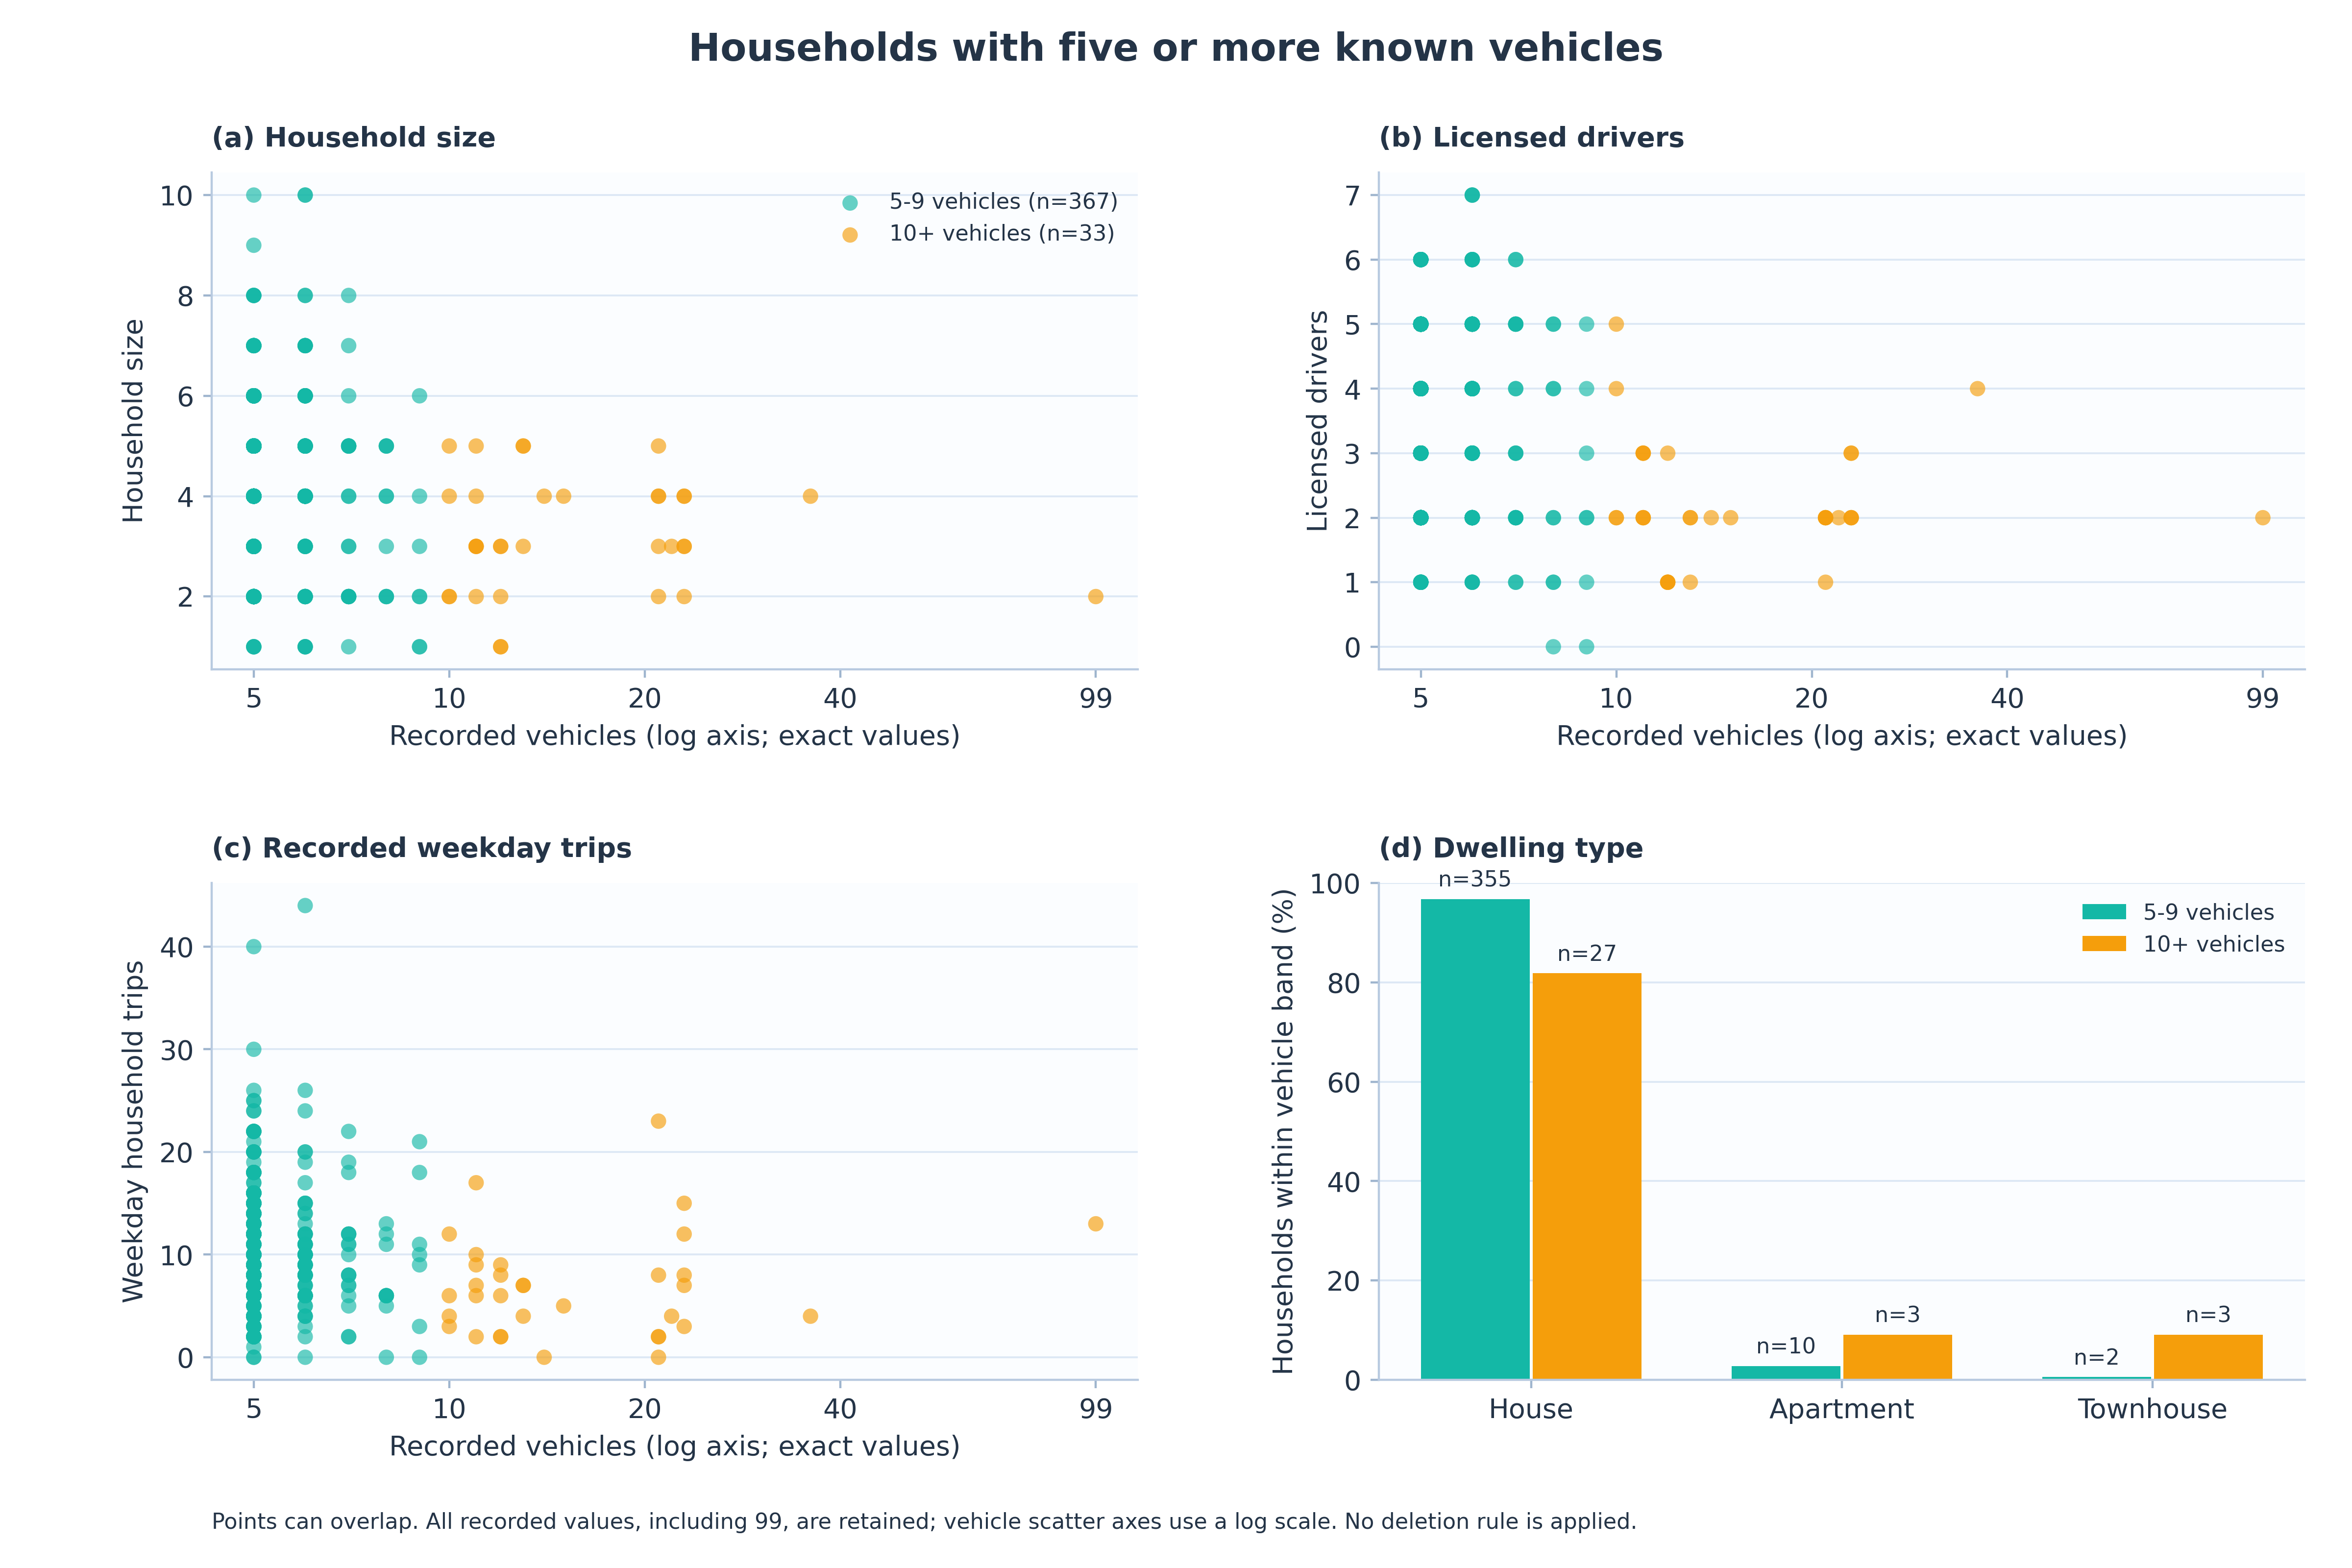

In [53]:
# Show the requested companion characteristics for the observed vehicle tail.
tail_plot = vehicle_review.loc[vehicle_review['nvehicle_clean'].ge(5).fillna(False)].copy()
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.subplots_adjust(left=.09, right=.98, bottom=.12, top=.89, hspace=.43, wspace=.26)
for ax, field, title in zip(axes.flat[:3], ['nperson', 'nlicence', 'nhhldtrip'],
                            ['(a) Household size', '(b) Licensed drivers', '(c) Recorded weekday trips']):
    for mask, colour, label in [
        (tail_plot['nvehicle_clean'].lt(10), AQUA, '5-9 vehicles'),
        (tail_plot['nvehicle_clean'].ge(10), ORANGE, '10+ vehicles')]:
        block = tail_plot.loc[mask]
        ax.scatter(block['nvehicle_clean'].astype(float), block[field].astype(float),
                   s=32, alpha=.65, color=colour, label=f'{label} (n={len(block):,})', edgecolors='none')
    ax.set_xlabel('Recorded vehicles (log axis; exact values)')
    ax.set_xscale('log')
    ax.set_ylabel(LABELS[field])
    ax.set_xticks([5, 10, 20, 40, 99], ['5', '10', '20', '40', '99'])
    ax.minorticks_off()
    panel(ax, title)
    style_axes(ax)
axes[0, 0].legend(frameon=False, fontsize=8)
ax = axes[1, 1]
dwelling_levels = ['House', 'Apartment', 'Townhouse']
x = np.arange(len(dwelling_levels))
for offset, mask, colour, label in [
    (-.18, tail_plot['nvehicle_clean'].lt(10), AQUA, '5-9 vehicles'),
    (.18, tail_plot['nvehicle_clean'].ge(10), ORANGE, '10+ vehicles')]:
    block = tail_plot.loc[mask]
    counts = block['dwelling'].value_counts().reindex(dwelling_levels, fill_value=0)
    bars = ax.bar(x + offset, 100 * counts / len(block), width=.35, color=colour, label=label)
    ax.bar_label(bars, labels=[f'n={v}' for v in counts], fontsize=8, padding=3)
ax.set_xticks(x, dwelling_levels)
ax.set_ylabel('Households within vehicle band (%)')
ax.set_ylim(0, 100)
ax.legend(frameon=False, fontsize=8)
panel(ax, '(d) Dwelling type')
style_axes(ax)
fig.suptitle('Households with five or more known vehicles', fontsize=14, fontweight='bold', color=INK)
fig.text(.09, .025, 'Points can overlap. All recorded values, including 99, are retained; vehicle scatter axes use a log scale. No deletion rule is applied.', fontsize=8, color=INK)
save_figure(fig, 'Figure_RV01_vehicle_household_review')

### Interpretation following the source dictionary

The earlier assumption that vehicle code 99 was missing is withdrawn. The guide publishes it as a numeric count, along with other large vehicle values. Review model sensitivity and influence while retaining the source-recorded baseline. Nine dwelling codes remain documented Unknowns; any complete-case requirement is model dependent. All source and historical split files are preserved.

In [54]:
rv10 = vehicle_review.loc[tail10]
missing_vehicle_rows = vehicle_review.loc[rv_missing_vehicle, ['source_excel_row', 'hnum', 'nvehicle']]
missing_dwelling_rows = vehicle_review.loc[rv_missing_dwelling, ['source_excel_row', 'hnum', 'dwelltype', 'nperson', 'nvehicle', 'nlicence', 'nhhldtrip']]
rv_base = rv_design_sensitivity.set_index('scenario').loc['Exact vehicles: all known values']
rv_no10 = rv_design_sensitivity.set_index('scenario').loc['Exact vehicles: omit >=10 sensitivity']
rv_peer_outside = int(high_vehicle_detail['trip_outside_peer_p05_p95'].fillna(False).sum())
rv_examples = high_vehicle_detail.merge(
    baseline_leverage[['hnum', 'design_leverage', 'leverage_over_average']], on='hnum', validate='one_to_one'
).nlargest(5, 'design_leverage')[
    ['source_excel_row', 'hnum', 'nperson', 'nvehicle', 'nlicence', 'nhhldtrip', 'dwelling', 'leverage_over_average']]
rv_report = f"""# Vehicle values, missing data, and predictor checks

All {len(analysis):,} households remain in EDA. These checks do not fit a trip-outcome regression, delete rows, or impute measurements. The supplied [2006 TTS Version 1.0 Data Guide](../inputs/dataguide2006_v1.pdf) supersedes the earlier provisional missing-value interpretation of vehicle 99. The workbook and historical split artifacts remain unchanged.

## Dictionary correction and exclusions

Printed page 18 (PDF page 23) defines n_vehicle as a numeric 0-99 count. Printed page 51 (PDF page 56) lists 99 with numeric description 99 and one 2006 record, alongside values including 21, 23, and 36. Vehicle 99 is retained numerically. Its source row, hnum=422873 at Excel row 27629, is a high-count sensitivity/influence case, not a missing-data omission candidate. Publication in the guide documents source occurrence; it does not independently validate each respondent's reported count.

There are {int(rv_missing_vehicle.sum())} missing vehicle measurements in this file. Dwelling code 9 is explicitly Unknown (printed p. 17 / PDF p. 22), affecting {int(rv_missing_dwelling.sum())} households:

{markdown_table(missing_dwelling_rows)}

Complete-case models using dwelling have {int(rv_known_both.sum()):,} households. Without that requirement, all {len(analysis):,} remain available for the checked numeric predictors. There is no automatic vehicle-missingness reduction. Unknown advance-letter code 9 does not require deletion when that survey-process variable is excluded. Do not generalize the meaning of 9/99 across fields: licence, employment, and student counts have documented numeric ranges including 9.

## Recorded vehicle tail

There are {len(rv10)} recorded vehicle counts of at least 10 ({100 * len(rv10) / len(analysis):.4f}% of the supplied sample), ranging from {int(rv10['nvehicle_clean'].min())} to {int(rv10['nvehicle_clean'].max())}. Their households contain {int(rv10['nperson'].min())}-{int(rv10['nperson'].max())} residents and {int(rv10['nlicence'].min())}-{int(rv10['nlicence'].max())} licensed drivers, with {int(rv10['nhhldtrip'].min())}-{int(rv10['nhhldtrip'].max())} trips. Dwelling counts: {', '.join(f'{k}: {v}' for k, v in rv10['dwelling'].value_counts().items())}.

Each record has an exact-size/licence/dwelling peer group restricted to fewer than 10 vehicles, with peer n ranging from {int(high_vehicle_detail['peer_n'].min()):,} to {int(high_vehicle_detail['peer_n'].max()):,}. Trips for {len(rv10) - rv_peer_outside} of {len(rv10)} records fall within the peers' descriptive 5th-95th percentile range. That range is not a confidence interval or statistical outlier test, and peers are truncated on vehicle values by design. Ordinary trips do not establish whether a high recorded vehicle count is accurate. Having more vehicles than residents/drivers is not logically impossible.

The guide's published extreme tail weakens the earlier suggestion that unusual counts alone indicate coding errors in this workbook. Keep the dictionary-consistent baseline. Examine influence, flexible vehicle forms, or explicitly labeled exclusion sensitivities; do not replace 99, 36, or 21 with guessed smaller values. The existing 10+ review threshold is not a verified boundary between valid and invalid observations.

## Leverage and VIF

The exact-vehicle design uses {int(rv_base['n']):,} complete cases and {int(rv_base['p_including_intercept'])} parameters including its intercept. It includes numeric 99. {int(rv_base['high_vehicle_n_above_3p_over_n'])} of the {int(rv_base['high_vehicle_n_in_design'])} high-vehicle households exceed the descriptive review line 3p/n. Maximum leverage is {rv_base['max_leverage']:.5f}, about {rv_base['max_leverage_over_average']:.1f} times average leverage. There are {int(rv_base['n_above_3p_over_n']):,} records above the review line overall. These are review markers, not deletion instructions.

{markdown_table(rv_examples.round(4))}

The maximum column VIF is {rv_base['max_column_VIF']:.3f}; the 10+ omission sensitivity gives {rv_no10['max_column_VIF']:.3f}. Low/moderate VIF cannot establish that individual extreme values are harmless. Leverage identifies unusual predictor combinations; influence on fitted coefficients also depends on residuals. Omitting 10+ values as a sensitivity reduces maximum leverage to {rv_no10['max_leverage']:.5f}, but removes source-recorded values and changes the analytical population. No such exclusion has been adopted.

Matrix rank and VIF should accompany substantive variable selection after categorical encoding. Do not include workers together with both nempft and nemppt: workers is their exact sum. The guide confirms home workers are already included in full-/part-time counts (p. 18), so a separate home-work coefficient is a conditional association, not an extra group to add into total workers. Employment and student statuses may overlap, and ages 6-10 are assumed students (p. 2); trips cover ages 11+ (pp. 1, 51).

## Other tails and fair model comparison

There are {int(vehicle_review['nperson'].ge(10).sum())} households with size at least 10 and {int(vehicle_review['nhhldtrip'].ge(30).sum())} with at least 30 trips. The guide's household/person-trip tables document rare large values as numeric counts. Keep zero-trip households and do not delete high outcomes to improve fit. Verify data where possible and assess residual/influence diagnostics after fitting.

{markdown_table(row_availability)}

Use the same agreed eligibility rule to compare regression and cross-classification. Size-by-licensed-driver classification does not itself require dwelling or vehicle data. Vehicle-based categories place recorded extremes in the top class; this limits numerical magnitude effects but does not validate the underlying measurement.

## Candidate-design sensitivities

{markdown_table(rv_design_sensitivity.drop(columns=['status']).round(5))}

Log1p/grouped vehicles and omission of vehicles are diagnostic alternatives, not selected final models. Most scenarios use identical complete cases. With the corrected coding there are no missing vehicle values, so the two vehicle-omission availability scenarios have the same sample size. Categorical controls use k-1 indicators with an intercept. Indicator-column VIFs are not factor-level generalized VIFs.

Next, fitted models require residual-versus-fitted/predictor checks, nonlinear alternatives, heteroskedasticity and appropriate uncertainty, studentized residuals, Cook's distance/DFBETAs, coefficient stability, implausible predictions, and household/zone agreement. Full-data fitting yields in-sample fit/error measures. The guide describes census-based expansion zones and later-phase multi-unit sampling adjustments (pp. 2, 4); state weighting conventions explicitly and apply expansion consistently to observed and predicted totals.

## Reproducible supporting files

RV01-RV02 contain vehicle-band and dwelling profiles; RV03 lists all high-vehicle households and peers; RV04 is the provisional decision ledger; RV05 gives availability counts; RV06 lists other extreme counts; RV07-RV10 give design/VIF/leverage sensitivities. Figure_RV01 plots the vehicle tail, including 99 on logarithmic scatter axes. Section 20 and DI01-DI03 reconcile the coding with the supplied guide and compare published full-survey frequencies with this four-region extract.
"""
(FINAL_OUTPUTS / 'vehicle_and_exclusion_review.md').write_text(rv_report, encoding='utf-8')
show(rv_examples.round(4))
print('Regenerated dictionary-informed vehicle review. Numeric 99 is retained; no rows removed.')
assert len(analysis) == len(master) == len(raw)
assert set(analysis['hnum']) == set(raw['hnum'])
assert row_availability['actual_rows_removed_from_EDA'].eq(0).all()
assert int(vehicle_band_profiles['households'].sum()) == len(analysis)
assert set(high_vehicle_detail['hnum']) == set(vehicle_review.loc[tail10, 'hnum'])
assert analysis.loc[analysis['nvehicle'].eq(99), 'nvehicle_clean'].eq(99).all()

,source_excel_row,hnum,nperson,nvehicle,nlicence,nhhldtrip,dwelling,leverage_over_average
32,27629,422873,2,99,2,13,House,1012.5467
31,47598,405266,4,36,4,4,House,120.9356
29,435,425500,2,23,2,3,Townhouse,51.4498
28,20874,383423,4,23,2,12,House,49.9072
27,62490,279731,4,23,2,8,House,48.8257


Regenerated dictionary-informed vehicle review. Numeric 99 is retained; no rows removed.


## 20. Reconcile coding with the supplied 2006 TTS data guide

Source: `inputs/dataguide2006_v1.pdf`, identical to the copy supplied in `intermediaries/chat`. Printed page numbers are five less than PDF page numbers. This section documents the correction to the earlier provisional vehicle-99 recode. The guide gives a 0-99 vehicle range (p. 18 / PDF p. 23), and its frequency table lists 99 as a numeric observation (p. 51 / PDF p. 56). Other fields must be interpreted individually: dwelling and advance-letter code 9 are documented Unknowns, while 9 in the household licence/employment/student count fields belongs to the numeric range. Large documented counts can still require model influence/functional-form checks, without being automatically treated as missing or erroneous.

In [55]:
guide_path = INPUTS / 'dataguide2006_v1.pdf'
assert guide_path.is_file(), 'The supplied source data guide is required for the dictionary reconciliation.'
guide_rows = [
    ('hnum', 'hhld_num', 'Six-digit household sample identifier', '16', '21', 'Identifier, not a substantive predictor'),
    ('gta01hhld', 'gta01_hhld', '2001 GTA zone system; retain 2001 regional ranges', '14, 16', '19, 21', 'Do not substitute 2006 zone ranges'),
    ('dwelltype', 'dwell_type', '1 House; 2 Apartment; 3 Townhouse; 9 Unknown', '17, 50', '22, 55', 'Only documented dwelling unknowns affect dwelling completeness'),
    ('rec-mail', 'rec_mail', 'Y Yes; N No; 9 Unknown / refused in tabulations', '17, 50', '22, 55', 'Survey-process field; no blanket row deletion'),
    ('n-call', 'n_call', 'Number of calls or edit attempts to complete interview', '17', '22', 'Survey-process variable; no undocumented missing code inferred'),
    ('tripday', 'trip_day', '1 Monday through 5 Friday; unknown 9 specified for 1986/1991', '18, 50', '23, 55', 'Observed 2006 weekdays 1-5; categorical control'),
    ('nperson', 'n_person', 'Numeric household size 1-99', '18, 50', '23, 55', 'Large sizes are not automatically codes for missing'),
    ('nvehicle', 'n_vehicle', 'Numeric vehicles 0-99; 99 explicitly tabulated as 99', '18, 51', '23, 56', 'Retain numeric 99; replace earlier missing-value assumption with sensitivity flag'),
    ('nlicence', 'n_licence', 'Numeric licensed-driver count 0-9', '18, 51', '23, 56', 'Numeric 9 is not automatically Unknown'),
    ('nempft', 'n_emp_ft', 'Numeric 0-9; includes full-time work-at-home persons since 1996', '18, 53', '23, 58', 'Do not double count home workers'),
    ('nemppt', 'n_emp_pt', 'Numeric 0-9; includes part-time work-at-home persons since 1996', '18, 53', '23, 58', 'Do not double count home workers'),
    ('nemphome', 'n_emp_home', 'Numeric 0-9, full-/part-time home workers', '18, 53', '23, 58', 'Overlaps full-/part-time counts'),
    ('nstudent', 'n_student', 'Numeric 0-9; ages 6-10 assumed full-time students; employment/student statuses can overlap', '2, 18, 53', '7, 23, 58', 'Overlap is not by itself an inconsistency'),
    ('nhhldtrip', 'n_hhld_trip', 'Numeric 0-99; 2006 recorded trips cover persons aged 11+', '1, 18, 51-52', '6, 23, 56-57', 'Retain zeros; acknowledge outcome age coverage'),
    ('expf', 'expf', 'Household expansion factor; expansion zones use census dwelling-unit controls', '2, 4, 18', '7, 9, 23', 'Not a substantive predictor; sampling/weighting convention must be explicit'),
]
guide_audit = save_review_table('DI01_dictionary_reconciliation', pd.DataFrame(guide_rows,
    columns=['project_field', 'guide_field', 'source_definition', 'printed_pages', 'PDF_pages', 'analysis_implication']))

# Transcribed from the 2006 n_vehicle column of printed p. 51 / PDF p. 56.
# The guide covers all 149,631 survey households, while this project has four regions.
published_2006_vehicle_counts = {
    0: 19889, 1: 59500, 2: 55027, 3: 11739, 4: 2716, 5: 521, 6: 124,
    7: 39, 8: 18, 9: 11, 10: 7, 11: 7, 12: 5, 13: 4, 14: 3,
    15: 2, 20: 1, 21: 6, 22: 1, 23: 7, 32: 2, 36: 1, 99: 1,
}
assert sum(published_2006_vehicle_counts.values()) == 149631
project_vehicle_counts = analysis['nvehicle_clean'].astype(int).value_counts()
guide_vehicle_comparison = pd.DataFrame([
    {'recorded_vehicle_count': level, 'guide_full_survey_2006_n': count,
     'project_four_region_n': int(project_vehicle_counts.get(level, 0)),
     'guide_description': str(level), 'documented_unknown_code': False,
     'source': '2006 TTS guide printed p. 51 / PDF p. 56'}
    for level, count in published_2006_vehicle_counts.items()])
assert set(project_vehicle_counts.index) <= set(published_2006_vehicle_counts)
assert guide_vehicle_comparison['project_four_region_n'].le(guide_vehicle_comparison['guide_full_survey_2006_n']).all()
assert guide_vehicle_comparison['project_four_region_n'].sum() == len(analysis)
save_review_table('DI02_published_vehicle_frequencies', guide_vehicle_comparison)

# Exhibit 3, printed p. 5 / PDF p. 10, gives these household record counts.
guide_region_records = {'Toronto': 51612, 'Durham': 9527, 'York': 14223, 'Peel': 17945}
guide_scope_check = pd.DataFrame([
    {'region': region, 'guide_household_records': count,
     'project_household_records': int(analysis['region'].eq(region).sum()),
     'source': '2006 TTS guide Exhibit 3, printed p. 5 / PDF p. 10'}
    for region, count in guide_region_records.items()])
assert guide_scope_check['project_household_records'].eq(guide_scope_check['guide_household_records']).all()
save_review_table('DI03_source_region_counts', guide_scope_check)

assert analysis['nvehicle_clean'].notna().all()
assert analysis['nvehicle_clean'].astype(int).equals(pd.to_numeric(raw['nvehicle']).astype(int))
assert analysis.loc[analysis['vehicle_99_review'], 'nvehicle_clean'].eq(99).all()
assert analysis['eligible_core'].all()
assert int(analysis['eligible_comparison'].sum()) == len(analysis) - int(analysis['unknown_dwelling'].sum())
show(guide_audit)
show(guide_vehicle_comparison.loc[guide_vehicle_comparison['recorded_vehicle_count'].ge(10)])
show(guide_scope_check)
print('Dictionary correction verified: 99 is retained numerically; all recorded vehicle values remain available.')
print('High-vehicle review records:', int(analysis['high_vehicle'].sum()))
print('Documented dwelling Unknowns:', int(analysis['unknown_dwelling'].sum()))
print('No original rows deleted and no source values guessed or overwritten.')

,project_field,guide_field,source_definition,printed_pages,PDF_pages,analysis_implication
0,hnum,hhld_num,Six-digit household sample identifier,16,21,"Identifier, not a substantive predictor"
1,gta01hhld,gta01_hhld,2001 GTA zone system; retain 2001 regional ranges,"14, 16","19, 21",Do not substitute 2006 zone ranges
2,dwelltype,dwell_type,1 House; 2 Apartment; 3 Townhouse; 9 Unknown,"17, 50","22, 55",Only documented dwelling unknowns affect dwell...
3,rec-mail,rec_mail,Y Yes; N No; 9 Unknown / refused in tabulations,"17, 50","22, 55",Survey-process field; no blanket row deletion
4,n-call,n_call,Number of calls or edit attempts to complete i...,17,22,Survey-process variable; no undocumented missi...
5,tripday,trip_day,1 Monday through 5 Friday; unknown 9 specified...,"18, 50","23, 55",Observed 2006 weekdays 1-5; categorical control
6,nperson,n_person,Numeric household size 1-99,"18, 50","23, 55",Large sizes are not automatically codes for mi...
7,nvehicle,n_vehicle,Numeric vehicles 0-99; 99 explicitly tabulated...,"18, 51","23, 56",Retain numeric 99; replace earlier missing-val...
8,nlicence,n_licence,Numeric licensed-driver count 0-9,"18, 51","23, 56",Numeric 9 is not automatically Unknown
9,nempft,n_emp_ft,Numeric 0-9; includes full-time work-at-home p...,"18, 53","23, 58",Do not double count home workers


,recorded_vehicle_count,guide_full_survey_2006_n,project_four_region_n,guide_description,documented_unknown_code,source
10,10,7,4,10,False,2006 TTS guide printed p. 51 / PDF p. 56
11,11,7,6,11,False,2006 TTS guide printed p. 51 / PDF p. 56
12,12,5,5,12,False,2006 TTS guide printed p. 51 / PDF p. 56
13,13,4,3,13,False,2006 TTS guide printed p. 51 / PDF p. 56
14,14,3,1,14,False,2006 TTS guide printed p. 51 / PDF p. 56
15,15,2,1,15,False,2006 TTS guide printed p. 51 / PDF p. 56
16,20,1,0,20,False,2006 TTS guide printed p. 51 / PDF p. 56
17,21,6,5,21,False,2006 TTS guide printed p. 51 / PDF p. 56
18,22,1,1,22,False,2006 TTS guide printed p. 51 / PDF p. 56
19,23,7,5,23,False,2006 TTS guide printed p. 51 / PDF p. 56


,region,guide_household_records,project_household_records,source
0,Toronto,51612,51612,"2006 TTS guide Exhibit 3, printed p. 5 / PDF p..."
1,Durham,9527,9527,"2006 TTS guide Exhibit 3, printed p. 5 / PDF p..."
2,York,14223,14223,"2006 TTS guide Exhibit 3, printed p. 5 / PDF p..."
3,Peel,17945,17945,"2006 TTS guide Exhibit 3, printed p. 5 / PDF p..."


Dictionary correction verified: 99 is retained numerically; all recorded vehicle values remain available.
High-vehicle review records: 33
Documented dwelling Unknowns: 9
No original rows deleted and no source values guessed or overwritten.


## 21. User-approved modeling exclusion: household with 99 vehicles

The user explicitly requested omission of household `hnum=422873` from modeling because of its extreme recorded vehicle count. This is an analytical outlier decision, not a missing-code interpretation. The source dictionary and full-source EDA above continue to retain the recorded numeric 99. The original workbook and prepared master remain unchanged.

The modeling input below omits this one household. No additional high-vehicle cutoff has been adopted, no other rows are dropped, and no regression or feature-selection procedure is run. Known-dwelling eligibility remains a separate model-specific decision. Historical split files are preserved and unused.

In [56]:
# A single explicit user-directed exclusion, keyed by household ID for traceability.
approved_modeling_exclusions = pd.DataFrame([{
    'hnum': 422873, 'field': 'nvehicle', 'recorded_value': 99,
    'source_excel_row': 27629, 'dwelling': 'House',
    'reason': 'User-requested exclusion of extreme recorded vehicle count',
    'decision_source': 'Explicit user instruction', 'scope': 'Modeling only',
}])
excluded_ids = approved_modeling_exclusions['hnum']
excluded_record = analysis.loc[analysis['hnum'].isin(excluded_ids)]
assert len(excluded_record) == 1 and excluded_record['nvehicle'].eq(99).all()
assert excluded_record['dwelling'].eq('House').all()
modeling = analysis.loc[~analysis['hnum'].isin(excluded_ids)].copy()
assert len(modeling) == len(analysis) - 1
assert not modeling['hnum'].isin(excluded_ids).any()
assert modeling['hnum'].is_unique
assert set(modeling['hnum']) | set(excluded_ids) == set(analysis['hnum'])
approved_modeling_exclusions.to_csv(INTERMEDIARIES / 'modeling_exclusions.csv', index=False)
modeling.to_csv(INTERMEDIARIES / 'households_modeling.csv', index=False,
                encoding='utf-8-sig', lineterminator='\n', float_format='%.15g')
modeling_input_summary = pd.DataFrame([
    {'view': 'Full source EDA / prepared master', 'households': len(analysis)},
    {'view': 'Modeling input: exclude approved 99-vehicle household only', 'households': len(modeling)},
    {'view': 'If a model additionally requires known dwelling',
     'households': int(modeling['dwelltype_clean'].notna().sum())},
])
show(approved_modeling_exclusions)
show(modeling_input_summary)
print('Saved households_modeling.csv and modeling_exclusions.csv. No other exclusions or feature selection applied.')

# Earlier reports describe their labeled full-source diagnostic samples. Record
# the subsequent user decision so their baseline is not mistaken for model input.
decision_note = f"""

## Subsequent explicit modeling decision

The user has requested exclusion of hnum=422873 (recorded nvehicle=99; House; Excel row 27629) from modeling. The current input is intermediaries/households_modeling.csv with {len(modeling):,} households; modeling_exclusions.csv records the reason. If known dwelling is required, {int(modeling['dwelltype_clean'].notna().sum()):,} are available. The full-source EDA and prepared master above retain all {len(analysis):,} source households, and earlier diagnostic samples retain their stated definitions. Recompute model-selection diagnostics on the final agreed common modeling sample. Broader vehicle-tail exclusions and the feature-selection procedure remain undecided; no regression has been fitted.
"""
for report_name in ['MLR_preparation_review.md', 'vehicle_and_exclusion_review.md']:
    report_path = FINAL_OUTPUTS / report_name
    existing = report_path.read_text(encoding='utf-8')
    existing = existing.split('\n\n## Subsequent explicit modeling decision')[0]
    report_path.write_text(existing.rstrip() + decision_note, encoding='utf-8')


Saved households_modeling.csv and modeling_exclusions.csv. No other exclusions or feature selection applied.


,hnum,field,recorded_value,source_excel_row,dwelling,reason,decision_source,scope
0,422873,nvehicle,99,27629,House,User-requested exclusion of extreme recorded v...,Explicit user instruction,Modeling only


,view,households
0,Full source EDA / prepared master,93307
1,Modeling input: exclude approved 99-vehicle ho...,93306
2,If a model additionally requires known dwelling,93297
